<a href="https://colab.research.google.com/github/rercampos/dme-fundus-oct/blob/main/dme_fundus_oct.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detecção do Edema Macular Diabético com Inteligência Artificial
### Retinografia, OCT e Redes Neurais: ResNet50, DenseNet121 e Vision Transformer

## O problema

O **Edema Macular Diabético (DME)** é um inchaço na região central da retina (a mácula), causado pelo diabetes. É uma das principais causas de perda de visão em pessoas com diabetes. Detectado cedo, pode ser tratado.

Dois exames são usados para investigar o olho do paciente diabético:

- **Retinografia (foto do fundo de olho):** barata, rápida e disponível em muitos lugares. Mostra a retina "de frente".
- **OCT (Tomografia de Coerência Óptica):** mostra as camadas da retina "em corte", e por isso enxerga o inchaço diretamente. Mas é um exame caro, e muitas clínicas não têm o equipamento.

## A pergunta deste trabalho

> É possível usar redes neurais para detectar o DME nessas imagens? E a OCT pode ajudar a retinografia a detectar melhor a doença, ou vice-versa?

Se a OCT conseguir "ensinar" um modelo que depois funcione **apenas com a retinografia**, o rastreamento poderia chegar a locais onde não existe OCT.

## A base de dados

Usamos a base pública **OCT-AND-EYE-FUNDUS-DATASET** (Hughes-Cano et al., 2024), com **1.548 retinografias** e **1.113 OCTs** avaliadas por oftalmologistas. Para parte dos pacientes existem **os dois exames do mesmo olho**, o que permite comparar e combinar as duas modalidades.

## O que será feito

1. **Conhecer e auditar a base:** verificar se os dados permitem uma comparação justa e como as classes estão distribuídas.
2. **Preparar as imagens:** cortar bordas, realçar o contraste e reduzir ruído, e verificar se esse preparo realmente ajuda.
3. **Treinar três redes neurais pré-treinadas:** duas convolucionais tradicionais (**ResNet50** e **DenseNet121**) e uma arquitetura mais recente, o **Vision Transformer (ViT)**, com os hiperparâmetros escolhidos por ***grid search***.
4. **Comparar retinografia, OCT e as duas juntas (fusão)**, para medir quanto uma modalidade ajuda a outra.
5. **Classificar o grau da retinopatia diabética** (sem retinopatia, não proliferativa e proliferativa), com foco na detecção precoce.
6. **Explicar as decisões das redes** com o **Grad-CAM**, um mapa de calor que mostra para onde a rede "olhou" na imagem.
7. **Comparar os resultados com a literatura científica.**

## Um achado importante logo no início

Na primeira versão deste trabalho, as redes acertaram cerca de **97%**. Ao investigar a base, descobrimos que quase todas as imagens **com** edema vieram de um grupo de pacientes fotografados com **outro equipamento** (imagens mais escuras e com outra coloração), enquanto as imagens **sem** edema vieram de outro grupo.

Um teste simples confirmou o problema: um programa que analisa **apenas as cores da foto**, sem enxergar nenhuma lesão, acertou praticamente tanto quanto as redes neurais. Ou seja, as redes podiam estar reconhecendo **a câmera**, e não **a doença**.

Por isso, nesta versão, os experimentos usam apenas o grupo de pacientes em que as imagens com e sem edema têm **a mesma origem** (coorte B). É também nesse grupo que estão os **410 olhos com retinografia e OCT do mesmo olho** (51 com edema).

## Principais resultados

- **As redes reconhecem o edema na retinografia** (AUC de 0,941 a 0,962), muito acima de um classificador baseado apenas em cor (0,785).
- **A OCT melhora a detecção do edema a partir da retinografia:** a fusão tardia dos dois exames aumentou a AUC de forma estatisticamente significativa nas três arquiteturas (+0,017 a +0,043), e a sensibilidade passou de 72%–84% (apenas retinografia) para 86%–90%.
- **Esse ganho foi ainda maior na análise de robustez** (pacientes 1957 a 2056), cenário mais difícil para a retinografia, em que a cor da imagem não distingue as classes (AUC 0,541).
- **Grau da retinopatia:** a retinografia foi superior à OCT para **graduar** a doença (Kappa quadrático de 0,616 a 0,679, contra 0,552 a 0,642), enquanto para **detectar qualquer grau** de retinopatia as duas foram semelhantes (AUC de 0,878 a 0,932). O *grid search* melhorou o desempenho da OCT, mas a limitação parece estar no tipo de imagem (um único corte da mácula).
- **O pré-processamento das imagens não trouxe benefício consistente** em relação às imagens originais.

## Guia do notebook

| Seção | Conteúdo | Pergunta do professor |
|---|---|---|
| §1 | Carregamento dos dados | |
| §2 | Auditoria da base e o problema da câmera | 5 |
| §3 | Preparação das imagens | 1 |
| §4 | Divisão dos pacientes, classes e desbalanceamento (4.2) | 5 e 6 |
| §5 | Redes pré-treinadas (5.1) e *grid search* (5.3) | 2 |
| §6 | Experimentos: retinografia, OCT, fusão e grau da retinopatia | 3 |
| §7 | Resultados, robustez (7.8) e efeito do pré-processamento (7.9) | 1, 3, 5 e 6 |
| §8 | Casos reais lado a lado com Grad-CAM | 4 |
| §9 | Comparação com a literatura | 1 e 6 |
| §10 | Limitações | |

## Preparação do ambiente

Esta seção funciona como o "painel de controle" do trabalho: todas as configurações ficam reunidas aqui, em um só lugar.

**Modo de teste rápido**
- `MODO_RAPIDO = True`: executa uma versão reduzida, só para verificar se o notebook funciona sem erros (poucos minutos).
- `MODO_RAPIDO = False`: executa o experimento completo (algumas horas, com GPU).

**Salvamento automático**
Os resultados são salvos no Google Drive ao longo da execução. Se o Colab desconectar, basta rodar novamente: o notebook continua de onde parou.

### Instalação de bibliotecas adicionais

O Google Colab já traz a maioria das bibliotecas necessárias. Aqui é instalada apenas a biblioteca **grad-cam**, utilizada mais adiante para gerar os mapas de calor (Grad-CAM) que mostram em quais regiões da imagem cada rede neural se baseou para tomar sua decisão.

In [ ]:
!pip -q install grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### Importação das bibliotecas

São carregadas as bibliotecas utilizadas ao longo do trabalho:

- **NumPy e Pandas:** cálculos numéricos e manipulação das tabelas (arquivos CSV) da base de dados.
- **Matplotlib:** gráficos e visualização das imagens.
- **PIL e OpenCV:** leitura e tratamento das imagens (recorte, realce de contraste e redução de ruído).
- **Scikit-learn:** divisão dos pacientes em grupos de treino e teste, classificador de referência e cálculo das métricas de desempenho (acurácia, sensibilidade, especificidade, AUC, entre outras).

In [ ]:
import os, glob, json, copy, random, math, time, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, recall_score, precision_score,
                             f1_score, roc_auc_score, average_precision_score, cohen_kappa_score,
                             matthews_corrcoef, confusion_matrix, roc_curve, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 200)

### Conexão com o Google Drive

O ambiente do Colab é temporário: ao ser desconectado, todos os arquivos gerados são apagados. Por isso, o Google Drive é conectado ao ambiente, e todos os resultados (tabelas, gráficos e modelos treinados) são salvos nele de forma permanente.

Isso também permite retomar o experimento caso a sessão seja interrompida, sem a necessidade de repetir etapas já concluídas.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Parâmetros do experimento

Todos os parâmetros do estudo são definidos nesta célula, em um único lugar. Isso facilita a reprodução do experimento e permite alterar qualquer configuração sem procurar ao longo do código.

**Principais definições:**

- **Modo de execução:** `MODO_RAPIDO = True` executa uma versão reduzida para verificação do código; `False` executa o experimento completo.
- **Reprodutibilidade:** uma semente aleatória fixa (`SEED = 42`) garante que os sorteios (divisão dos pacientes, inicialização das redes) sejam sempre os mesmos, de forma que o experimento possa ser repetido com os mesmos resultados.
- **Validação cruzada:** os pacientes são divididos em **5 grupos (folds)**. Cada grupo é usado uma vez como teste, enquanto os outros quatro são usados no treinamento.
- **Imagens:** redimensionadas para **224 × 224 pixels**, tamanho exigido pelas redes pré-treinadas utilizadas.
- **Treinamento:** as imagens são processadas em lotes de **32** (*batch size*), por no máximo **25 épocas**. O treinamento é interrompido automaticamente se o desempenho na validação não melhorar por 6 épocas seguidas (*early stopping*), evitando que a rede "decore" as imagens de treino.
- **Arquiteturas avaliadas:** ResNet50, DenseNet121 e Vision Transformer (ViT-B/16).
- **Taxa de aprendizado (*learning rate*):** valores iniciais baseados na literatura, posteriormente ajustados por uma busca sistemática (Seção 5).
- **Pré-processamento das retinografias:** realce de contraste por CLAHE (Seção 3).
- **Etapas opcionais:** fusão das duas modalidades de imagem, ensino da rede de retinografia pela OCT (destilação) e classificação do grau da retinopatia.

In [ ]:
MODO_RAPIDO = False          # True = só fold 0 e poucas épocas (teste do pipeline)
USAR_DRIVE = True            # salva resultados no Google Drive

RAIZ = '/content/OCT-AND-EYE-FUNDUS-DATASET'
PASTA = 'DME_em_andamento_teste' if MODO_RAPIDO else 'DME_em_andamento'
SAIDA = f'/content/drive/MyDrive/{PASTA}' if USAR_DRIVE else f'/content/{PASTA}'

SEED = 42
N_FOLDS = 5                  # validação cruzada por paciente
FOLDS = [0] if MODO_RAPIDO else list(range(N_FOLDS))

IMG = 224                    # entrada das redes (exigência do ViT-B/16 pré-treinado)
CACHE = 256                  # resolução das imagens pré-processadas mantidas em memória
BATCH = 32                   # lote padrão (substituído pelo grid search, Seção 5.3)
BATCH_FUSAO = 16             # dois backbones simultâneos -> metade do lote
EPOCAS_MAX = 6 if MODO_RAPIDO else 25
PACIENCIA = 3 if MODO_RAPIDO else 6   # early stopping na perda de validação

ARQS = ['resnet50', 'densenet121', 'vit_b_16']
NOME = {'resnet50': 'ResNet50', 'densenet121': 'DenseNet121', 'vit_b_16': 'ViT-B/16'}

# Taxas de aprendizado padrão (usadas apenas se o grid search não for executado)
LR = {'resnet50': 3e-4, 'densenet121': 3e-4, 'vit_b_16': 3e-5}
WD = {'resnet50': 1e-4, 'densenet121': 1e-4, 'vit_b_16': 0.05}

# Grid search (Seção 5.3): taxa de aprendizado × tamanho do lote,
# separado por modalidade (retinografia, OCT), tarefa (edema, grau) e arquitetura
GRID_SEARCH = True
GRID_LR = [1e-4, 3e-4] if MODO_RAPIDO else [1e-5, 3e-5, 1e-4, 3e-4, 1e-3]
GRID_BATCH = [16, 32]
FOLDS_GRID = [0] if MODO_RAPIDO else [0, 1]     # rodadas usadas na escolha (média das perdas)
EPOCAS_GRID = 4 if MODO_RAPIDO else 10
HP = {}                      # hiperparâmetros escolhidos: (modalidade, tarefa, arq) -> {'lr', 'batch'}

PREPROC_FUNDO = 'clahe'      # 'nenhum' | 'clahe' | 'ben'

# Destilação OCT -> fundo (§6.3)
ARQ_PROFESSOR = 'resnet50'
KD_T = 2.0
KD_ALPHA = 0.5

FUSAO_INTERMEDIARIA = True
DR_TAMBEM = True             # executa a tarefa de grau da retinopatia (§6.4)

os.makedirs(os.path.join(SAIDA, 'predicoes'), exist_ok=True)
os.makedirs(os.path.join(SAIDA, 'modelos'), exist_ok=True)
os.makedirs(os.path.join(SAIDA, 'figuras'), exist_ok=True)

def fixar_semente(s=SEED):
    random.seed(s); np.random.seed(s)
    try:
        import torch
        torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    except ImportError:
        pass
fixar_semente()
print('Resultados serão salvos em:', SAIDA)

Resultados serão salvos em: /content/drive/MyDrive/DME_em_andamento


### Configuração do PyTorch e da GPU

É carregado o **PyTorch**, biblioteca utilizada para construir e treinar as redes neurais, junto com o **Torchvision**, que fornece as arquiteturas ResNet50, DenseNet121 e ViT-B/16 já pré-treinadas no conjunto ImageNet (*transfer learning*).

O código verifica se há uma **GPU** disponível, que acelera o treinamento em dezenas de vezes em relação ao processador comum. Também é ativado o treinamento em **precisão mista**, que realiza parte dos cálculos com menor número de casas decimais, reduzindo o tempo de treino e o uso de memória sem prejuízo ao desempenho dos modelos.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USAR_AMP = device.type == 'cuda'
NW = 2                       # workers do DataLoader no Colab
print('Dispositivo:', device, torch.cuda.get_device_name(0) if USAR_AMP else '')
torch.backends.cudnn.benchmark = True

def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USAR_AMP)

def novo_scaler():
    try:
        return torch.amp.GradScaler('cuda', enabled=USAR_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USAR_AMP)

Dispositivo: cuda Tesla T4


## 1. Dados

A base **OCT-AND-EYE-FUNDUS-DATASET** é obtida diretamente do repositório oficial dos autores no GitHub, o que torna o experimento reproduzível sem a necessidade de upload manual das imagens.

A base é composta por duas planilhas:

- `EYE FUNDUS.csv`: informações das **1.548 retinografias**;
- `OCT.csv`: informações das **1.113 imagens de OCT**.

Para cada imagem são informados o diagnóstico de **Edema Macular Diabético** (`DME`: 1 = presente, 0 = ausente) e o grau de **Retinopatia Diabética** (`DR`: `0` = sem retinopatia, `NPDR` = não proliferativa, `PDR` = proliferativa, `-` = não informado), definidos por oftalmologistas especialistas em retina.

### Identificação de paciente e olho

O nome de cada arquivo segue o padrão `paciente_olho_modalidade_amostra`. Por exemplo, `1221_OD_f_3` corresponde à 3ª retinografia (`f`) do olho direito (`OD`) do paciente 1221. Para o olho esquerdo é usado `OI`, e para a OCT, `o`.

A partir do nome são extraídos o **paciente** e o **olho**. Essa informação é essencial por dois motivos:

1. **Evitar vazamento de dados:** todas as imagens de um mesmo paciente devem ficar no mesmo grupo (treino ou teste), para que a rede não seja avaliada em um paciente que já "viu" no treino.
2. **Parear as modalidades:** identificar os olhos que possuem **retinografia e OCT**, permitindo comparar e combinar os dois exames.

Também é verificado se todas as imagens listadas nas planilhas existem nas pastas da base.

In [ ]:
if not os.path.isdir(RAIZ):
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/Traslational-Visual-Health-Laboratory/OCT-AND-EYE-FUNDUS-DATASET.git',
                    RAIZ], check=True)

def carregar(csv, pasta):
    df = pd.read_csv(os.path.join(RAIZ, csv))
    df['Name'] = df['Name'].astype(str).str.strip()
    arquivos = glob.glob(os.path.join(RAIZ, pasta, '**', '*.jpg'), recursive=True)
    caminhos = {os.path.splitext(os.path.basename(p))[0]: p for p in arquivos}
    df['caminho'] = df['Name'].map(caminhos)
    assert df['caminho'].notna().all(), 'Há imagens do CSV sem arquivo'
    partes = df['Name'].str.split('_')
    df['Paciente'] = partes.str[0]
    df['Olho'] = partes.str[1]
    df['olho_id'] = df['Paciente'] + '_' + df['Olho']
    df['pid'] = df['Paciente'].astype(int)
    df['DR'] = df['DR'].fillna('-').astype(str).str.strip()
    df['DR_graduado'] = df['DR'].isin(['0', 'NPDR', 'PDR'])
    df['DR_cls'] = df['DR'].map({'0': 0, 'NPDR': 1, 'PDR': 2})
    df['DME'] = df['DME'].astype(int)
    return df

fundo = carregar('EYE FUNDUS.csv', 'EYE FUNDUS')
octs = carregar('OCT.csv', 'OCT')

print(f'Retinografias: {len(fundo)} imagens | {fundo.Paciente.nunique()} pacientes | {fundo.olho_id.nunique()} olhos')
print(f'OCT:           {len(octs)} imagens | {octs.Paciente.nunique()} pacientes | {octs.olho_id.nunique()} olhos')
olhos_comuns = set(fundo.olho_id) & set(octs.olho_id)
print(f'Olhos com retinografia E OCT: {len(olhos_comuns)} '
      f'({len(set(fundo.Paciente) & set(octs.Paciente))} pacientes)')

Retinografias: 1548 imagens | 1174 pacientes | 1395 olhos
OCT:           1113 imagens | 831 pacientes | 1044 olhos
Olhos com retinografia E OCT: 414 (217 pacientes)


### Resultado do carregamento

Todas as imagens listadas nas planilhas foram encontradas nas pastas da base.

| Modalidade | Imagens | Pacientes | Olhos |
|---|---|---|---|
| Retinografia | 1.548 | 1.174 | 1.395 |
| OCT | 1.113 | 831 | 1.044 |

O número de imagens é maior que o número de pacientes porque alguns pacientes possuem imagens dos dois olhos ou mais de uma imagem do mesmo olho.

**414 olhos (de 217 pacientes) possuem retinografia e OCT.** Esse subconjunto pareado é o que permite avaliar a contribuição de cada modalidade e a combinação das duas.

## 2. Auditoria da base de dados

Antes de treinar qualquer rede neural, é necessário verificar se a base permite uma comparação justa. Um problema comum em bases médicas é o **viés de coorte**: quando imagens de classes diferentes (com e sem doença) vêm de origens diferentes, por exemplo de clínicas, equipamentos ou períodos distintos. Nesse caso, a rede pode aprender a reconhecer **a origem da imagem** em vez da **doença**, e apresentar um desempenho artificialmente alto.

### 2.1 Distribuição das imagens por origem

As retinografias são separadas em dois grupos, de acordo com a informação de retinopatia:

- **Coorte A:** imagens cujo grau de retinopatia **não foi informado** (`DR = -`);
- **Coorte B:** imagens com grau de retinopatia **informado** (sem RD, RDNP ou RDP).

As tabelas a seguir cruzam essa separação com o diagnóstico de edema e com a numeração dos pacientes, para verificar se as duas classes (com e sem DME) têm a mesma origem.

In [ ]:
fundo['coorte'] = np.where(fundo['DR_graduado'], 'B: RD graduada', 'A: RD desconhecida')
print('Retinografia: DR x DME')
display(pd.crosstab(fundo['DR'], fundo['DME'], margins=True))
print('\nRetinografia: coorte x DME')
display(pd.crosstab(fundo['coorte'], fundo['DME'], margins=True))
print('\nFaixa de IDs de paciente por coorte e DME')
display(fundo.groupby(['coorte', 'DME'])['pid'].agg(['count', 'min', 'max']))
print('\nOCT: DR x DME')
display(pd.crosstab(octs['DR'], octs['DME'], margins=True))

Retinografia: DR x DME


DME,0,1,All
DR,,,
-,4,999,1003
0,398,0,398
NPDR,69,26,95
PDR,24,28,52
All,495,1053,1548



Retinografia: coorte x DME


DME,0,1,All
coorte,,,
A: RD desconhecida,4,999,1003
B: RD graduada,491,54,545
All,495,1053,1548



Faixa de IDs de paciente por coorte e DME


count   min   max
coorte             DME                   
A: RD desconhecida 0        4  2029  2032
                   1      999     1  1220
B: RD graduada     0      491  1221  2056
                   1       54  1957  2054


OCT: DR x DME


DME,0,1,All
DR,,,
-,529,71,600
0,341,0,341
NPDR,52,67,119
PDR,24,29,53
All,946,167,1113


### Interpretação das tabelas

**As duas classes de DME têm origens diferentes.** Das 1.053 retinografias com edema, **999 pertencem à coorte A** (grau de retinopatia não informado, pacientes 1 a 1220). Já as imagens sem edema estão quase todas na **coorte B** (491 de 495, pacientes 1221 a 2056).

| Coorte | Sem DME | Com DME |
|---|---|---|
| A: grau de RD não informado | 4 | 999 |
| B: grau de RD informado | 491 | 54 |

Isso significa que, na base completa, **a classe de edema está quase totalmente associada ao grupo de origem da imagem**. Uma rede neural treinada com todas as imagens pode, portanto, aprender a distinguir os grupos (por exemplo, pelas características da câmera) em vez de identificar o edema.

Outras observações:

- Todas as imagens sem retinopatia (DR = 0) também não apresentam edema, o que é coerente do ponto de vista clínico.
- As imagens de OCT pertencem todas a pacientes a partir do número 1221, ou seja, ao mesmo grupo da coorte B.
- A coorte B contém **545 retinografias, sendo 54 com edema**, em que as duas classes têm a mesma origem. É nela que estão os pacientes com retinografia e OCT do mesmo olho.

O artigo dos autores da base (Hughes-Cano et al., 2024) confirma que as retinografias sem edema foram reunidas a partir de fontes diferentes das retinografias com edema.

### 2.2 Inspeção visual
 Para verificar se a diferença de origem também é visível, são exibidos exemplos de retinografias de três grupos: coorte A com edema, coorte B sem edema e coorte B com edema.    

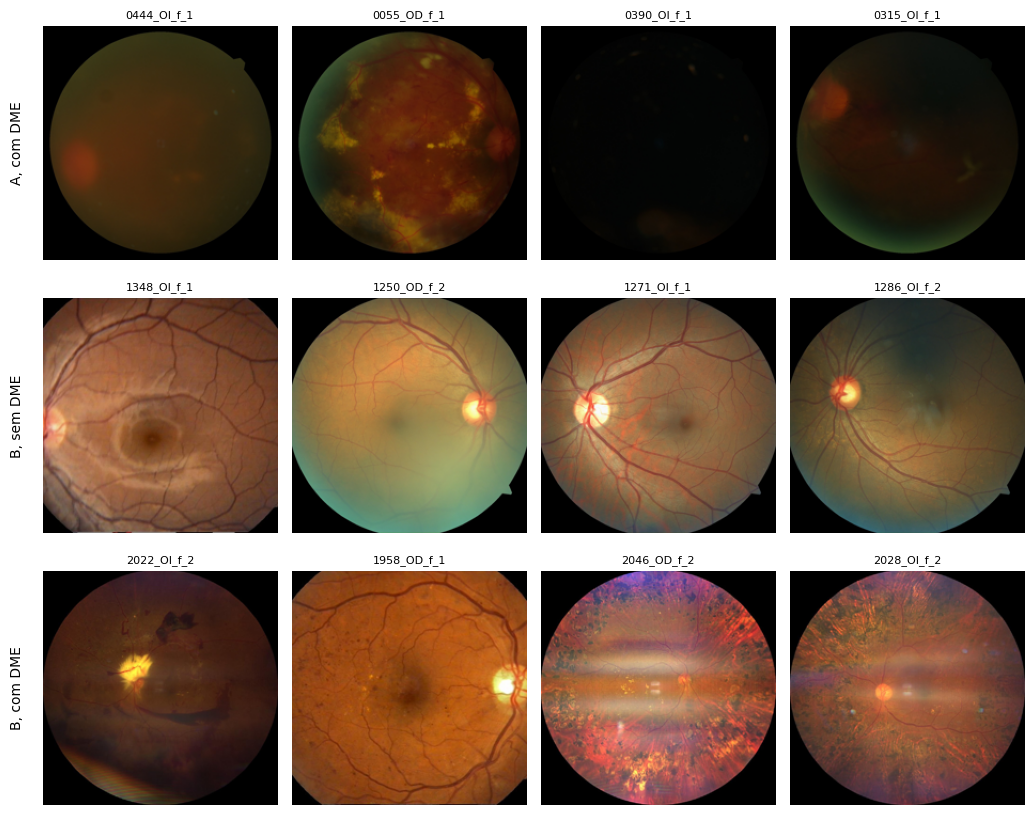

In [ ]:
def mostrar_grade(dfs, titulos, n=4, tam=220, semente=1, arquivo=None):
    fig, axes = plt.subplots(len(dfs), n, figsize=(n * 2.6, len(dfs) * 2.8))
    for i, (d, t) in enumerate(zip(dfs, titulos)):
        amostra = d.sample(min(n, len(d)), random_state=semente)
        for j in range(n):
            ax = axes[i, j]; ax.axis('off')
            if j < len(amostra):
                r = amostra.iloc[j]
                ax.imshow(Image.open(r['caminho']).convert('RGB').resize((tam, tam)))
                ax.set_title(r['Name'], fontsize=8)
        axes[i, 0].text(-0.08, 0.5, t, transform=axes[i, 0].transAxes, rotation=90,
                        va='center', ha='right', fontsize=10)
    plt.tight_layout()
    if arquivo: plt.savefig(arquivo, dpi=150, bbox_inches='tight')
    plt.show()

mostrar_grade(
    [fundo[(fundo.coorte.str.startswith('A')) & (fundo.DME == 1)],
     fundo[(fundo.coorte.str.startswith('B')) & (fundo.DME == 0)],
     fundo[(fundo.coorte.str.startswith('B')) & (fundo.DME == 1)]],
    ['A, com DME', 'B, sem DME', 'B, com DME'],
    arquivo=os.path.join(SAIDA, 'figuras', 'coortes.png'))

### Interpretação visual

As retinografias da **coorte A** (linha superior) são visivelmente **mais escuras e com menor nitidez**, com tonalidade diferente das demais, e algumas imagens estão quase sem iluminação. Isso indica que essas imagens provavelmente foram obtidas com **outro equipamento ou protocolo de captura**. Como quase todas as imagens com edema da base pertencem a essa coorte, a rede poderia aprender a reconhecer essas características de aquisição em vez do edema.

As imagens da **coorte B sem edema** (linha do meio) apresentam boa iluminação e nitidez, com vasos e disco óptico bem definidos.

Entre as imagens da **coorte B com edema** (linha inferior), algumas apresentam **artefatos de captura** (faixas claras e saturação de cor elevada). Isso indica que, mesmo dentro da coorte B, pode haver diferenças de aquisição entre as classes. Esse efeito é quantificado mais adiante (Seção 4.1), por meio de um classificador que utiliza apenas informações de cor.

A inspeção visual é exploratória e não substitui a análise quantitativa apresentada a seguir.

### 2.3 Teste do "atalho": classificador baseado apenas em cor

Quando uma rede neural encontra uma forma mais fácil de acertar do que aprender a característica de interesse, diz-se que ela aprendeu um **atalho** (*shortcut learning*). Para verificar se isso pode ter ocorrido na primeira versão deste trabalho, foi construído um classificador que utiliza **apenas informações globais de cor** de cada retinografia:

- média, desvio-padrão e percentis de cada canal de cor (vermelho, verde e azul);
- histograma de intensidades de cada canal;
- proporção de pixels escuros (borda da imagem).

Esse classificador **não tem acesso a formas, vasos, lesões ou à localização de estruturas** na imagem. Foi utilizado um **Random Forest**, um método de aprendizado de máquina clássico e muito mais simples que uma rede neural.

Para que a comparação com a primeira versão seja justa, foi utilizada **exatamente a mesma divisão de pacientes** (70% treino, 15% validação e 15% teste, com a mesma semente aleatória), de modo que a avaliação ocorre **nas mesmas 231 imagens de teste**.

O classificador é avaliado em duas tarefas:

1. **Prever o edema (DME)** a partir da cor;
2. **Prever a coorte de origem** (A ou B) a partir da cor.

**Raciocínio:** se um classificador que não enxerga lesões atingir desempenho semelhante ao das redes neurais, então o desempenho das redes não pode ser atribuído à detecção do edema.

In [ ]:
def caracteristicas_cor(caminho, tam=128):
    a = np.asarray(Image.open(caminho).convert('RGB').resize((tam, tam))).astype(np.float32)
    mascara = a.sum(-1) > 30
    f = []
    for c in range(3):
        v = a[..., c][mascara]
        f += [v.mean(), v.std(), *np.percentile(v, [5, 25, 50, 75, 95])]
        f += list(np.histogram(v, bins=16, range=(0, 255), density=True)[0])
    f.append(1 - mascara.mean())
    return f

X_cor = np.array([caracteristicas_cor(c) for c in fundo['caminho']])

# Divisão idêntica à v1
pac_v1 = fundo.groupby('Paciente')['DME'].max().reset_index()
p_tr, p_tmp = train_test_split(pac_v1, test_size=0.30, random_state=42, stratify=pac_v1['DME'])
p_va, p_te = train_test_split(p_tmp, test_size=0.50, random_state=42, stratify=p_tmp['DME'])
tr_v1 = fundo['Paciente'].isin(p_tr['Paciente']).values
te_v1 = fundo['Paciente'].isin(p_te['Paciente']).values
print('Imagens de teste (v1):', te_v1.sum(), '| com DME:', fundo.DME.values[te_v1].sum())

def avaliar_cor(Xtr, ytr, Xte, yte, nome):
    clf = RandomForestClassifier(500, class_weight='balanced', random_state=0, n_jobs=-1).fit(Xtr, ytr)
    p = clf.predict_proba(Xte)[:, 1]; yh = (p >= 0.5).astype(int)
    return {'Experimento': nome, 'AUC': roc_auc_score(yte, p), 'Acurácia': accuracy_score(yte, yh),
            'Acurácia balanceada': balanced_accuracy_score(yte, yh), 'MCC': matthews_corrcoef(yte, yh)}

y_dme = fundo['DME'].values
y_coorte = fundo['coorte'].str.startswith('B').astype(int).values
tab_atalho = pd.DataFrame([
    avaliar_cor(X_cor[tr_v1], y_dme[tr_v1], X_cor[te_v1], y_dme[te_v1], 'Só cor → DME (base completa, divisão v1)'),
    avaliar_cor(X_cor[tr_v1], y_coorte[tr_v1], X_cor[te_v1], y_coorte[te_v1], 'Só cor → COORTE (A vs B)'),
])
v1 = pd.DataFrame([
    {'Experimento': 'v1 ResNet50', 'AUC': 0.9971, 'Acurácia': 0.9610, 'Acurácia balanceada': 0.9494, 'MCC': 0.9093},
    {'Experimento': 'v1 DenseNet121', 'AUC': 0.9948, 'Acurácia': 0.9610, 'Acurácia balanceada': 0.9605, 'MCC': 0.9113},
    {'Experimento': 'v1 ViT-B/16', 'AUC': 0.9938, 'Acurácia': 0.9740, 'Acurácia balanceada': 0.9700, 'MCC': 0.9399},
])
tab_atalho = pd.concat([v1, tab_atalho], ignore_index=True)
tab_atalho.to_csv(os.path.join(SAIDA, 'auditoria_atalho_cor.csv'), index=False)
display(tab_atalho.round(3))

Imagens de teste (v1): 231 | com DME: 158


,Experimento,AUC,Acurácia,Acurácia balanceada,MCC
0,v1 ResNet50,0.997,0.961,0.949,0.909
1,v1 DenseNet121,0.995,0.961,0.960,0.911
2,v1 ViT-B/16,0.994,0.974,0.970,0.940
3,"Só cor → DME (base completa, divisão v1)",0.985,0.948,0.962,0.891
4,Só cor → COORTE (A vs B),0.996,0.991,0.993,0.981


### Resultado do teste do atalho

| Experimento | AUC | Acurácia | Acurácia balanceada | MCC |
|---|---|---|---|---|
| v1 ResNet50 | 0,997 | 0,961 | 0,949 | 0,909 |
| v1 DenseNet121 | 0,995 | 0,961 | 0,960 | 0,911 |
| v1 ViT-B/16 | 0,994 | 0,974 | 0,970 | 0,940 |
| **Apenas cor → DME** | **0,985** | **0,948** | **0,962** | **0,891** |
| **Apenas cor → coorte (A vs B)** | **0,996** | **0,991** | **0,993** | **0,981** |

O classificador baseado **apenas em cor**, sem acesso a qualquer informação sobre lesões, atingiu **AUC de 0,985** na detecção do edema, desempenho muito próximo ao das três redes neurais da primeira versão (AUC entre 0,994 e 0,997). O mesmo classificador identifica a **coorte de origem** da imagem com **AUC de 0,996**.

Esses resultados mostram que, na base completa, **é possível "acertar" o edema apenas reconhecendo a origem da imagem**. Portanto, o alto desempenho obtido na primeira versão **não pode ser atribuído com segurança à detecção do edema** pelas redes neurais.

Esse tipo de problema é conhecido na literatura como **aprendizado por atalho** (*shortcut learning*; Geirhos et al., 2020) e é uma das principais causas de modelos médicos que apresentam excelente desempenho em laboratório, mas falham na prática clínica.

**Consequência para o trabalho:** a partir da Seção 4, os experimentos utilizam apenas a **coorte B**, na qual as imagens com e sem edema têm a mesma origem.

### 2.4 Os modelos da v1 avaliados por coorte

Os modelos treinados na primeira versão, salvos no Google Drive, são avaliados **separadamente** nas imagens de teste de cada coorte. A pergunta central é: entre as **12 imagens de teste com edema da coorte B** (que têm a mesma origem das imagens sem edema), quantas as redes da v1 conseguem identificar corretamente?

Os modelos são carregados com os pesos salvos ao final do treinamento da primeira versão, e as imagens recebem exatamente o mesmo tratamento utilizado naquela versão (redimensionamento para 224 × 224 pixels e normalização). Para cada coorte são calculadas a **sensibilidade** (proporção de imagens com edema corretamente identificadas), a **especificidade** (proporção de imagens sem edema corretamente identificadas) e a **AUC**.

In [ ]:
CKPT_V1 = {'resnet50': '/content/drive/MyDrive/melhor_resnet50_dme.pth',
           'densenet121': '/content/drive/MyDrive/melhor_densenet121_dme.pth',
           'vit_b_16': '/content/drive/MyDrive/melhor_vit_b16_dme.pth'}
MEDIA, DP = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_v1 = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), transforms.Normalize(MEDIA, DP)])

def criar_modelo(arq, n_classes, pretreinado=True):
    """Mesmos nomes de camada da v1 (fc / classifier / heads.head), compatível com os checkpoints."""
    if arq == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretreinado else None)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
    elif arq == 'densenet121':
        m = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT if pretreinado else None)
        m.classifier = nn.Linear(m.classifier.in_features, n_classes)
    elif arq == 'vit_b_16':
        m = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT if pretreinado else None)
        m.heads.head = nn.Linear(m.heads.head.in_features, n_classes)
    else:
        raise ValueError(arq)
    return m

modelos_v1 = {}
teste_v1 = fundo[te_v1].reset_index(drop=True)
linhas = []
for arq, ck in CKPT_V1.items():
    if not os.path.isfile(ck):
        print('Checkpoint não encontrado:', ck); continue
    m = criar_modelo(arq, 2, pretreinado=False)
    m.load_state_dict(torch.load(ck, map_location='cpu'))
    m = m.to(device).eval(); modelos_v1[arq] = m
    probs = []
    with torch.no_grad():
        for i in range(0, len(teste_v1), BATCH):
            xb = torch.stack([tf_v1(Image.open(c).convert('RGB')) for c in teste_v1['caminho'][i:i + BATCH]]).to(device)
            probs.append(F.softmax(m(xb).float(), 1)[:, 1].cpu().numpy())
    teste_v1['p_' + arq] = np.concatenate(probs)
    for coorte, d in teste_v1.groupby('coorte'):
        pos = d[d.DME == 1]; neg = d[d.DME == 0]
        linhas.append({'Modelo v1': NOME[arq], 'Coorte': coorte,
                       'Com DME (n)': len(pos), 'Sensibilidade': (pos['p_' + arq] >= .5).mean() if len(pos) else np.nan,
                       'Sem DME (n)': len(neg), 'Especificidade': (neg['p_' + arq] < .5).mean() if len(neg) else np.nan,
                       'AUC na coorte': roc_auc_score(d.DME, d['p_' + arq]) if d.DME.nunique() == 2 else np.nan})
if linhas:
    tab_v1_coorte = pd.DataFrame(linhas)
    tab_v1_coorte.to_csv(os.path.join(SAIDA, 'v1_por_coorte.csv'), index=False)
    display(tab_v1_coorte.round(3))

,Modelo v1,Coorte,Com DME (n),Sensibilidade,Sem DME (n),Especificidade,AUC na coorte
0,ResNet50,A: RD desconhecida,146,1.000,2,1.000,1.000
1,ResNet50,B: RD graduada,12,0.667,71,0.944,0.941
2,DenseNet121,A: RD desconhecida,146,1.000,2,0.500,1.000
3,DenseNet121,B: RD graduada,12,0.750,71,0.944,0.919
4,ViT-B/16,A: RD desconhecida,146,1.000,2,0.500,1.000
5,ViT-B/16,B: RD graduada,12,0.667,71,0.986,0.960


### Resultado: modelos da v1 por coorte

| Modelo v1 | Sensibilidade coorte A (n = 146) | Sensibilidade coorte B (n = 12) | Especificidade coorte B (n = 71) | AUC coorte B |
|---|---|---|---|---|
| ResNet50 | 100% | 66,7% (8/12) | 94,4% | 0,941 |
| DenseNet121 | 100% | 75,0% (9/12) | 94,4% | 0,919 |
| ViT-B/16 | 100% | 66,7% (8/12) | 98,6% | 0,960 |

Na **coorte A**, as três redes identificaram corretamente **todas** as 146 imagens com edema. A especificidade e a AUC dessa coorte não são interpretáveis, pois ela contém apenas 2 imagens sem edema.

Na **coorte B**, em que as imagens com e sem edema têm a mesma origem e o atalho da aquisição não está disponível, a **sensibilidade caiu para 66,7% a 75,0%**: as redes deixaram de identificar 3 ou 4 dos 12 casos com edema.

Esse resultado indica duas coisas:

1. **O desempenho da v1 estava inflado pelo viés de coorte:** a detecção perfeita na coorte A não se repete quando as imagens têm a mesma origem.
2. **As redes também aprenderam informação relevante sobre o edema:** a AUC dentro da coorte B permaneceu entre **0,92 e 0,96**, bem acima do acaso.

Esses números devem ser interpretados com cautela, pois a coorte B do conjunto de teste da v1 contém **apenas 12 imagens com edema**: cada imagem corresponde a cerca de 8 pontos percentuais de sensibilidade. Por esse motivo, os experimentos a seguir utilizam **validação cruzada com todos os pacientes da coorte B**, o que produz estimativas mais confiáveis.

Os mapas de Grad-CAM desses modelos são apresentados na Seção 8.1.

## 3. Pré-processamento das imagens

Na primeira versão, as imagens passavam apenas por redimensionamento (de 1000 × 1000 para 224 × 224 pixels), normalização das cores e aumento de dados (espelhamento e pequenas rotações). Nesta versão, foram incluídas etapas de pré-processamento específicas para cada modalidade, com o objetivo de **realçar as estruturas clinicamente relevantes** e **reduzir diferenças de aquisição** entre as imagens.

### Retinografia

1. **Recorte do campo de visão (FOV):** a retinografia apresenta a retina em uma região circular cercada por uma borda preta. Essa borda é removida e a retina é centralizada em um quadrado. A borda não contém informação clínica e seu formato varia entre equipamentos, podendo servir como pista indevida para a rede.
2. **Realce de contraste por CLAHE** (*Contrast Limited Adaptive Histogram Equalization*): ajusta o contraste em pequenas regiões da imagem, em vez de na imagem inteira. Isso realça **exsudatos duros** e **microaneurismas**, sinais associados ao edema e à retinopatia, e reduz diferenças de iluminação entre as imagens. O realce é aplicado apenas ao canal de luminosidade, preservando as cores originais. É uma das técnicas de pré-processamento mais utilizadas na literatura de retinopatia diabética.
3. **Alternativa (Ben Graham):** subtrai da imagem uma versão desfocada dela mesma, destacando vasos e lesões. Foi popularizada no desafio Kaggle de retinopatia diabética. Neste trabalho é mantida como opção (`PREPROC_FUNDO = 'ben'`) e apresentada apenas para comparação visual.

### OCT

1. **Conversão para tons de cinza**, replicados em três canais, formato esperado pelas redes pré-treinadas.
2. **Filtro de mediana (3 × 3)** para reduzir o ruído granular característico da OCT (*speckle*).
3. **Redimensionamento** da imagem original (1408 × 573 pixels) para formato quadrado, preservando toda a extensão horizontal da mácula.

Cada imagem é processada uma única vez e mantida em memória, o que reduz o tempo de treinamento.

**Observação:** o pré-processamento reduz diferenças de aquisição, mas **não elimina** o viés de coorte identificado na Seção 2. Esse problema é tratado pelo desenho experimental (Seção 4).

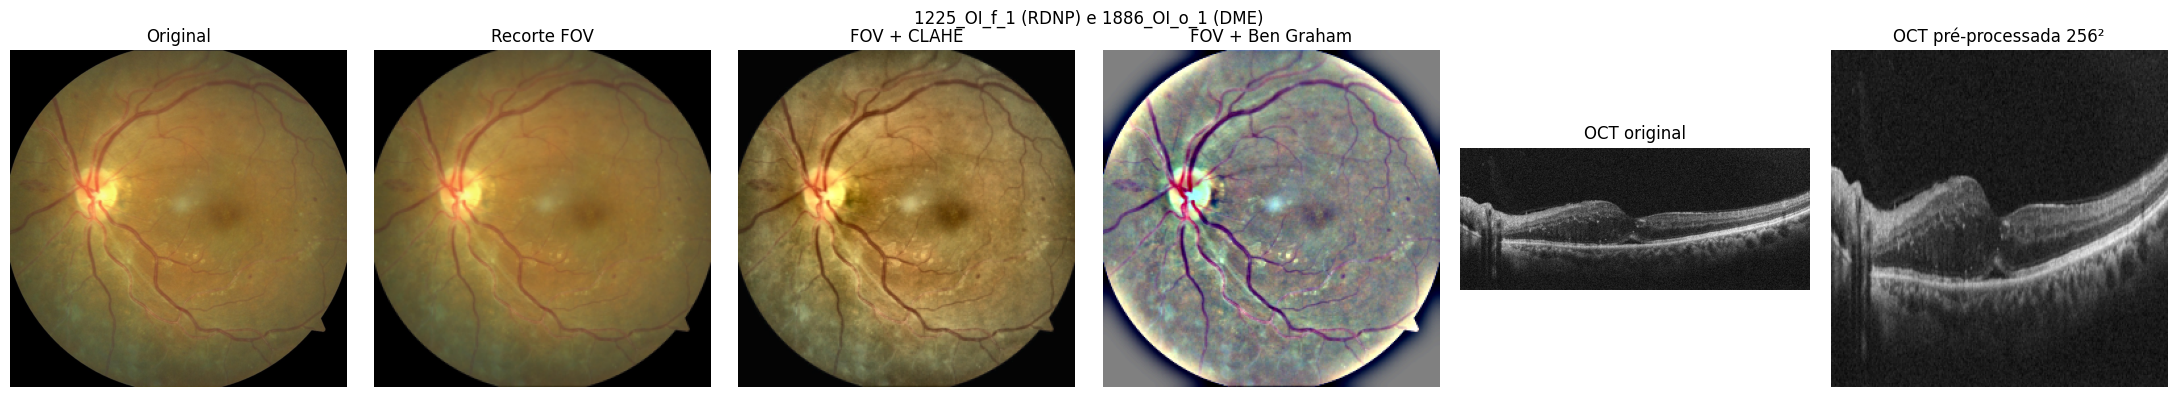

In [ ]:
def recortar_fov(rgb, limiar=15):
    g = rgb.max(axis=2)
    ys, xs = np.where(g > limiar)
    if len(ys) == 0:
        return rgb
    rgb = rgb[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = rgb.shape[:2]; s = max(h, w)
    quadrado = np.zeros((s, s, 3), dtype=rgb.dtype)
    quadrado[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = rgb
    return quadrado

def clahe_rgb(rgb, clip=2.0, grade=8):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=clip, tileGridSize=(grade, grade)).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)

def ben_graham(rgb, sigma):
    return cv2.addWeighted(rgb, 4, cv2.GaussianBlur(rgb, (0, 0), sigma), -4, 128)

def preprocessar_fundo(caminho, modo=PREPROC_FUNDO, tam=CACHE):
    rgb = np.array(Image.open(caminho).convert('RGB'))
    rgb = recortar_fov(rgb)
    rgb = cv2.resize(rgb, (tam, tam), interpolation=cv2.INTER_AREA)
    if modo == 'clahe':
        rgb = clahe_rgb(rgb)
    elif modo == 'ben':
        rgb = ben_graham(rgb, sigma=tam / 30)
    return Image.fromarray(rgb)

def preprocessar_oct(caminho, tam=CACHE):
    g = np.array(Image.open(caminho).convert('L'))
    g = cv2.medianBlur(g, 3)
    g = cv2.resize(g, (tam, tam), interpolation=cv2.INTER_AREA)
    return Image.fromarray(np.stack([g, g, g], axis=-1))

CACHE_IMG = {}
def obter_imagem(caminho, modalidade):
    if caminho not in CACHE_IMG:
        CACHE_IMG[caminho] = preprocessar_fundo(caminho) if modalidade == 'fundo' else preprocessar_oct(caminho)
    return CACHE_IMG[caminho]

# Ilustração das etapas
ex = fundo[(fundo.coorte.str.startswith('B')) & (fundo.DR == 'NPDR')].iloc[0]
orig = np.array(Image.open(ex['caminho']).convert('RGB'))
fov = cv2.resize(recortar_fov(orig), (CACHE, CACHE), interpolation=cv2.INTER_AREA)
etapas = [('Original', orig), ('Recorte FOV', fov), ('FOV + CLAHE', clahe_rgb(fov)),
          ('FOV + Ben Graham', ben_graham(fov, CACHE / 30))]
ex_o = octs[octs.DME == 1].iloc[0]
fig, axes = plt.subplots(1, 6, figsize=(22, 4))
for ax, (t, im) in zip(axes[:4], etapas):
    ax.imshow(im); ax.set_title(t); ax.axis('off')
axes[4].imshow(Image.open(ex_o['caminho']).convert('RGB')); axes[4].set_title('OCT original'); axes[4].axis('off')
axes[5].imshow(preprocessar_oct(ex_o['caminho'])); axes[5].set_title('OCT pré-processada 256²'); axes[5].axis('off')
plt.suptitle(f"{ex['Name']} (RDNP) e {ex_o['Name']} (DME)")
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, 'figuras', 'preprocessamento.png'), dpi=150); plt.show()

### Resultado do pré-processamento

A figura ilustra as etapas aplicadas a uma retinografia com retinopatia não proliferativa (1225_OI_f_1) e a uma OCT com edema macular (1886_OI_o_1).

- **Recorte do campo de visão:** nesta imagem a alteração é discreta, pois a borda preta já era reduzida. O recorte é aplicado a todas as imagens para padronizar a posição e o tamanho da retina.
- **CLAHE:** aumenta a nitidez e o contraste local. Os vasos ficam mais definidos e pequenas lesões claras, compatíveis com exsudatos, tornam-se mais visíveis do que na imagem original.
- **Ben Graham:** realça intensamente vasos e lesões, mas altera de forma acentuada as cores e produz um halo na borda da retina. Por esse motivo foi mantido apenas como alternativa, sendo o **CLAHE adotado como pré-processamento padrão**.
- **OCT:** observa-se uma **elevação da retina na região central**, compatível com o espessamento causado pelo edema. Após o filtro de mediana e o redimensionamento, a estrutura em camadas e a elevação permanecem preservadas e mais visíveis.

A figura é salva em `DME_v2/figuras/preprocessamento.png`.

## 4. Desenho experimental

### Imagens utilizadas

Com base na auditoria da Seção 2, os experimentos utilizam apenas imagens cujas classes têm a mesma origem:

- **Retinografias:** somente as da **coorte B** (545 imagens de 225 pacientes, 54 com edema);
- **OCT:** todas as 1.113 imagens, que pertencem ao mesmo grupo de pacientes da coorte B.

A coorte A é excluída por não possuir imagens sem edema de mesma origem, o que impediria uma comparação justa.

### Validação cruzada por paciente

Em vez de uma única divisão entre treino e teste, como na primeira versão, os pacientes são divididos em **5 grupos (folds)**. Em cada rodada, a rede é treinada com 4 grupos e testada no grupo restante, e o processo é repetido 5 vezes, até que **todos os pacientes tenham sido usados como teste exatamente uma vez**.

Essa escolha é necessária porque a coorte B contém apenas **54 retinografias com edema**: uma divisão única deixaria cerca de 8 casos positivos no teste, produzindo resultados muito instáveis.

A divisão é feita **por paciente** (todas as imagens de um mesmo paciente ficam no mesmo grupo, evitando vazamento de dados) e é **estratificada** (cada grupo recebe proporções semelhantes de casos com edema e de cada grau de retinopatia).

### Validação e teste

Dentro de cada rodada, **15% dos pacientes de treino** são separados como conjunto de **validação**, utilizado para interromper o treinamento no momento adequado (*early stopping*) e para escolher a taxa de aprendizado. O grupo de **teste não é utilizado em nenhuma decisão**: serve apenas para a avaliação final.

### Olhos pareados

São identificados os olhos que possuem **retinografia e OCT**. Para cada olho, são formadas todas as combinações entre suas retinografias e suas OCTs. Também é verificado se o diagnóstico de edema é o mesmo nas duas modalidades.

Para comparar retinografia, OCT e a combinação das duas de forma justa, todos os modelos são avaliados **nos mesmos olhos pareados de teste**. Quando um olho possui mais de uma imagem, a probabilidade de edema desse olho é a média das probabilidades de suas imagens.

### Métricas

As métricas são as mesmas da primeira versão: acurácia, acurácia balanceada, sensibilidade, especificidade, precisão, F1-score, AUC, AUPRC, Kappa de Cohen e MCC. Para a classificação do grau de retinopatia (três classes) são utilizadas a acurácia balanceada, o F1-score macro, o **Kappa quadrático ponderado** e a AUC macro. Os intervalos de confiança de 95% são estimados por *bootstrap*, reamostrando pacientes.

In [ ]:
fundo_B = fundo[fundo['DR_graduado']].copy()
oct_B = octs.copy()

pac = (pd.concat([fundo_B[['Paciente', 'DME', 'DR_cls']], oct_B[['Paciente', 'DME', 'DR_cls']]])
       .groupby('Paciente').agg(DME=('DME', 'max'), DR=('DR_cls', 'max')).reset_index())
pac['estrato'] = pac['DME'].astype(str) + '_' + pac['DR'].fillna(-1).astype(int).astype(str)
pac['fold'] = -1
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for k, (_, idx) in enumerate(skf.split(pac, pac['estrato'])):
    pac.loc[pac.index[idx], 'fold'] = k
mapa_fold = dict(zip(pac['Paciente'], pac['fold']))
fundo_B['fold'] = fundo_B['Paciente'].map(mapa_fold)
oct_B['fold'] = oct_B['Paciente'].map(mapa_fold)

# Pacientes de validação (fixos por fold, para todos os modelos)
# Estratificados por DME e grau de RD, para que a validação contenha casos dos três graus
VAL = {}
for k in range(N_FOLDS):
    p_treino = pac[pac.fold != k]
    _, p_val = train_test_split(p_treino, test_size=0.15, random_state=SEED + k,
                                stratify=p_treino['estrato'])   # CORRIGIDO
    VAL[k] = set(p_val['Paciente'])

# Pares retinografia x OCT do mesmo olho
olhos_par = sorted(set(fundo_B.olho_id) & set(oct_B.olho_id))
pares = (fundo_B[fundo_B.olho_id.isin(olhos_par)][['olho_id', 'Paciente', 'Name', 'caminho', 'DME', 'DR_cls', 'fold']]
         .merge(oct_B[oct_B.olho_id.isin(olhos_par)][['olho_id', 'Name', 'caminho', 'DME', 'DR_cls']],
                on='olho_id', suffixes=('_f', '_o')))
assert (pares['DME_f'] == pares['DME_o']).all(), 'Rótulo de DME diferente entre modalidades do mesmo olho'
pares['DME'] = pares['DME_f']
pares['DR_cls'] = pares['DR_cls_f'].fillna(pares['DR_cls_o'])

olhos = pares.groupby('olho_id').agg(Paciente=('Paciente', 'first'), DME=('DME', 'first'),
                                     DR_cls=('DR_cls', 'first'), fold=('fold', 'first')).reset_index()
print(f'Retinografias coorte B: {len(fundo_B)} ({fundo_B.DME.sum()} com DME) | OCT: {len(oct_B)} ({oct_B.DME.sum()} com DME)')
print(f'Olhos pareados: {len(olhos)} ({olhos.DME.sum()} com DME) | combinações de pares: {len(pares)}')
display(pd.crosstab(olhos['fold'], olhos['DME'], margins=True).rename_axis('fold \\ DME (olhos pareados)'))
display(pd.crosstab(fundo_B['fold'], fundo_B['DR'], margins=True).rename_axis('fold \\ RD (retinografias)'))

# Verificação de vazamento
for k in range(N_FOLDS):
    assert not (set(fundo_B[fundo_B.fold == k].Paciente) & set(fundo_B[fundo_B.fold != k].Paciente))
    assert not (set(oct_B[oct_B.fold == k].Paciente) & VAL[k])
print('Nenhum paciente compartilhado entre treino, validação e teste em nenhum fold.')

Retinografias coorte B: 545 (54 com DME) | OCT: 1113 (167 com DME)
Olhos pareados: 410 (51 com DME) | combinações de pares: 566


DME,0,1,All
fold \ DME (olhos pareados),,,
0,69,12,81
1,68,8,76
2,72,14,86
3,77,11,88
4,73,6,79
All,359,51,410


DR,0,NPDR,PDR,All
fold \ RD (retinografias),,,,
0,80,20,11,111
1,74,17,8,99
2,80,28,10,118
3,78,18,9,105
4,86,12,14,112
All,398,95,52,545


Nenhum paciente compartilhado entre treino, validação e teste em nenhum fold.


### Resultado da divisão dos dados

| | Imagens | Com edema |
|---|---|---|
| Retinografias (coorte B) | 545 | 54 |
| OCT | 1.113 | 167 |
| Olhos pareados (retinografia + OCT) | 410 | 51 |

Os 410 olhos pareados geram **566 combinações** de retinografia e OCT, pois alguns olhos possuem mais de uma imagem de cada modalidade. O número de olhos pareados é ligeiramente menor que o da Seção 1 (414) porque 4 olhos possuíam retinografias sem grau de retinopatia informado e, por isso, não fazem parte da coorte B.

**Distribuição entre os grupos (folds):** cada grupo recebeu entre 76 e 88 olhos pareados e entre 99 e 118 retinografias, com representação dos três graus de retinopatia em todos eles. O número de olhos com edema variou de 6 a 14 por grupo. Essa variação ocorre porque a divisão é feita **por paciente** (e não por olho), já que alguns pacientes apresentam edema nos dois olhos. Os resultados de grupos com poucos casos positivos devem ser interpretados com cautela, o que reforça o uso das métricas calculadas sobre o conjunto completo dos 5 grupos.

**Verificação de vazamento:** nenhum paciente está presente simultaneamente nos conjuntos de treino, validação e teste em nenhuma das 5 rodadas.

### 4.1 Linha de base: classificador baseado apenas em cor na coorte B

O classificador da Seção 2.3, que utiliza apenas informações globais de cor, é aplicado agora **somente à coorte B**, com a mesma validação cruzada em 5 grupos que será usada pelas redes neurais.

O resultado define uma **linha de base** (o "piso" de desempenho): para demonstrar que reconhecem o edema a partir de características morfológicas (forma, localização e aspecto das lesões), as redes neurais precisam superar esse valor com margem.

Parte do sinal de cor nessa coorte é clinicamente legítimo, pois exsudatos (amarelados) e hemorragias (avermelhadas) alteram a distribuição de cores da imagem. Outra parte pode refletir diferenças residuais de aquisição, como os artefatos observados na Seção 2.2.

In [ ]:
Xb = X_cor[fundo['DR_graduado'].values]
oof = np.zeros(len(fundo_B))
for k in range(N_FOLDS):
    tr_ = (fundo_B.fold != k).values; te_ = ~tr_
    clf = RandomForestClassifier(500, class_weight='balanced', random_state=0, n_jobs=-1).fit(Xb[tr_], fundo_B.DME.values[tr_])
    oof[te_] = clf.predict_proba(Xb[te_])[:, 1]
AUC_COR_B = roc_auc_score(fundo_B.DME, oof)
print(f'Só cor, coorte B, validação cruzada por paciente: AUC = {AUC_COR_B:.3f}')

Só cor, coorte B, validação cruzada por paciente: AUC = 0.785


### Resultado da linha de base

O classificador baseado apenas em cor atingiu **AUC de 0,785** na coorte B, contra 0,985 na base completa (Seção 2.3).

Essa queda mostra que, ao restringir o estudo à coorte B, **a cor deixa de ser suficiente para identificar o edema**: o atalho causado pela diferença de origem das imagens foi em grande parte eliminado.

O valor ainda acima do acaso (0,5) é esperado, pois lesões como exsudatos e hemorragias alteram a distribuição de cores da retina. Parte desse sinal também pode refletir diferenças residuais de aquisição.

**Esse valor (AUC = 0,785) é a linha de base deste estudo:** as redes neurais devem superá-lo com margem para demonstrar que reconhecem o edema a partir de características morfológicas da imagem.

### 4.2 Distribuição das classes e desbalanceamento

**Os valores da coluna de retinopatia.** A coluna `DR` da base possui quatro valores: `0` (sem retinopatia), `NPDR` (retinopatia diabética não proliferativa), `PDR` (retinopatia diabética proliferativa) e `-`. Segundo a descrição da base, o valor `-` indica que o grau **não foi informado**, e não um quarto grau da doença. Por isso, a graduação utiliza **três classes**, e as imagens com valor `-` não participam dessa tarefa. A base também não subdivide a RDNP em leve, moderada e grave, como na escala internacional de cinco níveis (ICDR).

**Desbalanceamento.** As classes não têm o mesmo número de imagens: há muito mais imagens sem edema do que com edema, e muito mais imagens sem retinopatia do que com retinopatia proliferativa. Sem tratamento, a rede tenderia a favorecer a classe mais frequente.

**Procedimentos adotados para tratar o desbalanceamento:**

1. **Pesos na função de perda:** cada classe recebe um peso inversamente proporcional à sua frequência, de modo que os erros nas classes raras pesem mais durante o treinamento. A tabela mostra o peso aproximado de cada classe; durante o treinamento, os pesos são recalculados em cada rodada, a partir das imagens de treino.
2. **Divisão estratificada:** cada rodada da validação cruzada recebe proporções semelhantes de cada classe (Seção 4).
3. **Métricas robustas ao desbalanceamento:** além da acurácia, são utilizadas a acurácia balanceada, o Kappa, o MCC e a AUC (Seção 7.1).

Valores da coluna DR na base completa (todas as imagens):


,Retinografias,OCTs
0 (sem retinopatia),398,341
NPDR (não proliferativa),95,119
PDR (proliferativa),52,53
- (não informado),1003,600



Distribuição das classes nas imagens utilizadas nos experimentos (coorte B):


,Tarefa,Classe,Imagens,% do total,Proporção (maior : esta),Peso na perda
0,Edema – retinografia,Sem DME,491,90.09,1.0 : 1,0.55
1,Edema – retinografia,Com DME,54,9.91,9.1 : 1,5.05
2,Edema – OCT,Sem DME,946,85.00,1.0 : 1,0.59
3,Edema – OCT,Com DME,167,15.00,5.7 : 1,3.33
4,Grau – retinografia,Sem RD,398,73.03,1.0 : 1,0.46
5,Grau – retinografia,RDNP,95,17.43,4.2 : 1,1.91
6,Grau – retinografia,RDP,52,9.54,7.7 : 1,3.49
7,Grau – OCT,Sem RD,341,66.47,1.0 : 1,0.50
8,Grau – OCT,RDNP,119,23.20,2.9 : 1,1.44
9,Grau – OCT,RDP,53,10.33,6.4 : 1,3.23


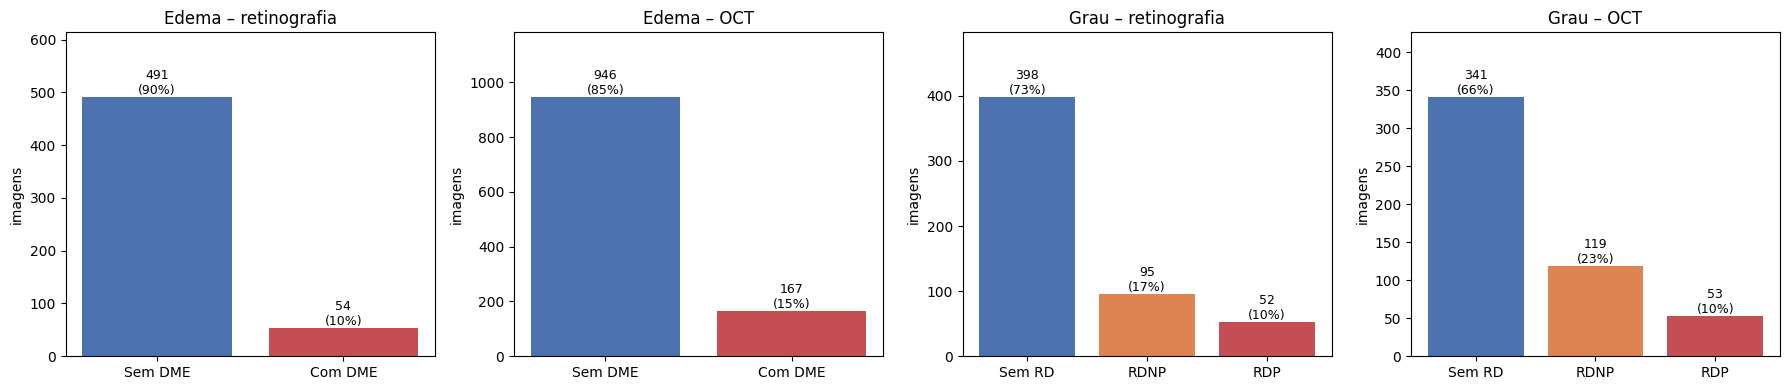

In [ ]:
# ===== 4.2 Distribuição das classes e desbalanceamento =====

# (a) Os 4 valores da coluna DR na base completa
print('Valores da coluna DR na base completa (todas as imagens):')
tab_dr_bruto = pd.DataFrame({
    'Retinografias': fundo['DR'].value_counts(),
    'OCTs': octs['DR'].value_counts()}).reindex(['0', 'NPDR', 'PDR', '-']).fillna(0).astype(int)
tab_dr_bruto.index = ['0 (sem retinopatia)', 'NPDR (não proliferativa)', 'PDR (proliferativa)', '- (não informado)']
display(tab_dr_bruto)

# (b) Distribuição das classes nas imagens usadas nos experimentos (coorte B)
TAREFAS = [
    ('Edema – retinografia', fundo_B, 'DME', {0: 'Sem DME', 1: 'Com DME'}),
    ('Edema – OCT', oct_B, 'DME', {0: 'Sem DME', 1: 'Com DME'}),
    ('Grau – retinografia', fundo_B[fundo_B['DR_cls'].notna()], 'DR_cls', {0: 'Sem RD', 1: 'RDNP', 2: 'RDP'}),
    ('Grau – OCT', oct_B[oct_B['DR_cls'].notna()], 'DR_cls', {0: 'Sem RD', 1: 'RDNP', 2: 'RDP'}),
]
linhas = []
for tarefa, d, col, mapa in TAREFAS:
    y = d[col].astype(int)
    n, k = len(y), len(mapa)
    maior = y.value_counts().max()
    for cls, rot in mapa.items():
        c = int((y == cls).sum())
        linhas.append({'Tarefa': tarefa, 'Classe': rot, 'Imagens': c, '% do total': 100 * c / n,
                       'Proporção (maior : esta)': f'{maior / c:.1f} : 1',
                       'Peso na perda': n / (k * c)})
tab_classes = pd.DataFrame(linhas)
tab_classes.to_csv(os.path.join(SAIDA, 'distribuicao_classes.csv'), index=False)
print('\nDistribuição das classes nas imagens utilizadas nos experimentos (coorte B):')
display(tab_classes.round(2))

# (c) Gráfico
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
cores = {'Sem DME': '#4C72B0', 'Com DME': '#C44E52', 'Sem RD': '#4C72B0', 'RDNP': '#DD8452', 'RDP': '#C44E52'}
for ax, (tarefa, _, _, _) in zip(axes, TAREFAS):
    t = tab_classes[tab_classes['Tarefa'] == tarefa]
    barras = ax.bar(t['Classe'], t['Imagens'], color=[cores[c] for c in t['Classe']])
    ax.bar_label(barras, labels=[f'{v}\n({p:.0f}%)' for v, p in zip(t['Imagens'], t['% do total'])], fontsize=9)
    ax.set_title(tarefa); ax.set_ylabel('imagens'); ax.margins(y=0.25)
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, 'figuras', 'distribuicao_classes.png'), dpi=150); plt.show()

### Resultado: classes e desbalanceamento da base

**A coluna de retinopatia tem quatro valores, mas três graus.** O valor `-` (grau não informado) está presente em 1.003 retinografias e 600 OCTs. Essas imagens não têm o grau da retinopatia e, por isso, não participam da tarefa de graduação. Restam três classes: sem retinopatia, RDNP e RDP.

**As duas tarefas são desbalanceadas:**

| Tarefa | Classe mais frequente | Classe mais rara | Proporção |
|---|---|---|---|
| Edema – retinografia | Sem DME (90%) | Com DME (10%) | 9,1 : 1 |
| Edema – OCT | Sem DME (85%) | Com DME (15%) | 5,7 : 1 |
| Grau – retinografia | Sem RD (73%) | RDP (10%) | 7,7 : 1 |
| Grau – OCT | Sem RD (66%) | RDP (10%) | 6,4 : 1 |

- O desbalanceamento é maior na **retinografia**, em que há cerca de 9 imagens sem edema para cada imagem com edema.
- Na graduação, a **RDP** é a classe mais rara nas duas modalidades (cerca de 10% das imagens). Isso ajuda a explicar a menor sensibilidade das redes para essa classe (Seção 7.6).
- Com os pesos na função de perda, cada erro em uma imagem com edema na retinografia pesa cerca de **9 vezes mais** que um erro em uma imagem sem edema (5,05 contra 0,55), e cada erro em uma imagem de RDP pesa cerca de **7,6 vezes mais** que um erro em uma imagem sem retinopatia (3,49 contra 0,46).

## 5. Treinamento das redes neurais

Esta seção descreve como as redes neurais são treinadas. A mesma estrutura é utilizada para as três arquiteturas, as duas modalidades de imagem e as duas tarefas, garantindo que as comparações sejam feitas sob as mesmas condições.

### 5.1 Como funcionam as redes pré-treinadas (*transfer learning*)

**O problema.** Treinar uma rede neural profunda "do zero" exige centenas de milhares ou milhões de imagens rotuladas. A coorte B deste trabalho tem 545 retinografias e 1.113 OCTs, quantidade insuficiente para que a rede aprenda, sozinha, a reconhecer formas, bordas e texturas.

**A solução: reaproveitar o que a rede já aprendeu.** As três arquiteturas utilizadas foram previamente treinadas no **ImageNet**, uma base com cerca de 1,2 milhão de fotografias de 1.000 categorias de objetos (animais, veículos, objetos do cotidiano). Durante esse treinamento, a rede aprende uma hierarquia de características visuais:

- **Primeiras camadas:** características simples e gerais, como bordas, cantos, cores e texturas, úteis para qualquer tipo de imagem, inclusive imagens médicas.
- **Camadas intermediárias:** combinações dessas características, como contornos, padrões repetitivos e formas.
- **Últimas camadas:** padrões mais complexos e específicos das categorias do ImageNet.
- **Camada final (classificador):** converte essas características na decisão entre as 1.000 categorias.

**O processo, em três etapas:**

1. **Carregar a rede com os pesos do ImageNet.** A arquitetura e todos os pesos aprendidos são carregados da biblioteca Torchvision.
2. **Substituir a camada final.** O classificador original, com 1.000 saídas, é removido e substituído por uma nova camada, com **2 saídas** (com e sem edema) ou **3 saídas** (sem retinopatia, RDNP e RDP). Essa camada começa com pesos aleatórios.
3. **Ajuste fino (*fine-tuning*).** A rede inteira é treinada com as imagens da retina. Todos os pesos, os reaproveitados e os da nova camada, são ajustados, mas com uma **taxa de aprendizado pequena**, para que a rede adapte o conhecimento prévio às imagens médicas sem "apagar" o que já aprendeu.

**Alternativas existentes.** Há outras formas de usar redes pré-treinadas:

| Estratégia | O que é treinado | Quando é indicada |
|---|---|---|
| Extração de características | Apenas a nova camada final; o restante fica "congelado" | Bases muito pequenas ou muito parecidas com o ImageNet |
| Ajuste fino parcial | A camada final e as últimas camadas | Situação intermediária (utilizada por Rady et al., 2026) |
| **Ajuste fino completo** (este trabalho) | **Todas as camadas** | Bases de tamanho moderado e diferentes do ImageNet, como as imagens de retina |

Optou-se pelo **ajuste fino completo** porque as imagens de retina, principalmente as OCTs, são muito diferentes das fotografias do ImageNet, e a adaptação de todas as camadas tende a produzir melhores resultados nesse cenário.

**Consequências para a escolha dos hiperparâmetros.** Ao utilizar uma rede pré-treinada, alguns elementos **ficam fixos**, pois alterá-los invalidaria o conhecimento reaproveitado:

- a **arquitetura**: número de camadas, tamanho dos *kernels* das convoluções (3 × 3 e 1 × 1 na ResNet50 e na DenseNet121) e o tamanho dos blocos da imagem no ViT-B/16 (16 × 16 pixels);
- o **tamanho da imagem de entrada** (224 × 224 pixels);
- a **normalização das cores**, que utiliza as médias e desvios-padrão do ImageNet.

Os elementos que **podem e devem ser ajustados** são os do processo de treinamento, como a **taxa de aprendizado** e o **tamanho do lote** (*batch size*). Esses são os hiperparâmetros avaliados pelo *grid search* (Seção 5.3).

A célula a seguir mostra, para cada rede, quantos parâmetros são reaproveitados do ImageNet e quantos pertencem à nova camada final.

In [ ]:
# Estrutura das redes pré-treinadas: parâmetros reaproveitados × camada final nova
linhas = []
for arq in ARQS:
    m = criar_modelo(arq, 2)   # carrega os pesos do ImageNet e troca a camada final (2 saídas)
    total = sum(p.numel() for p in m.parameters())
    cabeca = m.fc if arq == 'resnet50' else (m.classifier if arq == 'densenet121' else m.heads.head)
    n_cabeca = sum(p.numel() for p in cabeca.parameters())
    linhas.append({'Rede': NOME[arq],
                   'Parâmetros totais': f'{total / 1e6:.1f} milhões',
                   'Reaproveitados do ImageNet': f'{(total - n_cabeca) / 1e6:.1f} milhões',
                   'Camada final nova': f'{cabeca.in_features} → 2 saídas',
                   'Parâmetros da camada nova': f'{n_cabeca:,}'.replace(',', '.')})
    del m
display(pd.DataFrame(linhas))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 147MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 169MB/s]


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:05<00:00, 65.6MB/s]


,Rede,Parâmetros totais,Reaproveitados do ImageNet,Camada final nova,Parâmetros da camada nova
0,ResNet50,23.5 milhões,23.5 milhões,2048 → 2 saídas,4.098
1,DenseNet121,7.0 milhões,7.0 milhões,1024 → 2 saídas,2.050
2,ViT-B/16,85.8 milhões,85.8 milhões,768 → 2 saídas,1.538


### Resultado: estrutura das redes pré-treinadas

| Rede | Parâmetros totais | Parâmetros da camada nova | Reaproveitados do ImageNet |
|---|---|---|---|
| ResNet50 | 23,5 milhões | 4.098 | 99,98% |
| DenseNet121 | 7,0 milhões | 2.050 | 99,97% |
| ViT-B/16 | 85,8 milhões | 1.538 | 99,998% |

Nas três arquiteturas, **praticamente todos os parâmetros são reaproveitados do ImageNet**, e apenas a camada final, com poucos milhares de parâmetros, é criada do zero. Isso mostra por que o *transfer learning* é essencial neste trabalho: sem o pré-treinamento, seria necessário aprender dezenas de milhões de parâmetros a partir de apenas algumas centenas de imagens.

As arquiteturas diferem bastante em tamanho: a DenseNet121 é a menor, a ResNet50 é intermediária e o ViT-B/16 é a maior, com cerca de 12 vezes mais parâmetros que a DenseNet121. Redes maiores têm mais capacidade de aprendizado, mas também maior risco de memorizar as imagens de treino quando a base é pequena, o que reforça a importância da escolha cuidadosa dos hiperparâmetros.

### 5.2 Hiperparâmetros do treinamento

Hiperparâmetros são as configurações do treinamento que não são aprendidas pela rede, mas definidas antes dele. Como explicado na Seção 5.1, a arquitetura das redes pré-treinadas é mantida; os hiperparâmetros ajustados são os do processo de treinamento.

| Hiperparâmetro | Valor | Como foi definido |
|---|---|---|
| Taxa de aprendizado | 0,00001 a 0,001 | *Grid search* (Seção 5.3) |
| Tamanho do lote | 16 ou 32 | *Grid search* (Seção 5.3) |
| Otimizador | AdamW | Recomendação da literatura |
| Decaimento dos pesos | 0,0001 (CNNs) e 0,05 (ViT) | Recomendação da literatura |
| Número de épocas | Até 25 | Interrupção antecipada |
| Desbalanceamento | Pesos na função de perda | Seção 4.2 |

**Justificativas:**

- **Taxa de aprendizado e tamanho do lote:** definidos por *grid search* (Seção 5.3), **separadamente para cada modalidade (retinografia e OCT), cada tarefa (edema e grau da retinopatia) e cada arquitetura**. Isso permite que cada combinação utilize os valores mais adequados a ela.
  - Lotes maiores que 32 não foram avaliados, pois o ViT-B/16 excede a memória da GPU utilizada (NVIDIA T4).

- **Otimizador:** AdamW. A taxa de aprendizado aumenta gradualmente nos primeiros 10% do treinamento (aquecimento) e depois diminui de forma suave (decaimento cosseno). É a configuração recomendada para o ajuste fino do Vision Transformer (Dosovitskiy et al., 2021) e também é adequada às redes convolucionais.

- **Decaimento dos pesos (*weight decay*):** penaliza pesos muito grandes, reduzindo o risco de sobreajuste. Foram utilizados os valores usuais da literatura para cada tipo de arquitetura.

- **Número de épocas:** no máximo 25. O treinamento é interrompido se a perda de validação não melhorar por 6 épocas seguidas (*early stopping*), e é mantida a versão da rede com a **menor perda de validação**.

- **Desbalanceamento das classes:** os erros nas classes raras recebem peso maior na função de perda (Seção 4.2). Os pesos são recalculados em cada rodada.

- **Fusão e destilação:** utilizam os hiperparâmetros escolhidos para as redes de retinografia e de OCT na tarefa do edema. Na fusão intermediária, em que as duas redes são treinadas juntas, a taxa de aprendizado é 30% da menor taxa escolhida entre as duas, e o lote é de 16 imagens, por limite de memória.

### Aumento de dados (*data augmentation*)

Durante o treinamento, cada imagem recebe pequenas modificações aleatórias a cada época, para que a rede aprenda características relevantes em vez de memorizar as imagens:

- **Retinografia:** espelhamento horizontal, rotação de até 15°, pequeno recorte e zoom, e variações leves de brilho, contraste e cor.
- **OCT:** espelhamento horizontal, pequenos deslocamentos e rotações (até 3°), e variações leves de brilho e contraste.

Nas imagens de validação e teste não é aplicada nenhuma modificação.

### Funções de treinamento

A célula a seguir apenas **define** os procedimentos de preparação das imagens, treinamento e avaliação. Nenhum treinamento é executado nesta etapa.

In [ ]:
def transformacao(modalidade, treino):
    if not treino:
        return transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), transforms.Normalize(MEDIA, DP)])
    if modalidade == 'fundo':
        aug = [transforms.RandomResizedCrop(IMG, scale=(0.85, 1.0), ratio=(0.95, 1.05)),
               transforms.RandomHorizontalFlip(), transforms.RandomRotation(15),
               transforms.ColorJitter(0.2, 0.2, 0.1, 0.02)]
    else:
        aug = [transforms.Resize((IMG, IMG)), transforms.RandomHorizontalFlip(),
               transforms.RandomAffine(degrees=3, translate=(0.05, 0.05), scale=(0.95, 1.05)),
               transforms.ColorJitter(0.2, 0.2)]
    return transforms.Compose(aug + [transforms.ToTensor(), transforms.Normalize(MEDIA, DP)])

class DSImagem(Dataset):
    """Uma imagem por item. `soft` (opcional): dicionário olho_id -> distribuição do professor (destilação)."""
    def __init__(self, df, modalidade, transform, soft=None, n_classes=2):
        self.df = df.reset_index(drop=True); self.mod = modalidade; self.t = transform
        self.soft = soft; self.n = n_classes
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        x = self.t(obter_imagem(r['caminho'], self.mod)); y = int(r['y'])
        if self.soft is None:
            return x, y
        alvo = self.soft.get(r['olho_id'])
        if alvo is None:                      # olho sem OCT: usa o rótulo verdadeiro
            alvo = np.eye(self.n, dtype=np.float32)[y]
        return x, y, torch.as_tensor(alvo, dtype=torch.float32)

class DSPar(Dataset):
    """Par (retinografia, OCT) do mesmo olho."""
    def __init__(self, df, tf_f, tf_o):
        self.df = df.reset_index(drop=True); self.tf_f = tf_f; self.tf_o = tf_o
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        xf = self.tf_f(obter_imagem(r['caminho_f'], 'fundo'))
        xo = self.tf_o(obter_imagem(r['caminho_o'], 'oct'))
        return (xf, xo), int(r['y'])

def carregador(ds, treino, batch=BATCH):
    return DataLoader(ds, batch_size=batch, shuffle=treino, drop_last=treino and len(ds) > batch,
                      num_workers=NW, pin_memory=USAR_AMP, persistent_workers=False)

def mover(x):
    if isinstance(x, (list, tuple)):
        return [t.to(device, non_blocking=True) for t in x]
    return x.to(device, non_blocking=True)

def pesos_classes(y, n):
    cont = np.bincount(np.asarray(y, dtype=int), minlength=n).astype(float)
    cont[cont == 0] = 1
    return torch.tensor(len(y) / (n * cont), dtype=torch.float32, device=device)

@torch.no_grad()
def prever(modelo, dl, crit=None, temperatura=1.0):
    modelo.eval(); P, Y = [], []; perda, n = 0.0, 0
    for lote in dl:
        x, y = mover(lote[0]), lote[1].to(device)
        with autocast():
            logits = modelo(x)
        logits = logits.float()
        if crit is not None:
            perda += crit(logits, y).item() * y.size(0)
        P.append(F.softmax(logits / temperatura, 1).cpu().numpy()); Y.append(y.cpu().numpy()); n += y.size(0)
    return np.concatenate(P), np.concatenate(Y), (perda / n if crit is not None else None)

def auc_seguro(y, P):
    try:
        if P.shape[1] == 2:
            return roc_auc_score(y, P[:, 1])
        return roc_auc_score(y, P, multi_class='ovr', average='macro', labels=list(range(P.shape[1])))
    except ValueError:
        return np.nan

def treinar(modelo, dl_tr, dl_va, y_tr, n_classes, lr, wd, epocas=EPOCAS_MAX, paciencia=PACIENCIA,
            kd_alpha=0.0, kd_T=1.0, rotulo=''):
    modelo = modelo.to(device)
    crit = nn.CrossEntropyLoss(weight=pesos_classes(y_tr, n_classes))
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=wd)
    passos = max(1, epocas * len(dl_tr)); aquec = max(1, int(0.1 * passos))
    def fator(s):
        if s < aquec:
            return (s + 1) / aquec
        return 0.5 * (1 + math.cos(math.pi * min(1.0, (s - aquec) / max(1, passos - aquec))))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, fator)
    scaler = novo_scaler()
    melhor_perda, melhor_estado, sem_melhora, hist = float('inf'), None, 0, []
    for ep in range(epocas):
        modelo.train(); soma, n, t0 = 0.0, 0, time.time()
        for lote in dl_tr:
            x, y = mover(lote[0]), lote[1].to(device)
            opt.zero_grad(set_to_none=True)
            with autocast():
                logits = modelo(x)
                perda = crit(logits.float(), y)
                if kd_alpha > 0:
                    alvo = lote[2].to(device)
                    kd = F.kl_div(F.log_softmax(logits.float() / kd_T, 1), alvo, reduction='batchmean') * kd_T ** 2
                    perda = (1 - kd_alpha) * perda + kd_alpha * kd
            scaler.scale(perda).backward(); scaler.step(opt); scaler.update(); sched.step()
            soma += perda.item() * y.size(0); n += y.size(0)
        Pv, Yv, perda_v = prever(modelo, dl_va, crit)
        hist.append({'época': ep + 1, 'perda_treino': soma / max(n, 1), 'perda_val': perda_v,
                     'auc_val': auc_seguro(Yv, Pv), 'seg': time.time() - t0})
        if perda_v < melhor_perda - 1e-4:
            melhor_perda, sem_melhora = perda_v, 0
            melhor_estado = {k_: v.detach().cpu().clone() for k_, v in modelo.state_dict().items()}
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break
    modelo.load_state_dict(melhor_estado)
    h = pd.DataFrame(hist)
    print(f'  {rotulo}: {len(h)} épocas, melhor perda val {melhor_perda:.4f} '
          f'(época {int(h.perda_val.idxmin()) + 1}), AUC val {h.auc_val[h.perda_val.idxmin()]:.3f}')
    return modelo, h

def separar(df, k):
    tr = df[(df.fold != k) & (~df.Paciente.isin(VAL[k]))]
    va = df[(df.fold != k) & (df.Paciente.isin(VAL[k]))]
    te = df[df.fold == k]
    return tr, va, te

def tabela_pred(df, P, **info):
    out = df[['Name', 'olho_id', 'Paciente']].reset_index(drop=True).copy() if 'Name' in df else \
          df[['olho_id', 'Paciente']].reset_index(drop=True).copy()
    out['y'] = df['y'].values
    for c in range(P.shape[1]):
        out[f'p{c}'] = P[:, c]
    for k_, v in info.items():
        out[k_] = v
    return out

def hp_de(modalidade, tarefa, arq):
    """Hiperparâmetros escolhidos pelo grid search (Seção 5.3); se ausentes, usa os valores padrão."""
    return HP.get((modalidade, tarefa, arq), {'lr': LR[arq], 'batch': BATCH})

def treinar_modalidade(df_mod, modalidade, tarefa, arq, k, lr=None, batch=None, epocas=EPOCAS_MAX, soft=None,
                       kd_alpha=0.0, rotulo=None):
    """Treina um modelo de uma modalidade no fold k e devolve (modelo, predições no teste, histórico)."""
    n_cls = 2 if tarefa == 'DME' else 3
    d = df_mod if tarefa == 'DME' else df_mod[df_mod['DR_cls'].notna()]
    d = d.copy(); d['y'] = d['DME' if tarefa == 'DME' else 'DR_cls'].astype(int)
    tr, va, te = separar(d, k)
    hp = hp_de(modalidade, tarefa, arq)
    lr = lr or hp['lr']
    batch = batch or hp['batch']
    dl_tr = carregador(DSImagem(tr, modalidade, transformacao(modalidade, True), soft=soft, n_classes=n_cls), True, batch)
    dl_va = carregador(DSImagem(va, modalidade, transformacao(modalidade, False)), False, batch)
    dl_te = carregador(DSImagem(te, modalidade, transformacao(modalidade, False)), False, batch)
    fixar_semente(SEED + k)
    modelo, hist = treinar(criar_modelo(arq, n_cls), dl_tr, dl_va, tr['y'].values, n_cls, lr, WD[arq], epocas,
                           kd_alpha=kd_alpha, kd_T=KD_T, rotulo=rotulo or f'{modalidade}/{tarefa}/{NOME[arq]}/fold{k}')
    P, _, _ = prever(modelo, dl_te)
    return modelo, tabela_pred(te, P), hist

### 5.3 *Grid search*: taxa de aprendizado × tamanho do lote

O *grid search* (busca em grade) consiste em testar **todas as combinações** de um conjunto de valores para cada hiperparâmetro e escolher a combinação com melhor desempenho na validação.

**Valores testados:**

| Hiperparâmetro | Valores |
|---|---|
| Taxa de aprendizado | 0,00001 · 0,00003 · 0,0001 · 0,0003 · 0,001 |
| Tamanho do lote | 16 · 32 |

São **10 combinações**, testadas **separadamente** para cada um dos 12 casos do estudo:

| | Edema | Grau da retinopatia |
|---|---|---|
| **Retinografia** | ResNet50, DenseNet121, ViT-B/16 | ResNet50, DenseNet121, ViT-B/16 |
| **OCT** | ResNet50, DenseNet121, ViT-B/16 | ResNet50, DenseNet121, ViT-B/16 |

**Procedimento:**

- Cada combinação é treinada por até 10 épocas nas **duas primeiras rodadas** da validação cruzada (folds 0 e 1), totalizando **240 treinamentos**.
- Para cada caso, é escolhida a combinação com a **menor perda de validação média** entre as duas rodadas. Utilizar duas rodadas torna a escolha menos dependente de um único conjunto de validação, que contém poucos casos positivos.
- O conjunto de **teste não participa** da escolha.
- Cada treinamento é salvo no Google Drive assim que termina. Se a execução for interrompida, ela continua de onde parou ao ser executada novamente.

**Saídas:** uma tabela com a combinação escolhida para cada caso e um conjunto de mapas de calor com a perda de validação média de todas as combinações, em que a combinação escolhida aparece em vermelho.

1658 imagens pré-processadas em 47s
Grid search: 240 treinos no total, 240 já concluídos.



,Modalidade,Tarefa,Rede,Rodadas usadas,Taxa escolhida,Lote escolhido,Perda val. (média),AUC val. (média)
0,Retinografia,Edema,ResNet50,2,0.0003,16,0.1030,0.9728
1,Retinografia,Edema,DenseNet121,2,0.0003,16,0.0652,0.9899
2,Retinografia,Edema,ViT-B/16,2,3e-05,16,0.0361,0.9943
3,Retinografia,Grau da RD,ResNet50,2,0.0003,16,0.3663,0.9302
4,Retinografia,Grau da RD,DenseNet121,2,0.001,16,0.2742,0.9609
5,Retinografia,Grau da RD,ViT-B/16,2,3e-05,16,0.3321,0.9431
6,OCT,Edema,ResNet50,2,0.001,16,0.0182,0.9993
7,OCT,Edema,DenseNet121,2,0.0003,16,0.0132,0.9995
8,OCT,Edema,ViT-B/16,2,1e-05,16,0.0105,0.9998
9,OCT,Grau da RD,ResNet50,2,0.0003,16,0.5115,0.9160


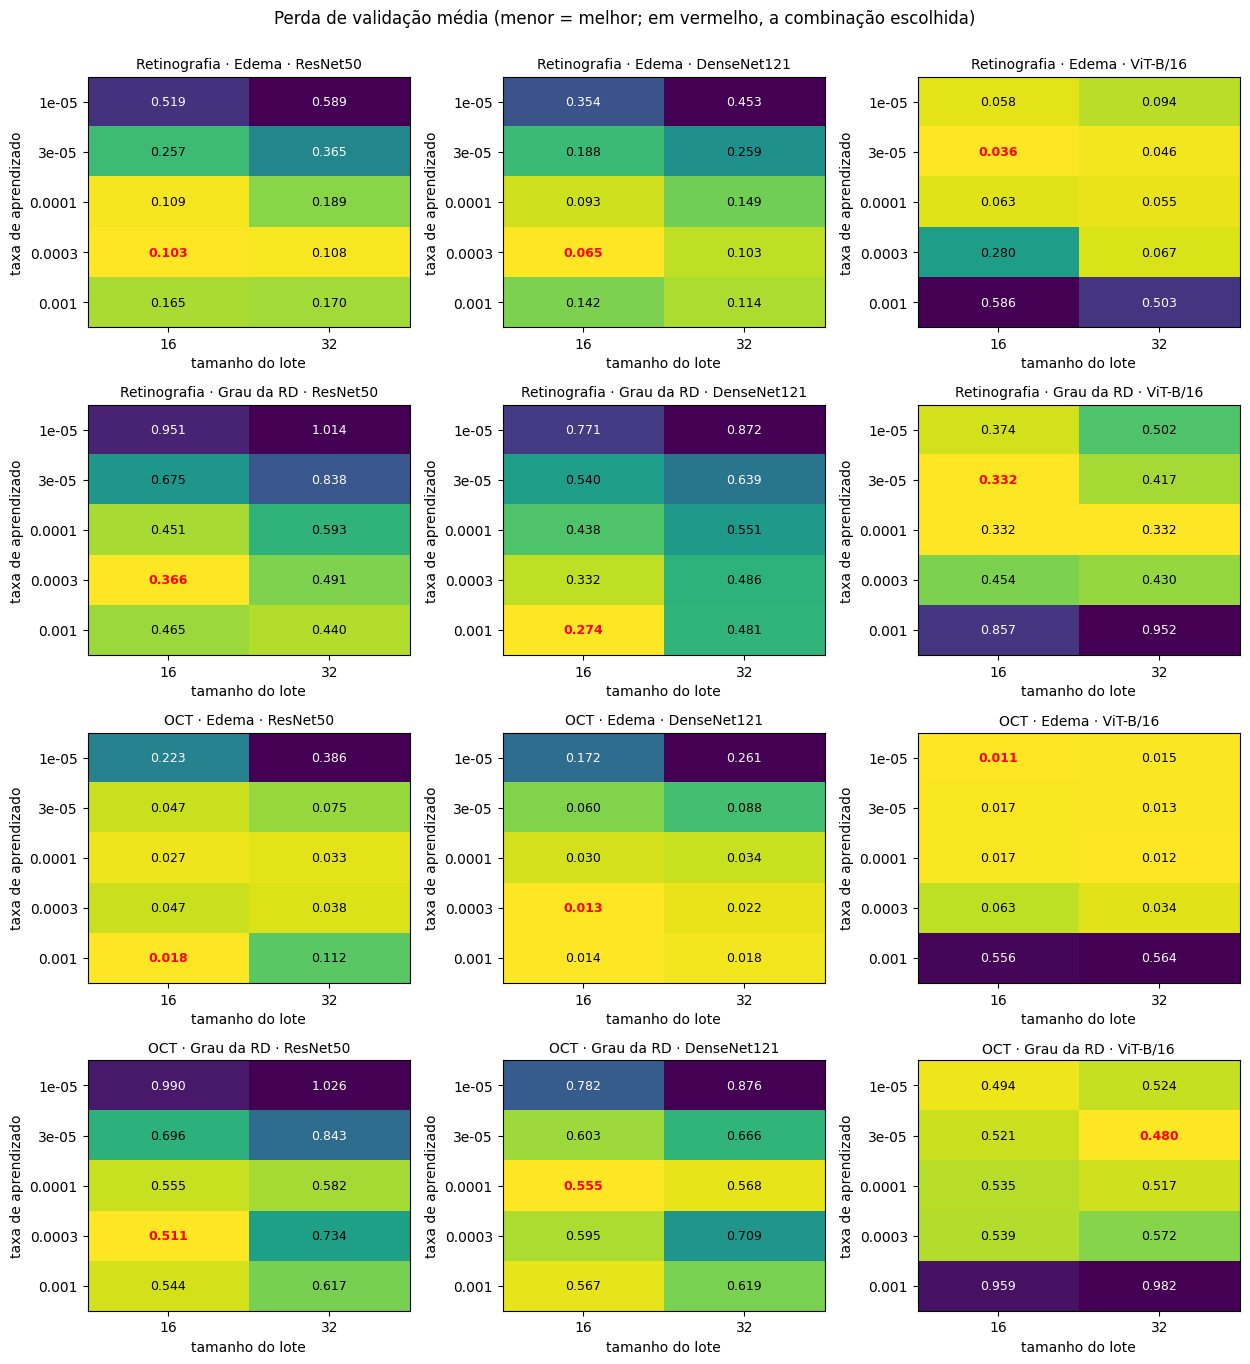

In [ ]:
# ===== 5.3 Grid search: taxa de aprendizado × tamanho do lote =====
# Para cada caso (modalidade × tarefa × arquitetura), testa todas as combinações da grade
# em cada rodada de FOLDS_GRID. Cada treino é salvo no Drive assim que termina:
# se a execução for interrompida, basta rodar de novo que ela continua de onde parou.

# Pré-carrega as imagens pré-processadas em memória (uma única vez), o que acelera muito os treinos
t0 = time.time()
for c in fundo_B['caminho']: obter_imagem(c, 'fundo')
for c in oct_B['caminho']: obter_imagem(c, 'oct')
print(f'{len(CACHE_IMG)} imagens pré-processadas em {time.time() - t0:.0f}s')

arq_grid = os.path.join(SAIDA, 'grid_search.csv')
CASOS = [(mod, tarefa) for mod in ['fundo', 'oct'] for tarefa in ['DME', 'DR']]
DF_MOD = {'fundo': fundo_B, 'oct': oct_B}
ROT_MOD = {'fundo': 'Retinografia', 'oct': 'OCT'}
ROT_TAR = {'DME': 'Edema', 'DR': 'Grau da RD'}

def carregar_grid():
    if os.path.isfile(arq_grid):
        return pd.read_csv(arq_grid)
    return pd.DataFrame(columns=['fold', 'modalidade', 'tarefa', 'arq', 'lr', 'batch', 'perda_val', 'auc_val', 'época'])

if GRID_SEARCH:
    grid = carregar_grid()
    feitos = {(int(r.fold), r.modalidade, r.tarefa, r.arq, float(r.lr), int(r.batch)) for r in grid.itertuples()}
    total = len(FOLDS_GRID) * len(CASOS) * len(ARQS) * len(GRID_LR) * len(GRID_BATCH)
    print(f'Grid search: {total} treinos no total, {len(feitos)} já concluídos.\n')
    for k in FOLDS_GRID:                      # primeiro toda a rodada 0, depois toda a rodada 1
        for mod, tarefa in CASOS:
            for arq in ARQS:
                for lr in GRID_LR:
                    for bs in GRID_BATCH:
                        chave = (k, mod, tarefa, arq, float(lr), int(bs))
                        if chave in feitos:
                            continue
                        _, _, h = treinar_modalidade(DF_MOD[mod], mod, tarefa, arq, k, lr=lr, batch=bs,
                                                     epocas=EPOCAS_GRID,
                                                     rotulo=f'grid fold{k} {ROT_MOD[mod]}/{ROT_TAR[tarefa]}/{NOME[arq]} lr={lr:g} lote={bs}')
                        i = h.perda_val.idxmin()
                        linha = pd.DataFrame([{'fold': k, 'modalidade': mod, 'tarefa': tarefa, 'arq': arq, 'lr': lr,
                                               'batch': bs, 'perda_val': h.perda_val[i], 'auc_val': h.auc_val[i],
                                               'época': int(h['época'][i])}])
                        grid = linha if grid.empty else pd.concat([grid, linha], ignore_index=True)   # CORRIGIDO
                        grid.to_csv(arq_grid, index=False)       # salva o progresso a cada treino
                        feitos.add(chave)
                        torch.cuda.empty_cache()

# ---- Escolha da melhor combinação para cada caso ----
grid = carregar_grid()
n_comb = len(GRID_LR) * len(GRID_BATCH)
linhas = []
for mod, tarefa in CASOS:
    for arq in ARQS:
        g = grid[(grid.modalidade == mod) & (grid.tarefa == tarefa) & (grid.arq == arq)]
        # usa apenas as rodadas em que TODAS as combinações foram testadas (comparação justa)
        completas = [f for f, gf in g.groupby('fold') if len(gf) == n_comb]
        if not completas:
            continue
        media = (g[g.fold.isin(completas)].groupby(['lr', 'batch'])
                 .agg(perda_val=('perda_val', 'mean'), auc_val=('auc_val', 'mean')).reset_index())
        melhor = media.loc[media.perda_val.idxmin()]
        HP[(mod, tarefa, arq)] = {'lr': float(melhor.lr), 'batch': int(melhor.batch)}
        linhas.append({'Modalidade': ROT_MOD[mod], 'Tarefa': ROT_TAR[tarefa], 'Rede': NOME[arq],
                       'Rodadas usadas': len(completas), 'Taxa escolhida': f'{melhor.lr:g}',
                       'Lote escolhido': int(melhor.batch), 'Perda val. (média)': melhor.perda_val,
                       'AUC val. (média)': melhor.auc_val})
tab_hp = pd.DataFrame(linhas)
tab_hp.to_csv(os.path.join(SAIDA, 'hiperparametros_escolhidos.csv'), index=False)
display(tab_hp.round(4))

# ---- Mapas de calor: perda de validação média de cada combinação ----
fig, axes = plt.subplots(len(CASOS), len(ARQS), figsize=(4.2 * len(ARQS), 3.4 * len(CASOS)))
for i, (mod, tarefa) in enumerate(CASOS):
    for j, arq in enumerate(ARQS):
        ax = axes[i, j]
        g = grid[(grid.modalidade == mod) & (grid.tarefa == tarefa) & (grid.arq == arq)]
        completas = [f for f, gf in g.groupby('fold') if len(gf) == n_comb]
        if not completas:
            ax.set_visible(False); continue
        piv = (g[g.fold.isin(completas)].groupby(['lr', 'batch']).perda_val.mean()
               .unstack('batch').reindex(index=GRID_LR, columns=GRID_BATCH))
        im = ax.imshow(piv.values, cmap='viridis_r', aspect='auto')
        ax.set_xticks(range(len(GRID_BATCH))); ax.set_xticklabels(GRID_BATCH)
        ax.set_yticks(range(len(GRID_LR))); ax.set_yticklabels([f'{v:g}' for v in GRID_LR])
        ax.set_xlabel('tamanho do lote'); ax.set_ylabel('taxa de aprendizado')
        esc = HP[(mod, tarefa, arq)]
        for a in range(piv.shape[0]):
            for b in range(piv.shape[1]):
                v = piv.values[a, b]
                destaque = GRID_LR[a] == esc['lr'] and GRID_BATCH[b] == esc['batch']
                cor = 'red' if destaque else ('white' if im.norm(v) > 0.5 else 'black')
                ax.text(b, a, f'{v:.3f}', ha='center', va='center', fontsize=9,
                        color=cor, fontweight='bold' if destaque else 'normal')
        ax.set_title(f'{ROT_MOD[mod]} · {ROT_TAR[tarefa]} · {NOME[arq]}', fontsize=10)
plt.suptitle('Perda de validação média (menor = melhor; em vermelho, a combinação escolhida)', y=1.0)
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, 'figuras', 'grid_search.png'), dpi=150, bbox_inches='tight'); plt.show()

import json
json.dump({f'{m}|{t}|{a}': v for (m, t, a), v in HP.items()},
          open(os.path.join(SAIDA, 'hiperparametros_escolhidos.json'), 'w'), indent=1)

### Resultado do *grid search*

**Combinações escolhidas (menor perda de validação média nas rodadas 0 e 1):**

| Exame | Tarefa | ResNet50 | DenseNet121 | ViT-B/16 |
|---|---|---|---|---|
| Retinografia | Edema | 0,0003 · lote 16 | 0,0003 · lote 16 | 0,00003 · lote 16 |
| Retinografia | Grau da RD | 0,0003 · lote 16 | 0,001 · lote 16 | 0,00003 · lote 16 |
| OCT | Edema | 0,001 · lote 16 | 0,0003 · lote 16 | 0,00001 · lote 16 |
| OCT | Grau da RD | 0,0003 · lote 16 | 0,0001 · lote 16 | 0,00003 · lote 32 |

**Principais observações:**

- **Tamanho do lote:** o lote de 16 imagens foi escolhido em 11 dos 12 casos. Lotes menores produzem atualizações mais frequentes e com mais variação, o que tende a favorecer o aprendizado em bases pequenas.
- **Taxa de aprendizado do ViT-B/16:** foi sempre a menor entre as arquiteturas (0,00001 a 0,00003), e a taxa de 0,001 produziu as maiores perdas de validação em todos os casos do ViT-B/16. Esse comportamento confirma a maior sensibilidade dos *transformers* à taxa de aprendizado durante o ajuste fino.
- **Redes convolucionais:** a ResNet50 e a DenseNet121 preferiram taxas maiores (0,0001 a 0,001) e apresentaram desempenho mais estável entre as combinações testadas.
- **Escolhas diferentes por exame e tarefa:** a mesma arquitetura recebeu combinações diferentes conforme o exame e a tarefa (por exemplo, a DenseNet121 utilizou 0,0003 no edema e 0,001 no grau da retinopatia, na retinografia). Isso confirma a importância de realizar a busca separadamente para cada caso, em vez de utilizar um valor único, como na versão anterior.

**Limitação:** em três casos, a combinação escolhida ficou no limite do intervalo testado (0,001 na ResNet50 com OCT para o edema e na DenseNet121 com retinografia para o grau; 0,00001 no ViT-B/16 com OCT para o edema). Nesses casos, valores além do intervalo poderiam ser avaliados; contudo, os mapas mostram que as diferenças de perda entre a combinação escolhida e suas vizinhas são pequenas.

## 6. Experimentos

Os experimentos são executados **rodada por rodada** da validação cruzada (5 rodadas). Em cada rodada, as etapas abaixo são realizadas em sequência, pois a fusão e a destilação utilizam as redes treinadas na mesma rodada.

**6.1 Modelos de uma modalidade:** as três arquiteturas (ResNet50, DenseNet121 e ViT-B/16) são treinadas separadamente com **retinografias** e com **OCT**, para a detecção do edema.

**6.2 Fusão das duas modalidades:** avalia se a combinação dos dois exames melhora a detecção, de duas formas:

- **Fusão tardia:** a probabilidade de edema de cada olho é a média das probabilidades da rede de retinografia e da rede de OCT. Não exige novo treinamento.
- **Fusão intermediária:** as características extraídas pelas duas redes são combinadas e analisadas em conjunto por uma nova camada de decisão, treinada com os pares de imagens do mesmo olho.

**6.3 Destilação de conhecimento (OCT → retinografia):** uma rede treinada com OCT (o "professor") orienta o treinamento da rede de retinografia (o "aluno"). Durante o treino, o aluno aprende tanto com o diagnóstico quanto com a opinião do professor. **No teste, o aluno utiliza apenas a retinografia.** O objetivo é verificar se o conhecimento da OCT, um exame mais caro e menos disponível, pode melhorar um modelo que depende apenas da retinografia.

Para que o professor não "conheça" previamente os olhos que vai ensinar, suas opiniões são geradas por validação cruzada interna: os pacientes de treino são divididos em três partes, e o professor opina sobre cada parte após ser treinado apenas com as outras duas.

**6.4 Grau da retinopatia:** as três arquiteturas são treinadas com retinografias e com OCT para classificar o grau da retinopatia diabética em três níveis (sem retinopatia, não proliferativa e proliferativa), além da fusão tardia das duas modalidades.

### Preparação

A célula a seguir define as funções utilizadas na fusão e na destilação e carrega em memória todas as imagens já pré-processadas, o que reduz o tempo dos treinamentos.

In [ ]:
DIM = {'resnet50': 2048, 'densenet121': 1024, 'vit_b_16': 768}

def remover_cabeca(m, arq):
    if arq == 'resnet50': m.fc = nn.Identity()
    elif arq == 'densenet121': m.classifier = nn.Identity()
    else: m.heads = nn.Identity()
    return m

class FusaoIntermediaria(nn.Module):
    def __init__(self, modelo_f, modelo_o, arq_f, arq_o, n_classes=2, p=0.3):
        super().__init__()
        self.bf = remover_cabeca(copy.deepcopy(modelo_f).cpu(), arq_f)
        self.bo = remover_cabeca(copy.deepcopy(modelo_o).cpu(), arq_o)
        self.cabeca = nn.Sequential(nn.Dropout(p), nn.Linear(DIM[arq_f] + DIM[arq_o], n_classes))
    def forward(self, x):
        xf, xo = x
        return self.cabeca(torch.cat([self.bf(xf), self.bo(xo)], dim=1))

def por_olho(pred):
    cols = [c for c in pred.columns if c.startswith('p') and c[1:].isdigit()]
    return pred.groupby(['olho_id', 'Paciente']).agg(y=('y', 'first'), **{c: (c, 'mean') for c in cols}).reset_index()

def professor_cruzado(k, n_partes=3):
    """Distribuições suaves do professor OCT para os olhos de treino do fold k (fora da amostra)."""
    d = oct_B.copy(); d['y'] = d['DME']
    tr, va, _ = separar(d, k)
    pacs = np.array(sorted(tr.Paciente.unique())); rng = np.random.RandomState(SEED + k); rng.shuffle(pacs)
    partes = np.array_split(pacs, n_partes); soft = {}
    for j, parte in enumerate(partes):
        tr_j = tr[~tr.Paciente.isin(parte)]; ap_j = tr[tr.Paciente.isin(parte)]
        hp = hp_de('oct', 'DME', ARQ_PROFESSOR)          # hiperparâmetros do grid search (OCT, edema)
        dl_tr = carregador(DSImagem(tr_j, 'oct', transformacao('oct', True)), True, hp['batch'])
        dl_va = carregador(DSImagem(va, 'oct', transformacao('oct', False)), False, hp['batch'])
        m, _ = treinar(criar_modelo(ARQ_PROFESSOR, 2), dl_tr, dl_va, tr_j['y'].values, 2, hp['lr'],
                       WD[ARQ_PROFESSOR], rotulo=f'professor OCT parte {j + 1}/{n_partes} fold{k}')
        P, _, _ = prever(m, carregador(DSImagem(ap_j, 'oct', transformacao('oct', False)), False, hp['batch']),
                         temperatura=KD_T)
        t = ap_j[['olho_id']].reset_index(drop=True).assign(p0=P[:, 0], p1=P[:, 1]).groupby('olho_id').mean()
        soft.update({o: np.array([r.p0, r.p1], dtype=np.float32) for o, r in t.iterrows()})
        del m; torch.cuda.empty_cache()
    return soft

def salvar(pred, nome):
    pred.to_csv(os.path.join(SAIDA, 'predicoes', nome + '.csv'), index=False)

# Pré-carrega as imagens pré-processadas em memória (uma única vez)
t0 = time.time()
for c in fundo_B['caminho']: obter_imagem(c, 'fundo')
for c in oct_B['caminho']: obter_imagem(c, 'oct')
print(f'{len(CACHE_IMG)} imagens pré-processadas em {time.time() - t0:.0f}s')

1658 imagens pré-processadas em 0s


### Execução dos experimentos

In [ ]:
HIST = {}
for k in FOLDS:
    flag = os.path.join(SAIDA, 'predicoes', f'fold{k}_concluido.flag')
    if os.path.isfile(flag):
        print(f'Fold {k} já concluído, pulando.'); continue
    print(f'\n========== FOLD {k} ==========')
    modelos_k = {}

    # 6.1 Modelos de uma modalidade (DME)
    for modalidade, df_mod in [('fundo', fundo_B), ('oct', oct_B)]:
        for arq in ARQS:
            m, pred, h = treinar_modalidade(df_mod, modalidade, 'DME', arq, k)
            salvar(pred.assign(modalidade=modalidade, arq=arq, fold=k), f'DME_{modalidade}_{arq}_fold{k}')
            HIST[(modalidade, 'DME', arq, k)] = h
            modelos_k[(modalidade, arq)] = m.cpu()
            if k == 0:
                torch.save(m.state_dict(), os.path.join(SAIDA, 'modelos', f'DME_{modalidade}_{arq}_fold0.pth'))
            torch.cuda.empty_cache()

    # 6.2 Fusão intermediária (mesma arquitetura nos dois ramos)
    if FUSAO_INTERMEDIARIA:
        pk = pares.copy(); pk['y'] = pk['DME']
        tr, va, te = separar(pk, k)
        for arq in ARQS:
            fus = FusaoIntermediaria(modelos_k[('fundo', arq)], modelos_k[('oct', arq)], arq, arq)
            dl_tr = carregador(DSPar(tr, transformacao('fundo', True), transformacao('oct', True)), True, BATCH_FUSAO)
            dl_va = carregador(DSPar(va, transformacao('fundo', False), transformacao('oct', False)), False, BATCH_FUSAO)
            dl_te = carregador(DSPar(te, transformacao('fundo', False), transformacao('oct', False)), False, BATCH_FUSAO)
            fixar_semente(SEED + k)
            # taxa de aprendizado da fusão: 30% da menor taxa escolhida entre os dois ramos
            lr_fus = 0.3 * min(hp_de('fundo', 'DME', arq)['lr'], hp_de('oct', 'DME', arq)['lr'])
            fus, h = treinar(fus, dl_tr, dl_va, tr['y'].values, 2, lr_fus, WD[arq],
                             rotulo=f'fusão intermediária {NOME[arq]} fold{k}')
            P, _, _ = prever(fus, dl_te)
            salvar(tabela_pred(te, P).assign(modalidade='fusao_intermediaria', arq=arq, fold=k),
                   f'DME_fusaoint_{arq}_fold{k}')
            HIST[('fusao', 'DME', arq, k)] = h
            del fus; torch.cuda.empty_cache()

    # 6.3 Destilação OCT -> retinografia
    soft = professor_cruzado(k)
    for arq in ARQS:
        m, pred, h = treinar_modalidade(fundo_B, 'fundo', 'DME', arq, k, soft=soft, kd_alpha=KD_ALPHA,
                                        rotulo=f'aluno KD {NOME[arq]} fold{k}')
        salvar(pred.assign(modalidade='fundo_kd', arq=arq, fold=k), f'DME_fundoKD_{arq}_fold{k}')
        if k == 0:
            torch.save(m.state_dict(), os.path.join(SAIDA, 'modelos', f'DME_fundoKD_{arq}_fold0.pth'))
        del m; torch.cuda.empty_cache()

    # 6.4 Grau da retinopatia (3 classes)
    if DR_TAMBEM:
        for modalidade, df_mod in [('fundo', fundo_B), ('oct', oct_B)]:
            for arq in ARQS:
                m, pred, h = treinar_modalidade(df_mod, modalidade, 'DR', arq, k)
                salvar(pred.assign(modalidade=modalidade, arq=arq, fold=k), f'DR_{modalidade}_{arq}_fold{k}')
                HIST[(modalidade, 'DR', arq, k)] = h
                if k == 0:
                    torch.save(m.state_dict(), os.path.join(SAIDA, 'modelos', f'DR_{modalidade}_{arq}_fold0.pth'))
                del m; torch.cuda.empty_cache()

    del modelos_k
    open(flag, 'w').write(time.ctime())
    pd.to_pickle(HIST, os.path.join(SAIDA, f'historicos_fold{k}.pkl'))

Fold 0 já concluído, pulando.
Fold 1 já concluído, pulando.
Fold 2 já concluído, pulando.
Fold 3 já concluído, pulando.
Fold 4 já concluído, pulando.


### Acompanhamento do treinamento

A saída apresenta, para cada treinamento das cinco rodadas, o número de épocas executadas, a menor perda obtida no conjunto de validação e a AUC de validação correspondente. Esses valores servem apenas para **acompanhar o treinamento**; os resultados de desempenho do estudo são calculados no conjunto de teste (Seção 7).

Padrões observados na validação:

- **Detecção do edema:** os modelos de OCT apresentaram, de forma geral, perdas de validação menores que os de retinografia, o que é esperado, pois a OCT permite visualizar diretamente o espessamento e o acúmulo de líquido na retina.
- **Grau da retinopatia:** foi a tarefa mais difícil. As perdas de validação foram mais altas, e vários treinamentos atingiram o melhor resultado nas primeiras épocas e foram interrompidos logo em seguida, indicando dificuldade em melhorar a separação entre os três graus.
- **Número de épocas:** variou bastante entre os treinamentos (de 7 a 25 épocas), o que mostra a importância da interrupção antecipada (*early stopping*), que ajusta automaticamente a duração de cada treinamento.

### Curvas de treinamento (primeira rodada)

Os gráficos mostram a evolução da **perda** (erro) ao longo das épocas para a detecção do edema, na primeira rodada da validação cruzada, para as três arquiteturas e as duas modalidades.

- **Linha de treino:** erro nas imagens utilizadas para o aprendizado.
- **Linha de validação:** erro nas imagens separadas para acompanhamento.
- **Linha tracejada:** época selecionada (menor perda de validação), cuja versão da rede é utilizada na avaliação final.

Quando a perda de treino continua diminuindo enquanto a perda de validação aumenta, a rede começa a memorizar as imagens de treino (*overfitting*). A seleção pela menor perda de validação evita que essa versão seja utilizada.

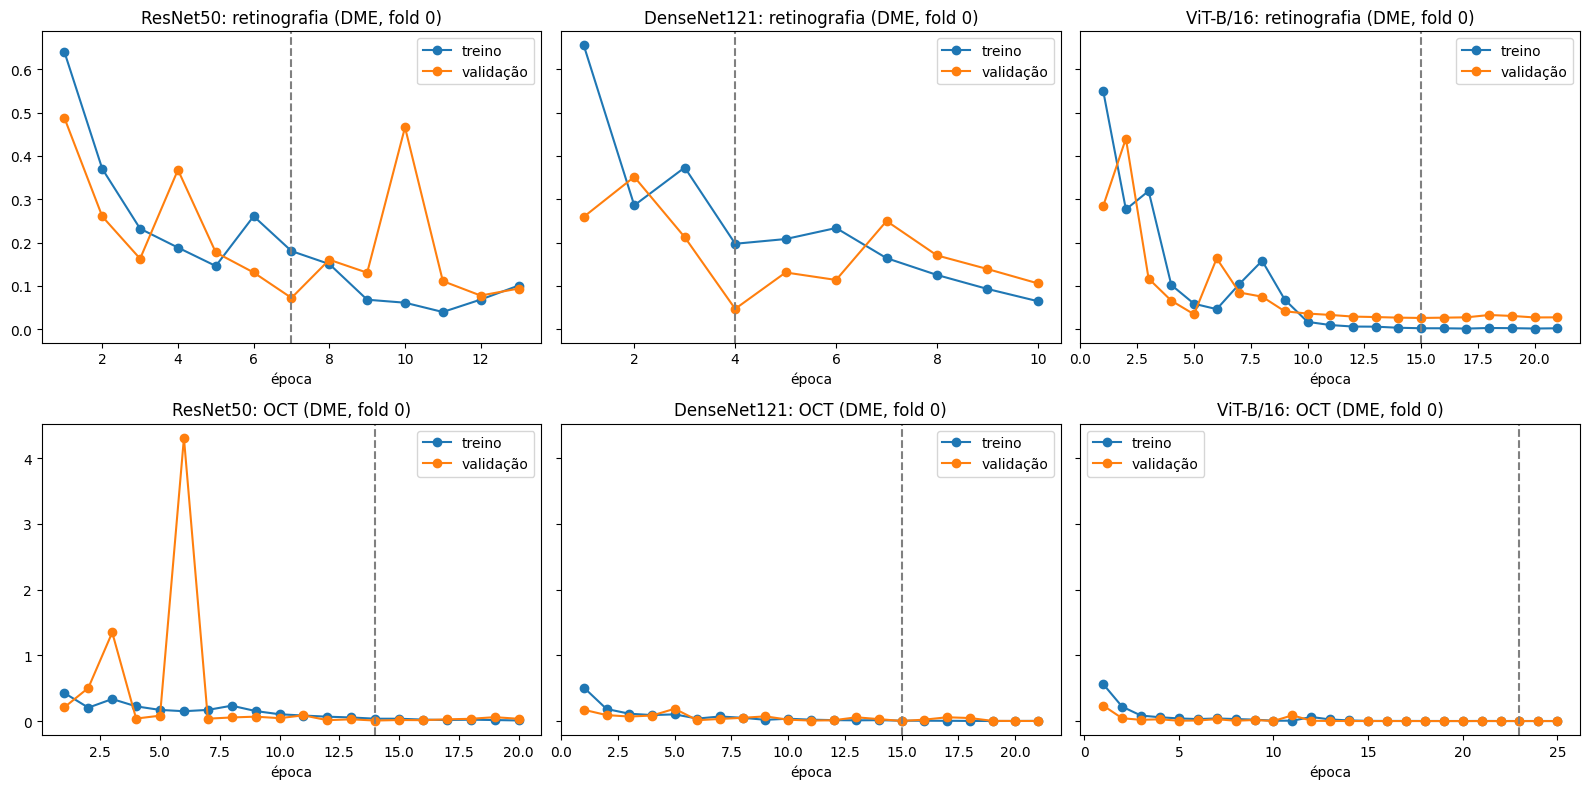

In [ ]:
H0 = {}
for f_ in glob.glob(os.path.join(SAIDA, 'historicos_fold*.pkl')):
    H0.update(pd.read_pickle(f_))
H0 = {**H0, **HIST}
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey='row')
for i, modalidade in enumerate(['fundo', 'oct']):
    for j, arq in enumerate(ARQS):
        h = H0.get((modalidade, 'DME', arq, 0))
        ax = axes[i, j]
        if h is None: ax.set_visible(False); continue
        ax.plot(h['época'], h['perda_treino'], 'o-', label='treino')
        ax.plot(h['época'], h['perda_val'], 'o-', label='validação')
        ax.axvline(h['época'][h.perda_val.idxmin()], ls='--', c='gray')
        ax.set_title(f'{NOME[arq]}: {"retinografia" if modalidade == "fundo" else "OCT"} (DME, fold 0)')
        ax.set_xlabel('época'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, 'figuras', 'curvas_fold0.png'), dpi=150); plt.show()

### Interpretação das curvas de treinamento

Os gráficos mostram a detecção do edema na primeira rodada, com os hiperparâmetros escolhidos pelo *grid search*.

- **Aprendizado:** em todas as arquiteturas e modalidades, as perdas de treino e de validação diminuíram de forma acentuada nas primeiras épocas, indicando que as redes aprenderam a tarefa.
- **Oscilações na validação:** a ResNet50 apresentou picos isolados na perda de validação, na retinografia (4ª e 10ª épocas) e principalmente na OCT (3ª e 6ª épocas), seguidos de retorno a valores baixos. Na OCT, a ResNet50 utilizou a maior taxa de aprendizado testada (0,001), o que torna o início do treinamento menos estável. Atenção à escala do eixo vertical da linha inferior, ampliada por esse pico.
- **Sobreajuste (*overfitting*):** na DenseNet121 com retinografia, a perda de validação atingiu o mínimo na 4ª época e voltou a subir nas épocas seguintes, enquanto a perda de treino continuou diminuindo. No ViT-B/16 com retinografia, a perda de treino chegou a praticamente zero após a 10ª época, enquanto a de validação permaneceu estável. Esses são os padrões típicos de memorização das imagens de treino, e a seleção pela menor perda de validação evitou a utilização das versões posteriores.
- **Retinografia × OCT:** as perdas de validação da OCT atingiram valores próximos de zero, enquanto as da retinografia se estabilizaram em torno de 0,03 a 0,10, coerente com a maior capacidade da OCT de evidenciar o edema.
- **Limite de épocas:** no ViT-B/16 com OCT, o treinamento chegou à 25ª época, o limite permitido, com a menor perda na 23ª. Como a perda já estava próxima de zero, épocas adicionais trariam pouco ganho.

## 7. Resultados

Os resultados são calculados sobre as **predições no conjunto de teste** de cada rodada da validação cruzada. As predições das rodadas são reunidas, de modo que **cada paciente da coorte B é avaliado exatamente uma vez**, por um modelo que não o viu durante o treinamento.

### 7.1 Métricas de desempenho e intervalos de confiança

**Detecção do edema (duas classes):**

| Métrica | O que mede |
|---|---|
| Sensibilidade | Proporção de casos com edema identificados |
| Especificidade | Proporção de casos sem edema identificados |
| Precisão | Proporção de acertos entre os casos apontados como edema |
| Acurácia balanceada | Média entre sensibilidade e especificidade |
| AUC | Capacidade de separar as classes em todos os limiares |
| AUPRC | Área sob a curva precisão-sensibilidade |
| F1, Kappa e MCC | Medidas globais, robustas ao desbalanceamento |

Um caso é classificado como edema quando a probabilidade estimada pela rede é igual ou superior a 0,5.

**Grau da retinopatia (três classes):**

- **Kappa quadrático ponderado:** principal métrica de graduação. Penaliza mais os erros entre graus distantes (por exemplo, sem retinopatia × proliferativa) do que entre graus vizinhos.
- **Acurácia balanceada, F1 macro e AUC macro:** desempenho médio entre os três graus.
- **Sensibilidade por grau:** proporção de acertos em cada nível.
- **AUC para qualquer retinopatia:** capacidade de distinguir olhos sem retinopatia de olhos com qualquer grau, relacionada à **detecção precoce** da doença.

**Intervalo de confiança de 95%:** estimado por *bootstrap*. Os pacientes são sorteados com reposição 1.000 vezes, e a métrica é recalculada a cada sorteio. O sorteio é feito por **paciente**, e não por imagem, pois imagens do mesmo paciente não são independentes entre si.

A célula a seguir apenas define essas funções; os resultados são apresentados nas próximas subseções.

In [ ]:
def metricas_bin(y, p, limiar=0.5):
    y = np.asarray(y).astype(int); yh = (np.asarray(p) >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {'Acurácia': accuracy_score(y, yh), 'Acurácia balanceada': balanced_accuracy_score(y, yh),
            'Sensibilidade': tp / (tp + fn) if tp + fn else np.nan,
            'Especificidade': tn / (tn + fp) if tn + fp else np.nan,
            'Precisão': precision_score(y, yh, zero_division=0), 'F1': f1_score(y, yh, zero_division=0),
            'AUC': roc_auc_score(y, p) if len(set(y)) == 2 else np.nan,
            'AUPRC': average_precision_score(y, p) if len(set(y)) == 2 else np.nan,
            'Kappa': cohen_kappa_score(y, yh), 'MCC': matthews_corrcoef(y, yh),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}

def metricas_multi(y, P):
    y = np.asarray(y).astype(int); yh = P.argmax(1)
    rec = recall_score(y, yh, labels=[0, 1, 2], average=None, zero_division=0)
    try:
        auc = roc_auc_score(y, P, multi_class='ovr', average='macro', labels=[0, 1, 2])
    except ValueError:
        auc = np.nan
    return {'Acurácia': accuracy_score(y, yh), 'Acurácia balanceada': balanced_accuracy_score(y, yh),
            'F1 macro': f1_score(y, yh, average='macro', zero_division=0),
            'Kappa quadrático': cohen_kappa_score(y, yh, weights='quadratic'), 'AUC macro': auc,
            'Sens. sem RD': rec[0], 'Sens. RDNP': rec[1], 'Sens. RDP': rec[2],
            # detecção precoce: qualquer RD (RDNP ou RDP) vs sem RD
            'AUC qualquer RD': roc_auc_score((y > 0).astype(int), P[:, 1:].sum(1)) if len(set(y > 0)) == 2 else np.nan}

def ic_bootstrap(df, func, n=1000, semente=0):
    """IC 95% reamostrando PACIENTES (respeita a correlação entre imagens/olhos do mesmo paciente)."""
    rng = np.random.RandomState(semente)
    grupos = df.groupby('Paciente').indices; chaves = np.array(list(grupos))
    vals = []
    for _ in range(n):
        idx = np.concatenate([grupos[c] for c in rng.choice(chaves, len(chaves), replace=True)])
        try:
            v = func(df.iloc[idx])
            if not np.isnan(v): vals.append(v)
        except ValueError:
            pass
    return np.percentile(vals, [2.5, 97.5]) if vals else (np.nan, np.nan)

def ler(padrao):
    arqs = sorted(glob.glob(os.path.join(SAIDA, 'predicoes', padrao)))
    return pd.concat([pd.read_csv(a, dtype={'Paciente': str}) for a in arqs], ignore_index=True) if arqs else None

### 7.2 Detecção do edema por modalidade (nível de imagem)

Desempenho de cada arquitetura na detecção do edema, considerando **todas as imagens de teste** de cada modalidade, sendo cada imagem avaliada individualmente:

- **Retinografia:** 545 imagens da coorte B;
- **OCT:** 1.113 imagens;
- **Retinografia + destilação:** rede de retinografia treinada com o auxílio da rede de OCT, mas avaliada **utilizando apenas a retinografia**.

Para cada combinação são apresentados a AUC com intervalo de confiança de 95%, a sensibilidade, a especificidade, a acurácia balanceada, o F1-score e o MCC. A tabela completa, com todas as métricas, é salva em `resultados_DME_imagem.csv`.

Como referência, é apresentada a AUC do classificador baseado apenas em cor (Seção 4.1), que as redes devem superar.

Como as modalidades possuem conjuntos de imagens diferentes, a comparação direta entre retinografia e OCT é feita na Seção 7.3, sobre os mesmos olhos.

In [ ]:
linhas = []
for modalidade, rot in [('fundo', 'Retinografia'), ('oct', 'OCT'), ('fundoKD', 'Retino + destilação')]:
    for arq in ARQS:
        d = ler(f'DME_{modalidade}_{arq}_fold*.csv')
        if d is None: continue
        m = metricas_bin(d.y, d.p1)
        lo, hi = ic_bootstrap(d, lambda x: roc_auc_score(x.y, x.p1))
        # AUC de cada rodada, calculada separadamente
        auc_folds = pd.Series([roc_auc_score(g.y, g.p1) if g.y.nunique() == 2 else np.nan
                               for _, g in d.groupby('fold')])
        linhas.append({'Entrada': rot, 'Modelo': NOME[arq], 'n imagens': len(d), **m,
                       'AUC IC95%': f'{lo:.3f}–{hi:.3f}', 'AUC folds (média±dp)': f'{auc_folds.mean():.3f}±{auc_folds.std():.3f}'})
tab_img = pd.DataFrame(linhas)

# Tabela completa (todas as métricas) salva no Drive
tab_img.to_csv(os.path.join(SAIDA, 'resultados_DME_imagem.csv'), index=False)

# Exibição resumida: apenas as métricas principais, para caber na tela
colunas = ['Entrada', 'Modelo', 'n imagens', 'AUC', 'AUC IC95%', 'Sensibilidade', 'Especificidade',
           'Acurácia balanceada', 'F1', 'MCC']
display(tab_img[colunas].round(3))
print(f'Referência "só cor" na coorte B: AUC = {AUC_COR_B:.3f}')

,Entrada,Modelo,n imagens,AUC,AUC IC95%,Sensibilidade,Especificidade,Acurácia balanceada,F1,MCC
0,Retinografia,ResNet50,545,0.941,0.912–0.966,0.685,0.925,0.805,0.578,0.532
1,Retinografia,DenseNet121,545,0.943,0.904–0.975,0.796,0.933,0.865,0.662,0.629
2,Retinografia,ViT-B/16,545,0.962,0.932–0.986,0.778,0.951,0.864,0.700,0.668
3,OCT,ResNet50,1113,0.988,0.977–0.996,0.928,0.982,0.955,0.914,0.899
4,OCT,DenseNet121,1113,0.992,0.983–0.998,0.940,0.988,0.964,0.937,0.926
5,OCT,ViT-B/16,1113,0.992,0.981–0.999,0.940,0.994,0.967,0.952,0.943
6,Retino + destilação,ResNet50,545,0.931,0.885–0.969,0.685,0.959,0.822,0.667,0.629
7,Retino + destilação,DenseNet121,545,0.965,0.943–0.983,0.722,0.961,0.842,0.696,0.662
8,Retino + destilação,ViT-B/16,545,0.949,0.894–0.987,0.778,0.963,0.871,0.737,0.707


Referência "só cor" na coorte B: AUC = 0.785


### Resultado: edema por modalidade (nível de imagem)

**AUC por modalidade e arquitetura (todas as imagens de teste):**

| Entrada | ResNet50 | DenseNet121 | ViT-B/16 |
|---|---|---|---|
| Retinografia | 0,941 | 0,943 | 0,962 |
| OCT | 0,988 | 0,992 | 0,992 |
| Retino + destilação | 0,931 | 0,965 | 0,949 |
| *Linha de base: apenas cor* | *0,785* | *0,785* | *0,785* |

- **Todas as redes superaram com ampla margem a linha de base** baseada apenas em cor (AUC = 0,785). Isso indica que as redes utilizam informações morfológicas da imagem, e não apenas a distribuição de cores.
- **Retinografia:** AUC entre 0,941 e 0,962, valores compatíveis com o patamar descrito na literatura (Seção 9), ao contrário dos valores próximos de 1,0 obtidos na primeira versão. O ViT-B/16 apresentou a maior AUC (0,962) e a maior especificidade (95,1%); a DenseNet121, a maior sensibilidade (79,6%).
- **OCT:** desempenho superior ao da retinografia nas três arquiteturas (AUC entre 0,988 e 0,992), com sensibilidade de 93% a 94% e especificidade de 98% a 99%. As três arquiteturas apresentaram desempenho praticamente equivalente.
- **Destilação:** não melhorou a retinografia de forma consistente. Houve melhora na DenseNet121 (de 0,943 para 0,965) e pequena piora na ResNet50 (de 0,941 para 0,931) e no ViT-B/16 (de 0,962 para 0,949). A significância dessas diferenças é avaliada na Seção 7.4.
- **F1-score e MCC da retinografia (0,53 a 0,70):** esses valores, mais baixos que a AUC, refletem a baixa proporção de imagens com edema na coorte B (cerca de 10%). Com poucos casos positivos, mesmo um número pequeno de falsos positivos reduz a precisão e, consequentemente, o F1-score.

### 7.3 Detecção do edema nos olhos pareados: a contribuição de cada modalidade

Esta análise responde à pergunta central do trabalho: **a OCT ajuda a retinografia a detectar o edema, e vice-versa?**

Para que a comparação seja justa, todas as abordagens são avaliadas **nos mesmos olhos de teste**: aqueles que possuem retinografia e OCT. A avaliação é feita **por olho**: quando um olho possui mais de uma imagem, sua probabilidade de edema é a média das probabilidades de suas imagens.

| Abordagem | Imagens utilizadas no teste |
|---|---|
| Retinografia | Apenas retinografia |
| OCT | Apenas OCT |
| Retino + destilação | Apenas retinografia (treinada com auxílio da OCT) |
| Fusão tardia | Retinografia e OCT (média das probabilidades) |
| Fusão intermediária | Retinografia e OCT (características combinadas) |

**Interpretação das comparações:**

- **Fusão melhor que retinografia:** a OCT acrescenta informação à retinografia.
- **Fusão melhor que OCT:** a retinografia acrescenta informação à OCT.
- **Destilação melhor que retinografia:** o conhecimento da OCT melhora o modelo de retinografia **mesmo quando a OCT não está disponível** no momento do exame.

A significância estatística dessas diferenças é avaliada na subseção seguinte.

In [ ]:
def restringir_pares(d):
    return d[d.olho_id.isin(set(olhos.olho_id))]

linhas, OLHO = [], {}
for arq in ARQS:
    for modalidade in ['fundo', 'oct', 'fundoKD', 'fusaoint']:
        d = ler(f'DME_{modalidade}_{arq}_fold*.csv')
        if d is None: continue
        OLHO[(modalidade, arq)] = por_olho(restringir_pares(d))
    # Fusão tardia: média das probabilidades da retinografia e da OCT de cada olho
    if ('fundo', arq) in OLHO and ('oct', arq) in OLHO:
        a = OLHO[('fundo', arq)].set_index('olho_id'); b = OLHO[('oct', arq)].set_index('olho_id')
        tard = a[['Paciente', 'y']].copy(); tard['p1'] = (a['p1'] + b.loc[a.index, 'p1']) / 2
        OLHO[('fusaotardia', arq)] = tard.reset_index()

ROT = {'fundo': 'Retinografia', 'oct': 'OCT', 'fundoKD': 'Retino + destilação',
       'fusaotardia': 'Fusão tardia', 'fusaoint': 'Fusão intermediária'}
for (modalidade, arq), d in OLHO.items():
    m = metricas_bin(d.y, d.p1)
    lo, hi = ic_bootstrap(d, lambda x: roc_auc_score(x.y, x.p1))
    linhas.append({'Entrada': ROT[modalidade], 'Modelo': NOME[arq], 'olhos': len(d), **m, 'AUC IC95%': f'{lo:.3f}–{hi:.3f}'})
tab_olho = pd.DataFrame(linhas)
ordem = list(ROT.values())
tab_olho['ord'] = tab_olho['Entrada'].map({v: i for i, v in enumerate(ordem)})
tab_olho = tab_olho.sort_values(['Modelo', 'ord']).drop(columns='ord')

# Tabela completa salva no Drive; exibição apenas das métricas principais
tab_olho.to_csv(os.path.join(SAIDA, 'resultados_DME_olhos_pareados.csv'), index=False)
display(tab_olho[['Entrada', 'Modelo', 'olhos', 'AUC', 'AUC IC95%', 'Sensibilidade', 'Especificidade',
                  'Acurácia balanceada', 'F1', 'MCC']].round(3))

,Entrada,Modelo,olhos,AUC,AUC IC95%,Sensibilidade,Especificidade,Acurácia balanceada,F1,MCC
5,Retinografia,DenseNet121,410,0.945,0.911–0.972,0.843,0.914,0.878,0.688,0.649
6,OCT,DenseNet121,410,0.972,0.940–0.994,0.843,0.975,0.909,0.835,0.811
7,Retino + destilação,DenseNet121,410,0.961,0.937–0.980,0.745,0.950,0.847,0.710,0.668
9,Fusão tardia,DenseNet121,410,0.984,0.971–0.994,0.902,0.972,0.937,0.860,0.840
8,Fusão intermediária,DenseNet121,410,0.987,0.977–0.996,0.863,0.978,0.920,0.854,0.834
0,Retinografia,ResNet50,410,0.935,0.901–0.961,0.725,0.903,0.814,0.602,0.545
1,OCT,ResNet50,410,0.969,0.930–0.993,0.863,0.978,0.920,0.854,0.834
2,Retino + destilação,ResNet50,410,0.934,0.893–0.967,0.725,0.950,0.838,0.698,0.654
4,Fusão tardia,ResNet50,410,0.978,0.960–0.992,0.902,0.961,0.931,0.829,0.806
3,Fusão intermediária,ResNet50,410,0.961,0.912–0.992,0.843,0.975,0.909,0.835,0.811


### Resultado: edema nos olhos pareados

**AUC nos 410 olhos pareados (51 com edema):**

| Entrada | ResNet50 | DenseNet121 | ViT-B/16 |
|---|---|---|---|
| Retinografia | 0,935 | 0,945 | 0,961 |
| OCT | 0,969 | 0,972 | 0,975 |
| Retino + destilação | 0,934 | 0,961 | 0,954 |
| Fusão tardia | **0,978** | 0,984 | 0,978 |
| Fusão intermediária | 0,961 | **0,987** | **0,982** |

**Sensibilidade (proporção de olhos com edema identificados):**

| Entrada | ResNet50 | DenseNet121 | ViT-B/16 |
|---|---|---|---|
| Retinografia | 72,5% | 84,3% | 82,4% |
| OCT | 86,3% | 84,3% | 84,3% |
| Fusão tardia | **90,2%** | **90,2%** | 86,3% |
| Fusão intermediária | 84,3% | 86,3% | **88,2%** |

**Principais resultados:**

- **Uma das fusões obteve a maior AUC em cada arquitetura:** a fusão tardia na ResNet50 (0,978) e a fusão intermediária na DenseNet121 (0,987) e no ViT-B/16 (0,982). Em todas as arquiteturas, as duas fusões superaram a retinografia isolada.
- **A OCT acrescenta informação à retinografia:** com a fusão tardia, a sensibilidade passou de 72% a 84% (retinografia isolada) para 86% a 90%, mantendo a especificidade acima de 96%. Em termos práticos, a fusão tardia identificou de **2 a 9 olhos com edema a mais**, entre os 51 casos, do que a retinografia isolada. O maior ganho ocorreu na ResNet50, a arquitetura com a retinografia mais fraca.
- **Fusão tardia × intermediária:** a fusão intermediária, que exige um treinamento adicional, foi superior na DenseNet121 e no ViT-B/16, e inferior na ResNet50. A fusão tardia, que consiste apenas na média das probabilidades das duas redes, apresentou desempenho alto e estável nas três arquiteturas.
- **A destilação não melhorou a retinografia** de forma consistente: houve melhora na DenseNet121 e pequena piora no ViT-B/16, sem alteração na ResNet50.
- **Retinografia × OCT:** a OCT foi superior à retinografia nas três arquiteturas. A AUC da OCT nos olhos pareados (0,969 a 0,975) é inferior à observada em todas as imagens de OCT (0,988 a 0,992), o que indica que o subconjunto pareado inclui casos mais difíceis.

A significância estatística dessas diferenças é avaliada na Seção 7.4.

### 7.4 Teste de significância do ganho multimodal

Para verificar se as diferenças observadas na Seção 7.3 são estatisticamente sustentadas, calcula-se a **diferença de AUC (ΔAUC)** entre duas abordagens avaliadas nos mesmos olhos.

O intervalo de confiança de 95% dessa diferença é estimado por ***bootstrap* pareado**: os pacientes são sorteados com reposição 2.000 vezes e, em cada sorteio, as duas abordagens são avaliadas **sobre os mesmos olhos**. Isso torna a comparação mais precisa, pois elimina a variação causada por olhos diferentes.

**Leitura dos resultados:**

- **ΔAUC positivo:** a abordagem nova (fusão ou destilação) teve desempenho superior.
- **Intervalo que não contém o zero:** a diferença é **estatisticamente significativa**.
- **Intervalo que contém o zero:** não é possível afirmar que há diferença real entre as abordagens.

In [ ]:
def delta_auc(d1, d2, n=2000, semente=0):
    m = d1[['olho_id', 'Paciente', 'y', 'p1']].merge(d2[['olho_id', 'p1']], on='olho_id', suffixes=('_a', '_b'))
    obs = roc_auc_score(m.y, m.p1_b) - roc_auc_score(m.y, m.p1_a)
    lo, hi = ic_bootstrap(m, lambda x: roc_auc_score(x.y, x.p1_b) - roc_auc_score(x.y, x.p1_a), n, semente)
    return obs, lo, hi

COMPARACOES = [
    ('fundo', 'fusaotardia', 'OCT ajuda a retino?',             'Fusão tardia × Retino'),
    ('fundo', 'fusaoint',    'OCT ajuda a retino?',             'Fusão intermediária × Retino'),
    ('fundo', 'fundoKD',     'OCT ajuda (sem OCT no teste)?',   'Destilação × Retino'),
    ('oct',   'fusaotardia', 'Retino ajuda a OCT?',             'Fusão tardia × OCT'),
    ('oct',   'fusaoint',    'Retino ajuda a OCT?',             'Fusão intermediária × OCT'),
]

linhas = []
for arq in ARQS:
    for base, novo, pergunta, comparacao in COMPARACOES:
        if (base, arq) in OLHO and (novo, arq) in OLHO:
            obs, lo, hi = delta_auc(OLHO[(base, arq)], OLHO[(novo, arq)])
            linhas.append({'Modelo': NOME[arq], 'Pergunta': pergunta, 'Comparação': comparacao,
                           'ΔAUC': obs, 'IC95%': f'{lo:+.3f} a {hi:+.3f}',
                           'Significativo': 'sim' if lo > 0 or hi < 0 else 'não'})
tab_delta = pd.DataFrame(linhas)
tab_delta.to_csv(os.path.join(SAIDA, 'ganho_multimodal.csv'), index=False)
display(tab_delta.round(3))

,Modelo,Pergunta,Comparação,ΔAUC,IC95%,Significativo
0,ResNet50,OCT ajuda a retino?,Fusão tardia × Retino,0.043,+0.023 a +0.070,sim
1,ResNet50,OCT ajuda a retino?,Fusão intermediária × Retino,0.027,-0.017 a +0.068,não
2,ResNet50,OCT ajuda (sem OCT no teste)?,Destilação × Retino,-0.001,-0.029 a +0.027,não
3,ResNet50,Retino ajuda a OCT?,Fusão tardia × OCT,0.009,-0.010 a +0.038,não
4,ResNet50,Retino ajuda a OCT?,Fusão intermediária × OCT,-0.008,-0.020 a +0.002,não
5,DenseNet121,OCT ajuda a retino?,Fusão tardia × Retino,0.039,+0.014 a +0.071,sim
6,DenseNet121,OCT ajuda a retino?,Fusão intermediária × Retino,0.042,+0.017 a +0.075,sim
7,DenseNet121,OCT ajuda (sem OCT no teste)?,Destilação × Retino,0.015,-0.007 a +0.044,não
8,DenseNet121,Retino ajuda a OCT?,Fusão tardia × OCT,0.012,-0.004 a +0.035,não
9,DenseNet121,Retino ajuda a OCT?,Fusão intermediária × OCT,0.015,-0.002 a +0.040,não


### Resultado: teste de significância

**A OCT ajuda a retinografia? Sim, de forma estatisticamente significativa.**

| Comparação | ResNet50 | DenseNet121 | ViT-B/16 |
|---|---|---|---|
| Fusão tardia × Retinografia | **+0,043** ✔ | **+0,039** ✔ | **+0,017** ✔ |
| Fusão intermediária × Retinografia | +0,027 | **+0,042** ✔ | **+0,020** ✔ |
| Destilação × Retinografia | −0,001 | +0,015 | −0,007 |
| Fusão tardia × OCT | +0,009 | +0,012 | +0,003 |
| Fusão intermediária × OCT | −0,008 | +0,015 | +0,006 |

✔ = diferença estatisticamente significativa (intervalo de confiança de 95% não contém o zero).

**Principais resultados:**

- **Fusão tardia × retinografia:** o ganho foi **significativo nas três arquiteturas**, com intervalos de confiança inteiramente positivos (limites inferiores entre +0,003 e +0,023). Como foram realizadas 15 comparações, um resultado significativo isolado poderia ocorrer por acaso; porém, a **repetição do mesmo resultado nas três arquiteturas** torna essa conclusão robusta.
- **Fusão intermediária × retinografia:** ganho significativo na DenseNet121 e no ViT-B/16. Na ResNet50, o ganho foi positivo, mas não significativo.
- **A retinografia ajuda a OCT?** Os ganhos das fusões sobre a OCT isolada foram pequenos (−0,008 a +0,015) e **não significativos** em nenhuma arquitetura. A OCT isolada já apresenta desempenho elevado, restando pouco espaço para melhora.
- **Destilação:** as diferenças **não foram significativas**, e o sinal variou entre as arquiteturas. Não há evidência de que o conhecimento da OCT, transferido durante o treinamento, melhore a rede de retinografia quando a OCT não está disponível no teste.

**Conclusão:** a OCT contribui de forma consistente para a detecção do edema quando **as duas imagens estão disponíveis**. A fusão tardia (média das probabilidades) foi a única abordagem com ganho significativo nas três arquiteturas, sendo a forma mais simples e robusta de combinar os dois exames.

### 7.5 Curvas ROC nos olhos pareados

As curvas ROC (*Receiver Operating Characteristic*) mostram, para cada abordagem, a relação entre a **sensibilidade** (proporção de olhos com edema identificados) e a **taxa de falsos positivos** (1 − especificidade), em todos os limiares de decisão possíveis.

- Quanto mais próxima a curva estiver do **canto superior esquerdo**, melhor o desempenho.
- A **linha diagonal tracejada** representa um classificador aleatório (AUC = 0,5).
- A **AUC** de cada abordagem, indicada na legenda, corresponde à área sob a curva.

É apresentado um gráfico para cada arquitetura, comparando as cinco abordagens avaliadas nos mesmos olhos (Seção 7.3).

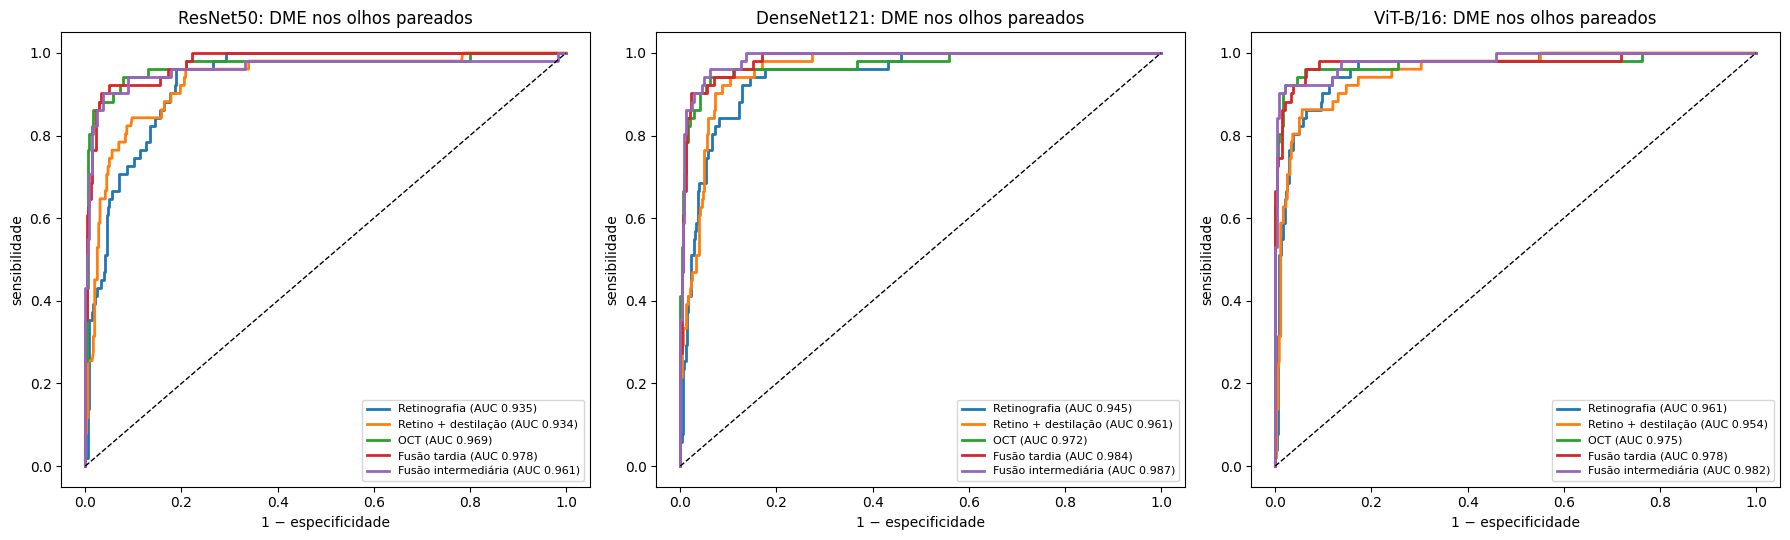

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, arq in zip(axes, ARQS):
    for modalidade in ['fundo', 'fundoKD', 'oct', 'fusaotardia', 'fusaoint']:
        d = OLHO.get((modalidade, arq))
        if d is None: continue
        fpr, tpr, _ = roc_curve(d.y, d.p1)
        ax.plot(fpr, tpr, lw=2, label=f'{ROT[modalidade]} (AUC {roc_auc_score(d.y, d.p1):.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_title(f'{NOME[arq]}: DME nos olhos pareados')
    ax.set_xlabel('1 − especificidade'); ax.set_ylabel('sensibilidade'); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, 'figuras', 'roc_multimodal.png'), dpi=150); plt.show()

### Resultado: curvas ROC

- Em todas as arquiteturas, as curvas de todas as abordagens permanecem próximas ao canto superior esquerdo e distantes da diagonal, indicando bom desempenho na detecção do edema.
- As **fusões** (curvas vermelha e roxa) e a **OCT** (curva verde) ficam mais próximas do canto superior esquerdo, atingindo sensibilidade próxima de 90% com taxa de falsos positivos de cerca de 5%.
- A **retinografia isolada** (curva azul) fica abaixo das demais principalmente na região de **baixa taxa de falsos positivos**: para manter poucos alarmes falsos, a retinografia identifica menos olhos com edema. A diferença é mais visível na ResNet50 e na DenseNet121; no ViT-B/16, as curvas ficam mais próximas entre si.
- A **destilação** (curva laranja) acompanha de perto a retinografia isolada, coerente com a ausência de ganho significativo (Seção 7.4).
- Na DenseNet121, a curva da OCT apresenta um longo trecho horizontal antes de atingir 100% de sensibilidade, indicando que poucos olhos com edema receberam probabilidade baixa pela rede de OCT. Nesses casos, a combinação com a retinografia na fusão ajudou a identificá-los.

### 7.6 Grau da retinopatia diabética

Esta análise avalia a capacidade das redes de classificar o **grau da retinopatia diabética** em três níveis:

- **Sem retinopatia (sem RD)**
- **Retinopatia diabética não proliferativa (RDNP):** estágio inicial e intermediário da doença
- **Retinopatia diabética proliferativa (RDP):** estágio avançado, com formação de novos vasos

**Limites da base de dados:**

- A base não subdivide a RDNP em leve, moderada e grave, como na escala internacional de 5 níveis (ICDR).
- A base **não contém informação sobre o tipo de diabetes** (tipo 1, tipo 2 ou gestacional), nem dados de glicemia ou hemoglobina glicada. O diagnóstico e a classificação do diabetes são feitos por exames laboratoriais; as imagens de retina permitem avaliar as **complicações oculares** da doença.
- Por isso, a **detecção mais precoce possível nesta base é a identificação da RDNP**, avaliada pela métrica *AUC qualquer RD* (olhos sem retinopatia × olhos com qualquer grau de retinopatia).

O edema macular pode ocorrer em qualquer estágio da retinopatia: na coorte B, 26 retinografias com RDNP e 28 com RDP apresentam edema.

**Comparações realizadas:** retinografia e OCT são avaliadas em todas as suas imagens de teste e, em seguida, **nos mesmos olhos pareados**, junto com a fusão tardia das duas modalidades.

**Principais métricas:** Kappa quadrático ponderado (com intervalo de confiança de 95%), acurácia balanceada, AUC para qualquer retinopatia e sensibilidade para RDNP e RDP.

In [ ]:
linhas, OLHO_DR = [], {}
for arq in ARQS:
    for modalidade, rot in [('fundo', 'Retinografia'), ('oct', 'OCT')]:
        d = ler(f'DR_{modalidade}_{arq}_fold*.csv')
        if d is None: continue
        P = d[['p0', 'p1', 'p2']].values
        lo, hi = ic_bootstrap(d, lambda x: cohen_kappa_score(x.y, x[['p0', 'p1', 'p2']].values.argmax(1), weights='quadratic'))
        linhas.append({'Entrada': rot, 'Modelo': NOME[arq], 'n': len(d), **metricas_multi(d.y, P),
                       'Kappa IC95%': f'{lo:.3f}–{hi:.3f}'})
        OLHO_DR[(modalidade, arq)] = por_olho(restringir_pares(d))
    # Comparação nos mesmos olhos (pareados) e fusão tardia
    if ('fundo', arq) in OLHO_DR and ('oct', arq) in OLHO_DR:
        a = OLHO_DR[('fundo', arq)].set_index('olho_id'); b = OLHO_DR[('oct', arq)].set_index('olho_id')
        comum = a.index.intersection(b.index)
        for rot, dd in [('Retino (pareados)', a.loc[comum]), ('OCT (pareados)', b.loc[comum])]:
            linhas.append({'Entrada': rot, 'Modelo': NOME[arq], 'n': len(dd), **metricas_multi(dd.y, dd[['p0', 'p1', 'p2']].values)})
        Pm = (a.loc[comum, ['p0', 'p1', 'p2']].values + b.loc[comum, ['p0', 'p1', 'p2']].values) / 2
        linhas.append({'Entrada': 'Fusão tardia (pareados)', 'Modelo': NOME[arq], 'n': len(comum),
                       **metricas_multi(a.loc[comum, 'y'], Pm)})
tab_dr = pd.DataFrame(linhas)

# Tabela completa salva no Drive; exibição apenas das métricas principais
tab_dr.to_csv(os.path.join(SAIDA, 'resultados_DR.csv'), index=False)
colunas = ['Entrada', 'Modelo', 'n', 'Kappa quadrático', 'Kappa IC95%', 'Acurácia balanceada',
           'AUC qualquer RD', 'Sens. RDNP', 'Sens. RDP']
display(tab_dr[colunas].round(3))

,Entrada,Modelo,n,Kappa quadrático,Kappa IC95%,Acurácia balanceada,AUC qualquer RD,Sens. RDNP,Sens. RDP
0,Retinografia,ResNet50,545,0.616,0.524–0.704,0.564,0.887,0.453,0.346
1,OCT,ResNet50,513,0.552,0.452–0.647,0.555,0.899,0.454,0.302
2,Retino (pareados),ResNet50,410,0.639,NaN,0.598,0.923,0.536,0.383
3,OCT (pareados),ResNet50,410,0.561,NaN,0.545,0.868,0.391,0.340
4,Fusão tardia (pareados),ResNet50,410,0.653,NaN,0.593,0.925,0.493,0.383
5,Retinografia,DenseNet121,545,0.676,0.584–0.756,0.645,0.878,0.421,0.673
6,OCT,DenseNet121,513,0.621,0.532–0.704,0.608,0.932,0.555,0.340
7,Retino (pareados),DenseNet121,410,0.721,NaN,0.677,0.906,0.478,0.723
8,OCT (pareados),DenseNet121,410,0.616,NaN,0.580,0.910,0.449,0.362
9,Fusão tardia (pareados),DenseNet121,410,0.724,NaN,0.655,0.935,0.522,0.532


### Resultado: grau da retinopatia

**Kappa quadrático ponderado (todas as imagens de teste):**

| Entrada | ResNet50 | DenseNet121 | ViT-B/16 |
|---|---|---|---|
| Retinografia | 0,616 | 0,676 | 0,679 |
| OCT | 0,552 | 0,621 | 0,642 |

**Nos olhos pareados (410 olhos):**

| Entrada | ResNet50 | DenseNet121 | ViT-B/16 |
|---|---|---|---|
| Retinografia | 0,639 | 0,721 | 0,690 |
| OCT | 0,561 | 0,616 | 0,631 |
| Fusão tardia | 0,653 | 0,724 | 0,710 |

**Principais resultados:**

- **A retinografia foi superior à OCT na graduação** nas três arquiteturas, tanto em todas as imagens quanto nos olhos pareados. Esse resultado é coerente do ponto de vista clínico: o grau da retinopatia é definido por lesões distribuídas por toda a retina (microaneurismas, hemorragias e neovasos), visíveis na retinografia, enquanto a OCT macular registra apenas um corte da região central.
- **Arquiteturas:** na coorte B completa, o ViT-B/16 (0,679) e a DenseNet121 (0,676) obtiveram os maiores valores de Kappa na retinografia, com intervalos de confiança amplamente sobrepostos. Na análise de robustez (Seção 7.8), a DenseNet121 foi a mais estável (0,655 no subgrupo). Não é possível afirmar que uma arquitetura seja superior às demais na graduação.
- **A fusão tardia trouxe pouco ganho na graduação:** o Kappa da fusão ficou ligeiramente acima do da retinografia isolada nas três arquiteturas (+0,003 a +0,020). Ao contrário do que ocorre no edema, a OCT acrescenta pouca informação à retinografia nesta tarefa.
- **Detecção precoce (AUC para qualquer retinopatia):** entre 0,878 e 0,915 na retinografia e entre 0,899 e 0,932 na OCT, indicando boa capacidade das duas modalidades de distinguir olhos sem retinopatia de olhos com algum grau da doença.
- **Retinopatia proliferativa (RDP):** foi a classe mais difícil, com sensibilidade de 35% a 67% na retinografia e de 30% a 34% na OCT. É também a classe com menos exemplos (52 retinografias e 53 OCTs).

**Efeito do *grid search* na OCT.** Na versão anterior, a taxa de aprendizado havia sido escolhida apenas com a retinografia na tarefa do edema e utilizada em todas as tarefas. Com hiperparâmetros escolhidos especificamente para a OCT na graduação:

| OCT, graduação | Versão anterior | Com *grid search* |
|---|---|---|
| Kappa quadrático | 0,513 a 0,642 | 0,552 a 0,642 |
| Sensibilidade para RDP | 11% a 34% | 30% a 34% |

O desempenho da OCT melhorou, principalmente na identificação da RDP pelas redes convolucionais. Mesmo assim, a OCT permaneceu inferior à retinografia na graduação, o que sugere que a principal limitação está no **tipo de imagem**: um único corte da mácula. Os estudos que obtêm bons resultados na graduação da retinopatia com OCT utilizam, em geral, a angiografia por OCT (OCTA) ou imagens que abrangem uma área maior da retina (Seção 9).

A comparação com a literatura é apresentada na Seção 9.

### 7.7 Matrizes de confusão: grau da retinopatia

As matrizes de confusão mostram como as predições de cada rede se distribuem entre os três graus de retinopatia:

- **Linhas:** grau real, definido pelos especialistas.
- **Colunas:** grau previsto pela rede.
- **Diagonal principal:** classificações corretas.
- **Fora da diagonal:** erros, permitindo identificar quais graus são confundidos entre si.

Erros entre graus vizinhos (por exemplo, RDNP classificada como RDP) são menos graves que erros entre graus distantes (por exemplo, RDP classificada como sem retinopatia), que representam casos graves não identificados. Essa diferença é considerada pelo Kappa quadrático ponderado (Seção 7.6).

São apresentadas as matrizes das três arquiteturas para retinografia (linha superior) e OCT (linha inferior), considerando todas as imagens de teste.

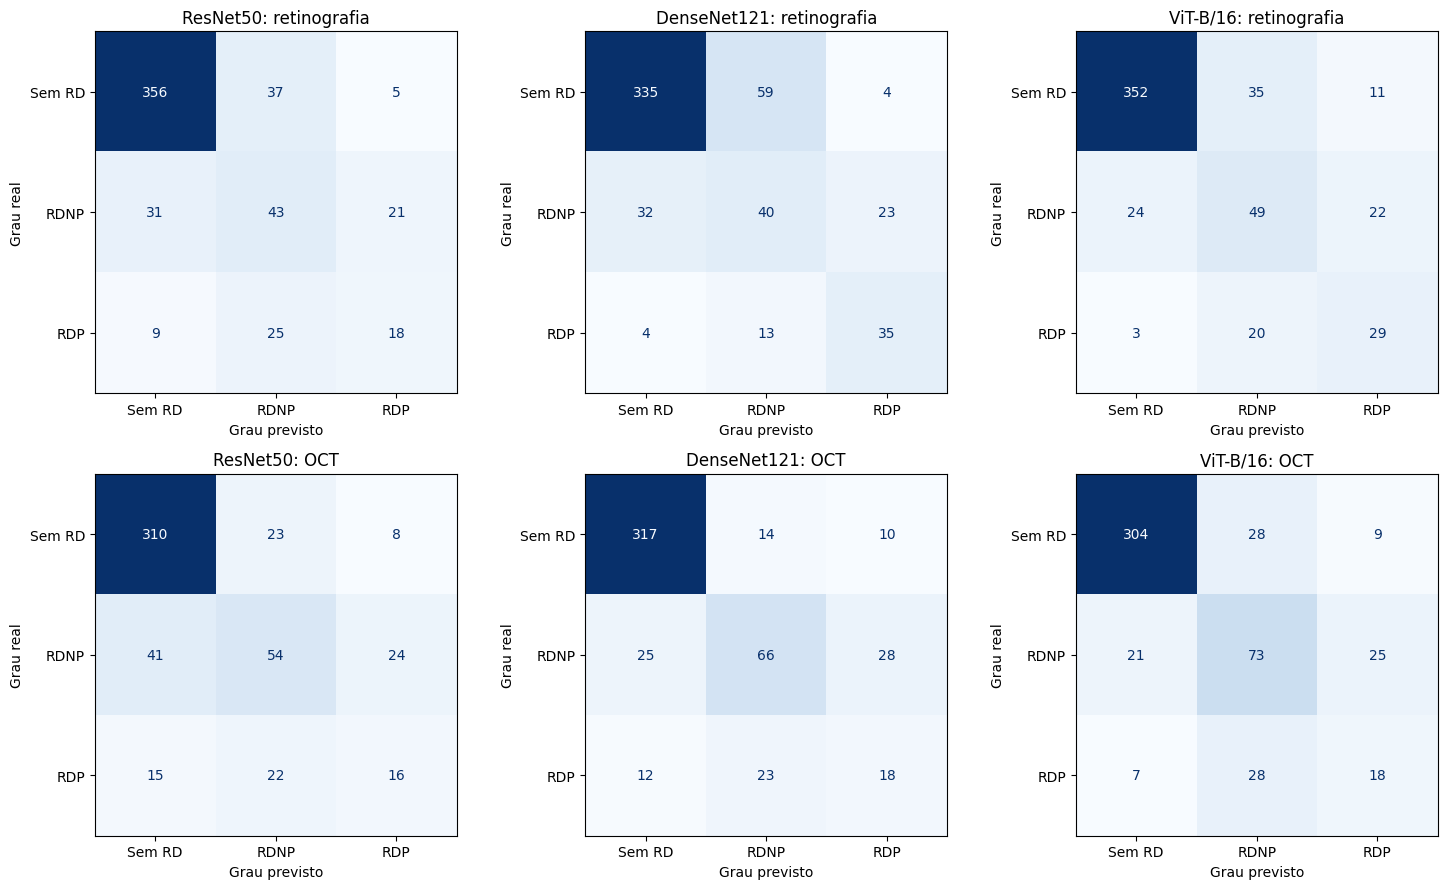

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for i, modalidade in enumerate(['fundo', 'oct']):
    for j, arq in enumerate(ARQS):
        d = ler(f'DR_{modalidade}_{arq}_fold*.csv'); ax = axes[i, j]
        if d is None: ax.set_visible(False); continue
        ConfusionMatrixDisplay(confusion_matrix(d.y, d[['p0', 'p1', 'p2']].values.argmax(1), labels=[0, 1, 2]),
                               display_labels=['Sem RD', 'RDNP', 'RDP']).plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f'{NOME[arq]}: {"retinografia" if modalidade == "fundo" else "OCT"}')
        ax.set_xlabel('Grau previsto')
        ax.set_ylabel('Grau real')
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, 'figuras', 'matrizes_DR.png'), dpi=150); plt.show()

### Resultado: matrizes de confusão

**Erros graves: casos de RDP classificados como sem retinopatia**

| Entrada | ResNet50 | DenseNet121 | ViT-B/16 |
|---|---|---|---|
| Retinografia (de 52 RDP) | 9 | 4 | 3 |
| OCT (de 53 RDP) | 15 | 12 | 7 |

**Casos de RDNP classificados como sem retinopatia** (relevante para a detecção precoce):

| Entrada | ResNet50 | DenseNet121 | ViT-B/16 |
|---|---|---|---|
| Retinografia (de 95 RDNP) | 31 | 32 | 24 |
| OCT (de 119 RDNP) | 41 | 25 | 21 |

**Principais resultados:**

- **A maior parte dos erros ocorreu entre graus vizinhos**, principalmente entre RDNP e RDP. Esse padrão também foi descrito por Rady et al. (2026) e reflete a dificuldade de distinguir estágios próximos da doença.
- **Erros graves foram pouco frequentes na retinografia:** de 3 a 9 dos 52 casos de RDP foram classificados como sem retinopatia. Na **OCT**, esse erro foi mais frequente (de 7 a 15 dos 53 casos), reforçando que a OCT macular, isoladamente, é menos adequada para a graduação da retinopatia.
- **O ViT-B/16 apresentou o menor número de erros graves** e de casos de RDNP não detectados nas duas modalidades. Contudo, a análise de robustez (Seção 7.8) indicou que o desempenho do ViT-B/16 na graduação cai de forma acentuada quando a avaliação é restrita aos pacientes 1957 a 2056. Essa diferença entre arquiteturas deve, portanto, ser interpretada com cautela.
- **Detecção precoce:** mesmo na arquitetura com melhor resultado, cerca de 1 em cada 4 casos de RDNP foi classificado como sem retinopatia na retinografia, indicando que a identificação dos estágios iniciais ainda é o principal desafio.

### 7.8 Análise de robustez: pacientes 1957 a 2056

Na coorte B, os olhos **sem retinopatia** concentram-se nos pacientes 1221 a 1500, enquanto a maior parte dos casos **com retinopatia e com edema** pertence aos pacientes 1957 a 2056 (Seção 10). Se esses grupos foram examinados em períodos ou condições diferentes, parte do desempenho das redes poderia refletir essa diferença, e não a doença.

Para verificar essa possibilidade, os resultados são recalculados **apenas para os pacientes 1957 a 2056**, grupo que contém imagens com e sem edema e os três graus de retinopatia, todos de um mesmo período:

- **Retinografias:** 175 imagens (54 com edema; 72 sem retinopatia, 59 RDNP e 44 RDP);
- **OCT:** 247 imagens (96 com edema);
- **Olhos pareados:** 172 olhos (51 com edema).

Nenhuma rede é treinada novamente: são utilizadas as mesmas predições da validação cruzada, restritas a esse subgrupo. Também é recalculada a linha de base baseada apenas em cor.

**Interpretação esperada:** se o desempenho no subgrupo for semelhante ao da coorte B completa, os resultados não dependem da diferença entre os grupos de pacientes. Uma queda acentuada indicaria que parte do desempenho se devia a essa diferença.

In [ ]:
# ===== Análise de robustez: apenas pacientes 1957 a 2056 =====
def subgrupo(d):
    return d[d['Paciente'].astype(int) >= 1957]

# Linha de base "apenas cor" dentro do subgrupo (predições fora da amostra da Seção 4.1)
mask_sub = (fundo_B['Paciente'].astype(int) >= 1957).values
auc_cor_sub = roc_auc_score(fundo_B['DME'].values[mask_sub], oof[mask_sub])

# --- Edema: retinografia e OCT (todas as imagens do subgrupo) ---
linhas = []
for modalidade, rot in [('fundo', 'Retinografia'), ('oct', 'OCT')]:
    for arq in ARQS:
        d = ler(f'DME_{modalidade}_{arq}_fold*.csv')
        if d is None: continue
        s = subgrupo(d)
        linhas.append({'Entrada': rot, 'Modelo': NOME[arq],
                       'n (com DME)': f'{len(s)} ({int(s.y.sum())})',
                       'AUC completa': roc_auc_score(d.y, d.p1),
                       'AUC subgrupo': roc_auc_score(s.y, s.p1),
                       'Sens. subgrupo': metricas_bin(s.y, s.p1)['Sensibilidade'],
                       'Esp. subgrupo': metricas_bin(s.y, s.p1)['Especificidade']})

# --- Edema: olhos pareados (retinografia, OCT e fusão tardia) ---
for arq in ARQS:
    for modalidade, rot in [('fundo', 'Retino (pareados)'), ('oct', 'OCT (pareados)'),
                            ('fusaotardia', 'Fusão tardia (pareados)')]:
        d = OLHO.get((modalidade, arq))
        if d is None: continue
        s = subgrupo(d)
        linhas.append({'Entrada': rot, 'Modelo': NOME[arq],
                       'n (com DME)': f'{len(s)} ({int(s.y.sum())})',
                       'AUC completa': roc_auc_score(d.y, d.p1),
                       'AUC subgrupo': roc_auc_score(s.y, s.p1),
                       'Sens. subgrupo': metricas_bin(s.y, s.p1)['Sensibilidade'],
                       'Esp. subgrupo': metricas_bin(s.y, s.p1)['Especificidade']})
tab_rob_dme = pd.DataFrame(linhas)
tab_rob_dme.to_csv(os.path.join(SAIDA, 'robustez_DME.csv'), index=False)
print(f'Linha de base "apenas cor" (retinografia): coorte B = {AUC_COR_B:.3f} | subgrupo = {auc_cor_sub:.3f}\n')
print('EDEMA: coorte B completa × subgrupo (pacientes 1957 a 2056)')
display(tab_rob_dme.round(3))

# --- Grau da retinopatia ---
linhas = []
for modalidade, rot in [('fundo', 'Retinografia'), ('oct', 'OCT')]:
    for arq in ARQS:
        d = ler(f'DR_{modalidade}_{arq}_fold*.csv')
        if d is None: continue
        s = subgrupo(d)
        mc = metricas_multi(d.y, d[['p0', 'p1', 'p2']].values)
        ms = metricas_multi(s.y, s[['p0', 'p1', 'p2']].values)
        cont = s.y.value_counts().reindex([0, 1, 2], fill_value=0)
        linhas.append({'Entrada': rot, 'Modelo': NOME[arq],
                       'n (sem RD/RDNP/RDP)': f'{len(s)} ({cont[0]}/{cont[1]}/{cont[2]})',
                       'Kappa quad. completa': mc['Kappa quadrático'],
                       'Kappa quad. subgrupo': ms['Kappa quadrático'],
                       'AUC qualquer RD completa': mc['AUC qualquer RD'],
                       'AUC qualquer RD subgrupo': ms['AUC qualquer RD']})
tab_rob_dr = pd.DataFrame(linhas)
tab_rob_dr.to_csv(os.path.join(SAIDA, 'robustez_DR.csv'), index=False)
print('\nGRAU DA RETINOPATIA: coorte B completa × subgrupo (pacientes 1957 a 2056)')
display(tab_rob_dr.round(3))

Linha de base "apenas cor" (retinografia): coorte B = 0.785 | subgrupo = 0.541

EDEMA: coorte B completa × subgrupo (pacientes 1957 a 2056)


,Entrada,Modelo,n (com DME),AUC completa,AUC subgrupo,Sens. subgrupo,Esp. subgrupo
0,Retinografia,ResNet50,175 (54),0.941,0.823,0.685,0.727
1,Retinografia,DenseNet121,175 (54),0.943,0.858,0.796,0.760
2,Retinografia,ViT-B/16,175 (54),0.962,0.901,0.778,0.868
3,OCT,ResNet50,247 (96),0.988,0.960,0.885,0.940
4,OCT,DenseNet121,247 (96),0.992,0.964,0.896,0.940
5,OCT,ViT-B/16,247 (96),0.992,0.982,0.906,0.980
6,Retino (pareados),ResNet50,172 (51),0.935,0.837,0.725,0.727
7,OCT (pareados),ResNet50,172 (51),0.969,0.950,0.863,0.942
8,Fusão tardia (pareados),ResNet50,172 (51),0.978,0.944,0.902,0.893
9,Retino (pareados),DenseNet121,172 (51),0.945,0.877,0.843,0.760



GRAU DA RETINOPATIA: coorte B completa × subgrupo (pacientes 1957 a 2056)


,Entrada,Modelo,n (sem RD/RDNP/RDP),Kappa quad. completa,Kappa quad. subgrupo,AUC qualquer RD completa,AUC qualquer RD subgrupo
0,Retinografia,ResNet50,175 (72/59/44),0.616,0.470,0.887,0.873
1,Retinografia,DenseNet121,175 (72/59/44),0.676,0.655,0.878,0.871
2,Retinografia,ViT-B/16,175 (72/59/44),0.679,0.525,0.915,0.896
3,OCT,ResNet50,247 (91/106/50),0.552,0.421,0.899,0.839
4,OCT,DenseNet121,247 (91/106/50),0.621,0.512,0.932,0.904
5,OCT,ViT-B/16,247 (91/106/50),0.642,0.495,0.926,0.890


### Resultado: análise de robustez

**1. A linha de base baseada apenas em cor caiu para 0,541**, próxima do acaso. No subgrupo de pacientes 1957 a 2056, a cor da imagem **não permite distinguir** olhos com e sem edema, o que torna esse subgrupo o cenário mais rigoroso para avaliar as redes.

**2. Edema na retinografia:** a AUC caiu de 0,941–0,962 (coorte B) para **0,823–0,901** (subgrupo), mas permaneceu **muito acima da linha de base** (0,541). Isso demonstra que as redes reconhecem o edema a partir de características morfológicas da imagem.

- A queda deve-se principalmente à **especificidade**, que passou de 93%–95% para 73%–87%. Na coorte B completa, a maioria dos olhos sem edema não tinha retinopatia, sendo fáceis de classificar. No subgrupo, os olhos sem edema apresentam retinopatia (com hemorragias e exsudatos), o que torna mais difícil distingui-los dos olhos com edema apenas pela retinografia. Esse cenário é mais próximo da prática clínica.
- O ViT-B/16 foi a arquitetura mais robusta (AUC de 0,901 no subgrupo), seguido da DenseNet121 (0,858) e da ResNet50 (0,823).

**3. Edema na OCT:** a AUC variou pouco (de 0,988–0,992 para **0,960–0,982**), mostrando que o desempenho da OCT é robusto, pois ela evidencia diretamente o espessamento da retina.

**4. A contribuição da OCT para a retinografia foi confirmada e ampliada.** Nos olhos pareados do subgrupo, a fusão tardia superou a retinografia isolada nas três arquiteturas:

| Ganho da fusão tardia sobre a retinografia | ResNet50 | DenseNet121 | ViT-B/16 |
|---|---|---|---|
| Coorte B completa | +0,043 | +0,039 | +0,017 |
| Subgrupo 1957 a 2056 | **+0,107** | **+0,080** | **+0,052** |

Quanto mais difícil o cenário para a retinografia, maior a contribuição da OCT. Já em relação à OCT isolada, a fusão apresentou diferenças pequenas (−0,006 a +0,008).

**5. Grau da retinopatia:**

- A **detecção de qualquer retinopatia** manteve-se estável na retinografia (AUC de 0,871 a 0,896 no subgrupo, contra 0,878 a 0,915 na coorte B), indicando que a **identificação dos casos iniciais é robusta**.
- O **Kappa quadrático da graduação em três níveis caiu** na retinografia (de 0,616–0,679 para 0,470–0,655) e na OCT (de 0,552–0,642 para 0,421–0,512). A **DenseNet121** foi a mais estável (de 0,676 para 0,655 na retinografia), enquanto o ViT-B/16 (de 0,679 para 0,525) e a ResNet50 (de 0,616 para 0,470) apresentaram quedas acentuadas.
- Parte dessa queda reflete a mudança na distribuição das classes, mais equilibrada no subgrupo (72 sem retinopatia, 59 RDNP e 44 RDP), o que torna a graduação mais difícil e afeta o Kappa. Outra parte pode refletir diferenças de aquisição entre os grupos de pacientes.

**Conclusão:** os dois principais resultados do trabalho se mantêm no cenário mais rigoroso: **(1) as redes reconhecem o edema na retinografia** e **(2) a OCT melhora de forma consistente a detecção do edema a partir da retinografia**. Os resultados da graduação em três níveis devem ser interpretados com cautela, especialmente a comparação entre arquiteturas.

### 7.9 Efeito do pré-processamento

Parte dos trabalhos da literatura utiliza as imagens sem pré-processamento, enquanto outros aplicam técnicas como o CLAHE. Para avaliar o efeito do pré-processamento adotado neste trabalho (Seção 3), os modelos de uma modalidade são treinados novamente **sem nenhum pré-processamento**, isto é, utilizando as imagens originais apenas redimensionadas, como na primeira versão:

- **Retinografia:** sem recorte do campo de visão e sem CLAHE;
- **OCT:** sem filtro de mediana.

**Procedimento:**

- São treinadas as três arquiteturas, nas duas modalidades e nas duas tarefas (edema e grau da retinopatia), nas cinco rodadas da validação cruzada, totalizando 60 treinamentos.
- São utilizados os **mesmos hiperparâmetros** escolhidos pelo *grid search* (Seção 5.3) e a **mesma divisão dos pacientes**. Assim, a única diferença entre as duas condições é o pré-processamento das imagens.
- As duas condições são comparadas **nas mesmas imagens de teste**. A diferença entre elas é avaliada por *bootstrap* pareado de pacientes, como na Seção 7.4: se o intervalo de confiança de 95% da diferença não contém o zero, a diferença é estatisticamente significativa.

**Observação:** como os hiperparâmetros foram escolhidos com as imagens pré-processadas, a comparação pode favorecer levemente a condição com pré-processamento.

1658 imagens sem pré-processamento carregadas em 17s

  sem pré-proc. fundo/DME/ResNet50/fold0: 19 épocas, melhor perda val 0.0390 (época 13), AUC val 0.994
  sem pré-proc. fundo/DME/DenseNet121/fold0: 10 épocas, melhor perda val 0.0594 (época 4), AUC val 0.994
  sem pré-proc. fundo/DME/ViT-B/16/fold0: 22 épocas, melhor perda val 0.0250 (época 16), AUC val 0.997
  sem pré-proc. oct/DME/ResNet50/fold0: 16 épocas, melhor perda val 0.0298 (época 10), AUC val 1.000
  sem pré-proc. oct/DME/DenseNet121/fold0: 15 épocas, melhor perda val 0.0086 (época 9), AUC val 1.000
  sem pré-proc. oct/DME/ViT-B/16/fold0: 22 épocas, melhor perda val 0.0008 (época 17), AUC val 1.000
  sem pré-proc. fundo/DR/ResNet50/fold0: 9 épocas, melhor perda val 0.2691 (época 3), AUC val 0.980
  sem pré-proc. fundo/DR/DenseNet121/fold0: 7 épocas, melhor perda val 0.3073 (época 1), AUC val 0.981
  sem pré-proc. fundo/DR/ViT-B/16/fold0: 14 épocas, melhor perda val 0.2721 (época 8), AUC val 0.964
  sem pré-proc. oct/DR/Res

,Tarefa,Exame,Rede,Métrica,Com pré-proc.,Sem pré-proc.,Diferença (com − sem),IC95%,Significativo
0,Edema,Retinografia,ResNet50,AUC,0.941,0.888,0.053,-0.013 a +0.152,não
1,Edema,Retinografia,DenseNet121,AUC,0.943,0.948,-0.004,-0.032 a +0.018,não
2,Edema,Retinografia,ViT-B/16,AUC,0.962,0.947,0.015,-0.002 a +0.036,não
3,Edema,OCT,ResNet50,AUC,0.988,0.992,-0.004,-0.014 a +0.004,não
4,Edema,OCT,DenseNet121,AUC,0.992,0.994,-0.002,-0.005 a -0.000,sim
5,Edema,OCT,ViT-B/16,AUC,0.992,0.994,-0.002,-0.005 a -0.000,sim
6,Grau da RD,Retinografia,ResNet50,Kappa quadrático,0.616,0.649,-0.033,-0.105 a +0.041,não
7,Grau da RD,Retinografia,ResNet50,AUC qualquer RD,0.887,0.912,-0.025,-0.073 a +0.016,não
8,Grau da RD,Retinografia,DenseNet121,Kappa quadrático,0.676,0.590,0.086,+0.001 a +0.170,sim
9,Grau da RD,Retinografia,DenseNet121,AUC qualquer RD,0.878,0.863,0.014,-0.023 a +0.047,não


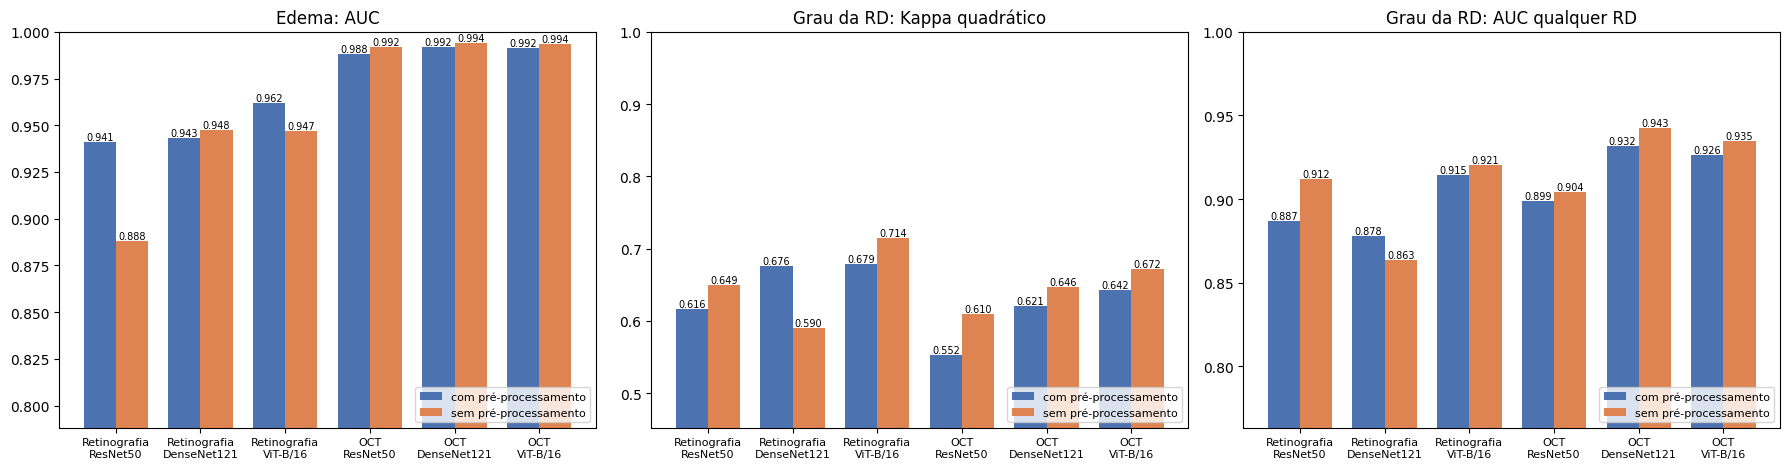

In [ ]:
# ===== 7.9 Comparação: com e sem pré-processamento =====
# Treina novamente os modelos de uma modalidade (edema e grau, retinografia e OCT, 3 redes, 5 rodadas)
# usando as imagens SEM pré-processamento (apenas redimensionadas, como na primeira versão),
# com os mesmos hiperparâmetros escolhidos pelo grid search. Cada treino é salvo assim que termina.
EXECUTAR_SEM_PREPROC = True

def preprocessar_sem(caminho, tam=CACHE):
    """Sem pré-processamento: apenas redimensiona a imagem original."""
    return Image.open(caminho).convert('RGB').resize((tam, tam), Image.BILINEAR)

CACHE_SEM = {}
def obter_imagem_sem(caminho, modalidade):
    if caminho not in CACHE_SEM:
        CACHE_SEM[caminho] = preprocessar_sem(caminho)
    return CACHE_SEM[caminho]

if EXECUTAR_SEM_PREPROC:
    t0 = time.time()
    for c in list(fundo_B['caminho']) + list(oct_B['caminho']):
        obter_imagem_sem(c, None)
    print(f'{len(CACHE_SEM)} imagens sem pré-processamento carregadas em {time.time() - t0:.0f}s\n')
    _obter_original = obter_imagem
    obter_imagem = obter_imagem_sem          # durante os treinos abaixo, as redes recebem as imagens sem pré-processamento
    try:
        for k in FOLDS:
            for tarefa in ['DME', 'DR']:
                for mod, df_mod in [('fundo', fundo_B), ('oct', oct_B)]:
                    for arq in ARQS:
                        nome = f'SEMPRE_{tarefa}_{mod}_{arq}_fold{k}'
                        if os.path.isfile(os.path.join(SAIDA, 'predicoes', nome + '.csv')):
                            continue
                        m, pred, h = treinar_modalidade(df_mod, mod, tarefa, arq, k,
                                                        rotulo=f'sem pré-proc. {mod}/{tarefa}/{NOME[arq]}/fold{k}')
                        salvar(pred.assign(modalidade=mod, arq=arq, fold=k), nome)
                        del m; torch.cuda.empty_cache()
    finally:
        obter_imagem = _obter_original       # restaura o pré-processamento padrão para as seções seguintes

# ---- Comparação: com × sem pré-processamento (mesmas imagens de teste) ----
def kappa_q(y, P):
    return cohen_kappa_score(y, P.argmax(1), weights='quadratic')

def auc_qualquer_rd(y, P):
    return roc_auc_score((np.asarray(y) > 0).astype(int), P[:, 1:].sum(1))

PC = ['p0', 'p1', 'p2']
METRICAS = {
    'DME': [('AUC', lambda x, s: roc_auc_score(x.y, x[f'p1{s}']))],
    'DR':  [('Kappa quadrático', lambda x, s: kappa_q(x.y, x[[c + s for c in PC]].values)),
            ('AUC qualquer RD', lambda x, s: auc_qualquer_rd(x.y, x[[c + s for c in PC]].values))],
}
ROT_EXAME = {'fundo': 'Retinografia', 'oct': 'OCT'}
ROT_TAREFA = {'DME': 'Edema', 'DR': 'Grau da RD'}
linhas = []
for tarefa in ['DME', 'DR']:
    for mod in ['fundo', 'oct']:
        for arq in ARQS:
            com = ler(f'{tarefa}_{mod}_{arq}_fold*.csv')
            sem = ler(f'SEMPRE_{tarefa}_{mod}_{arq}_fold*.csv')
            if com is None or sem is None:
                continue
            cols = ['p1'] if tarefa == 'DME' else PC
            m = com[['Name', 'Paciente', 'y'] + cols].merge(sem[['Name'] + cols], on='Name', suffixes=('_com', '_sem'))
            for metrica, f in METRICAS[tarefa]:
                v_com, v_sem = f(m, '_com'), f(m, '_sem')
                lo, hi = ic_bootstrap(m, lambda x: f(x, '_com') - f(x, '_sem'))
                linhas.append({'Tarefa': ROT_TAREFA[tarefa], 'Exame': ROT_EXAME[mod], 'Rede': NOME[arq],
                               'Métrica': metrica, 'Com pré-proc.': v_com, 'Sem pré-proc.': v_sem,
                               'Diferença (com − sem)': v_com - v_sem, 'IC95%': f'{lo:+.3f} a {hi:+.3f}',
                               'Significativo': 'sim' if lo > 0 or hi < 0 else 'não'})
tab_pre = pd.DataFrame(linhas)
tab_pre.to_csv(os.path.join(SAIDA, 'comparacao_preprocessamento.csv'), index=False)
display(tab_pre.round(3))

# ---- Gráfico ----
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (tarefa, metrica) in zip(axes, [('Edema', 'AUC'), ('Grau da RD', 'Kappa quadrático'), ('Grau da RD', 'AUC qualquer RD')]):
    t = tab_pre[(tab_pre['Tarefa'] == tarefa) & (tab_pre['Métrica'] == metrica)]
    if t.empty:
        ax.set_visible(False); continue
    rot = [f"{e}\n{r}" for e, r in zip(t['Exame'], t['Rede'])]
    x = np.arange(len(t)); w = 0.38
    b1 = ax.bar(x - w / 2, t['Com pré-proc.'], w, label='com pré-processamento', color='#4C72B0')
    b2 = ax.bar(x + w / 2, t['Sem pré-proc.'], w, label='sem pré-processamento', color='#DD8452')
    ax.bar_label(b1, fmt='%.3f', fontsize=7); ax.bar_label(b2, fmt='%.3f', fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(rot, fontsize=8)
    ax.set_ylim(max(0, min(t['Com pré-proc.'].min(), t['Sem pré-proc.'].min()) - 0.1), 1.0)
    ax.set_title(f'{tarefa}: {metrica}'); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, 'figuras', 'comparacao_preprocessamento.png'), dpi=150); plt.show()

### Resultado: efeito do pré-processamento

**Edema (AUC):**

| Exame | Rede | Com | Sem | Diferença |
|---|---|---|---|---|
| Retinografia | ResNet50 | 0,941 | 0,888 | +0,053 |
| Retinografia | DenseNet121 | 0,943 | 0,948 | −0,004 |
| Retinografia | ViT-B/16 | 0,962 | 0,947 | +0,015 |
| OCT | ResNet50 | 0,988 | 0,992 | −0,004 |
| OCT | DenseNet121 | 0,992 | 0,994 | −0,002 ✔ |
| OCT | ViT-B/16 | 0,992 | 0,994 | −0,002 ✔ |

**Grau da retinopatia (Kappa quadrático):**

| Exame | Rede | Com | Sem | Diferença |
|---|---|---|---|---|
| Retinografia | ResNet50 | 0,616 | 0,649 | −0,033 |
| Retinografia | DenseNet121 | 0,676 | 0,590 | +0,086 ✔ |
| Retinografia | ViT-B/16 | 0,679 | 0,714 | −0,035 |
| OCT | ResNet50 | 0,552 | 0,610 | −0,058 |
| OCT | DenseNet121 | 0,621 | 0,646 | −0,026 |
| OCT | ViT-B/16 | 0,642 | 0,672 | −0,030 |

✔ = diferença estatisticamente significativa. Diferença positiva: melhor **com** pré-processamento; negativa: melhor **sem**.

**Principais resultados:**

- **O pré-processamento não melhorou os resultados de forma consistente.** Das 18 comparações realizadas (incluindo a AUC para qualquer retinopatia, apresentada na tabela acima do gráfico), apenas 3 foram estatisticamente significativas, e em direções opostas.
- **Retinografia:** o efeito do CLAHE variou entre as arquiteturas. A maior diferença a favor do pré-processamento ocorreu na ResNet50 para o edema (+0,053), mas sem significância estatística, e na DenseNet121 para a graduação (+0,086), a única diferença significativa a favor do pré-processamento. Nas demais comparações, as imagens sem pré-processamento obtiveram resultados semelhantes ou ligeiramente superiores.
- **OCT:** em todas as comparações, os resultados **sem** o filtro de mediana foram iguais ou ligeiramente superiores. Na detecção do edema, as diferenças foram mínimas (0,002 a 0,004). Na graduação, a ausência do filtro produziu Kappa de 0,026 a 0,058 maior, sem significância estatística. Uma explicação possível é que o filtro, ao reduzir o ruído, também suaviza detalhes finos da estrutura das camadas da retina.
- Esses resultados foram obtidos com os hiperparâmetros escolhidos **com** pré-processamento, o que deveria favorecer essa condição. Ainda assim, ela não apresentou vantagem consistente.

**Conclusão:** neste trabalho, o pré-processamento **não é determinante** para o desempenho das redes, e **as conclusões principais não dependem dele**. Esse resultado é compatível com os estudos que utilizam as imagens sem pré-processamento. Na OCT, os resultados sugerem que o filtro de mediana pode ser dispensado.

## 8. Casos reais e mapas de atenção (Grad-CAM)

Esta seção apresenta **casos reais do conjunto de teste**, com a retinografia e a OCT do mesmo olho lado a lado, e os **mapas de atenção** de cada arquitetura.

### O que é o Grad-CAM

O **Grad-CAM** (*Gradient-weighted Class Activation Mapping*; Selvaraju et al., 2017) é um método de **inteligência artificial explicável (XAI)**. Ele gera um mapa de calor que indica **quais regiões da imagem mais influenciaram a decisão da rede**:

- **regiões vermelhas e amarelas:** maior influência na decisão;
- **regiões azuis:** pouca ou nenhuma influência.

Para a ResNet50 e a DenseNet121, o mapa é calculado na última camada convolucional. Para o ViT-B/16, é calculado na última camada de atenção, cujos 14 × 14 blocos da imagem são reorganizados na forma de um mapa.

### Casos apresentados

São sorteados dois olhos de teste da primeira rodada, ambos com retinografia e OCT: **um com edema** e **um sem edema**. Para cada imagem são apresentados o mapa de atenção das três arquiteturas e a probabilidade de edema estimada por cada uma (✓ acerto, ✗ erro).

### Interpretação esperada

- **Retinografia:** atenção concentrada na **mácula** e em lesões como **exsudatos duros**.
- **OCT:** atenção na **região central do corte**, onde se observam o espessamento da retina e o acúmulo de líquido.

Mapas com atenção concentrada na borda da imagem, em regiões sem estruturas anatômicas ou em artefatos de captura indicariam que a rede utiliza informações não relacionadas à doença.

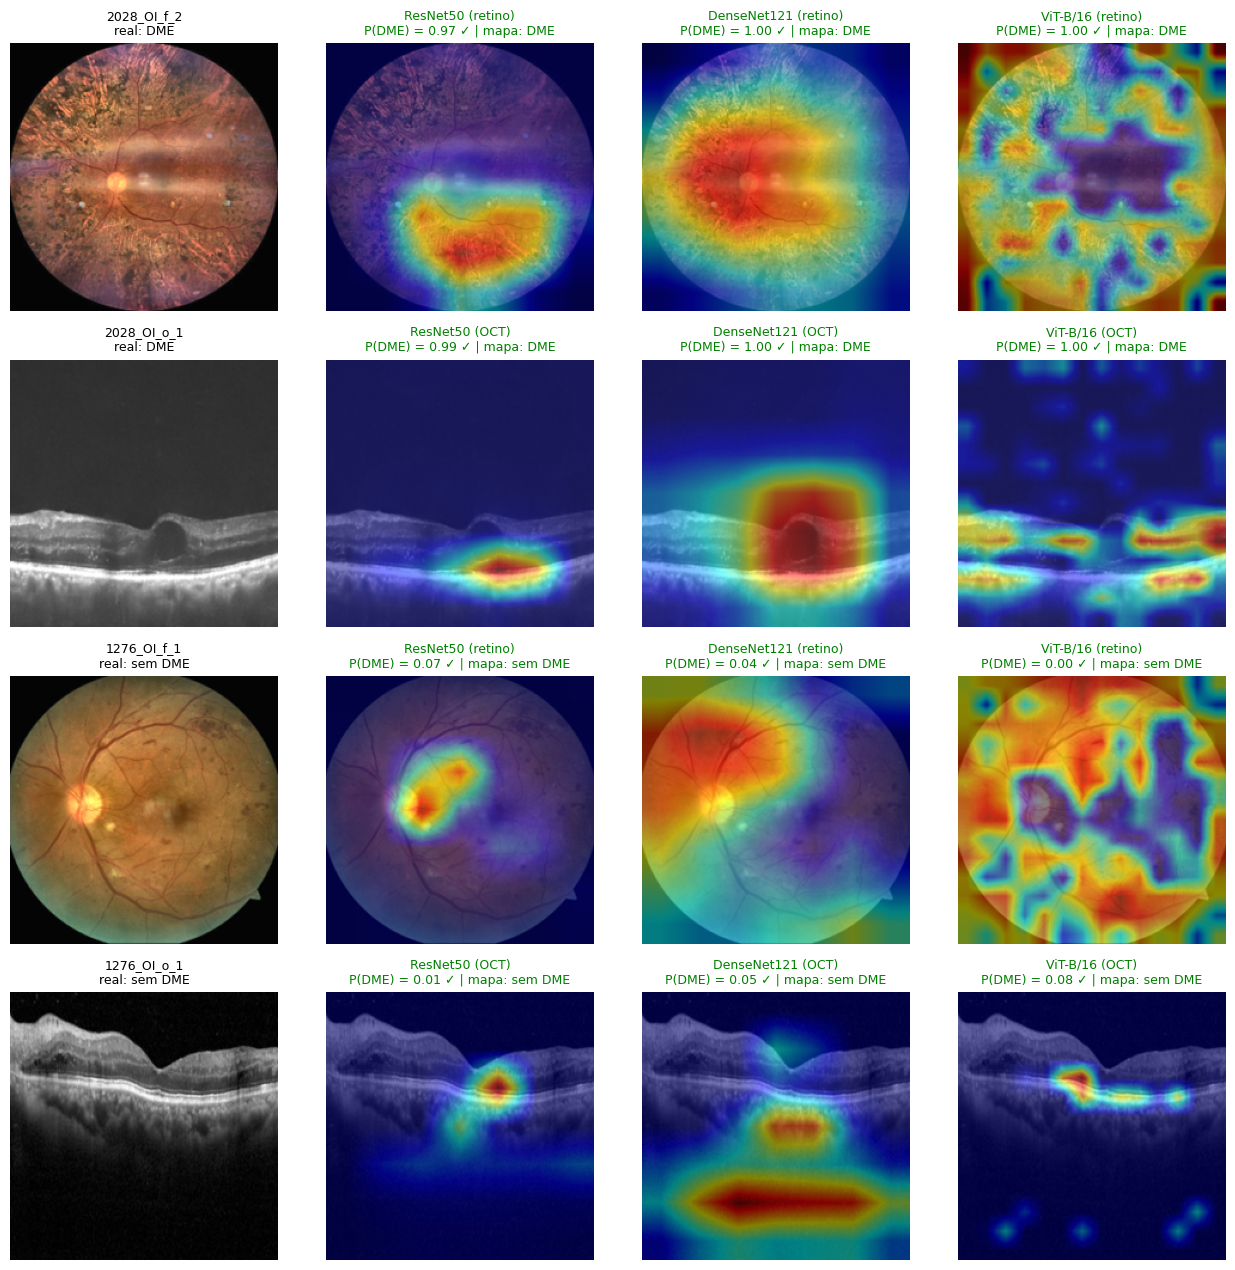

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

def camada_alvo(m, arq):
    if arq == 'resnet50': return [m.layer4[-1]]
    if arq == 'densenet121': return [m.features[-1]]
    return [m.encoder.layers[-1].ln_1]

def reshape_vit(t, h=14, w=14):
    return t[:, 1:, :].reshape(t.size(0), h, w, t.size(2)).permute(0, 3, 1, 2)

def gradcam(m, arq, x, classe=None):
    """Mapa Grad-CAM. Se classe=None, usa a classe prevista pela rede."""
    m.eval()
    with torch.no_grad():
        p = F.softmax(m(x.unsqueeze(0).to(device)).float(), 1)[0, 1].item()   # probabilidade de DME
    if classe is None:
        classe = 1 if p >= 0.5 else 0
    with GradCAM(model=m, target_layers=camada_alvo(m, arq),
                 reshape_transform=reshape_vit if arq == 'vit_b_16' else None) as cam:
        mapa = cam(input_tensor=x.unsqueeze(0).to(device), targets=[ClassifierOutputTarget(classe)])[0]
    return mapa, p, classe

def carregar_fold0(prefixo, modalidade, arq, n_cls=2):
    ck = os.path.join(SAIDA, 'modelos', f'{prefixo}_{modalidade}_{arq}_fold0.pth')
    if not os.path.isfile(ck): return None
    m = criar_modelo(arq, n_cls, pretreinado=False); m.load_state_dict(torch.load(ck, map_location='cpu'))
    return m.to(device).eval()

M0 = {(mod, arq): carregar_fold0('DME', mod, arq) for mod in ['fundo', 'oct'] for arq in ARQS}
tf_av = {'fundo': transformacao('fundo', False), 'oct': transformacao('oct', False)}

def figura_lado_a_lado(lista_olhos, arquivo):
    cols = 1 + len(ARQS)
    fig, axes = plt.subplots(len(lista_olhos) * 2, cols, figsize=(cols * 3.2, len(lista_olhos) * 6.4))
    for i, olho in enumerate(lista_olhos):
        r = pares[pares.olho_id == olho].iloc[0]
        for jm, (modalidade, cam_) in enumerate([('fundo', r['caminho_f']), ('oct', r['caminho_o'])]):
            linha = 2 * i + jm
            img = obter_imagem(cam_, modalidade).resize((IMG, IMG))
            base = np.asarray(img).astype(np.float32) / 255
            axes[linha, 0].imshow(img); axes[linha, 0].axis('off')
            axes[linha, 0].set_title(f"{r['Name_f'] if modalidade == 'fundo' else r['Name_o']}\n"
                                     f"real: {'DME' if r['DME'] else 'sem DME'}", fontsize=9)
            for j, arq in enumerate(ARQS):
                ax = axes[linha, j + 1]; ax.axis('off')
                m = M0.get((modalidade, arq))
                if m is None: continue
                mapa, p, classe = gradcam(m, arq, tf_av[modalidade](img))
                ok = (p >= .5) == bool(r['DME'])
                ax.imshow(show_cam_on_image(base, mapa, use_rgb=True))
                ax.set_title(f"{NOME[arq]} ({'retino' if modalidade == 'fundo' else 'OCT'})\n"
                             f"P(DME) = {p:.2f} {'✓' if ok else '✗'} | mapa: {'DME' if classe == 1 else 'sem DME'}",
                             fontsize=9, color='green' if ok else 'red')
    plt.tight_layout(); plt.savefig(arquivo, dpi=150, bbox_inches='tight'); plt.show()

teste0 = olhos[olhos.fold == 0]
rng = np.random.RandomState(7)
escolhidos = [rng.choice(teste0[teste0.DME == 1].olho_id), rng.choice(teste0[teste0.DME == 0].olho_id)]
if all(v is not None for v in M0.values()):
    figura_lado_a_lado(escolhidos, os.path.join(SAIDA, 'figuras', 'lado_a_lado_gradcam.png'))

### Resultado: mapas de atenção

Os mapas são apresentados para a **classe prevista** por cada rede: em uma imagem classificada como edema, indicam as regiões que levaram a essa decisão; em uma imagem classificada como sem edema, indicam as regiões que sustentaram a ausência de edema. Os casos são da primeira rodada da validação cruzada, e todas as redes classificaram corretamente os dois olhos, nas duas modalidades.

**Olho com edema (2028_OI)**

- **OCT:** a **DenseNet121** concentrou a atenção exatamente sobre o **espaço cístico** (acúmulo de líquido) visível no centro do corte, e a **ResNet50** sobre a região imediatamente abaixo dele, nas camadas externas da retina. Esse comportamento coincide com o achado que define o edema na OCT.
- **Retinografia:** esta imagem apresenta **artefatos de captura** (faixas claras horizontais). A **ResNet50** concentrou a atenção na região inferior à mácula, e a **DenseNet121**, de forma ampla, sobre a região central da retina, incluindo a mácula. Nenhuma das duas concentrou a atenção nas faixas de artefato.
- O **ViT-B/16** produziu mapas difusos nas duas modalidades, com atenção distribuída pelas camadas da retina na OCT e pela borda da imagem na retinografia.

**Olho sem edema (1276_OI)**

- **OCT:** a **ResNet50** e o **ViT-B/16** concentraram a atenção na **região da fóvea**, cuja depressão normal indica ausência de espessamento; a DenseNet121 apresentou atenção na fóvea e em uma faixa mais profunda do corte. Na versão anterior, com hiperparâmetros não ajustados, duas redes haviam classificado incorretamente este olho como edema, com 99% de probabilidade; após o *grid search*, as três redes o classificaram corretamente.
- **Retinografia:** a **ResNet50** concentrou a atenção no **disco óptico** e na região entre o disco e a mácula. A DenseNet121 e o ViT-B/16 apresentaram atenção em regiões mais periféricas.

**Síntese**

- As redes convolucionais, especialmente na **OCT**, concentraram a atenção em **estruturas clinicamente relevantes** para o diagnóstico do edema.
- Os mapas do **ViT-B/16 foram difusos** em todos os casos. O Grad-CAM foi desenvolvido para redes convolucionais e tende a produzir mapas pouco localizados em *transformers*. Métodos específicos para essa arquitetura, como o *attention rollout*, podem fornecer explicações mais adequadas.
- A análise de apenas dois olhos é ilustrativa. Uma avaliação sistemática dos mapas, em um número maior de casos e com a participação de um oftalmologista, é necessária para conclusões gerais.

### 8.1 Mapas de atenção dos modelos da primeira versão

Os mapas de Grad-CAM são aplicados aos **modelos treinados na primeira versão** (base completa, com viés de coorte), utilizando três imagens do conjunto de teste daquela versão:

1. **Coorte A com edema:** imagem do grupo com características de aquisição distintas;
2. **Coorte B com edema:** imagem com edema e mesma origem das imagens sem edema;
3. **Coorte B sem edema.**

As imagens recebem o mesmo tratamento utilizado no treinamento da primeira versão (apenas redimensionamento e normalização).

**Objetivo:** verificar visualmente se os modelos da primeira versão baseavam suas decisões em **estruturas da retina** ou em **características da aquisição**, como a borda escura e a iluminação da imagem. Atenção concentrada na borda, em regiões sem estruturas anatômicas ou distribuída de forma uniforme pela imagem indicaria o uso do atalho identificado na Seção 2.

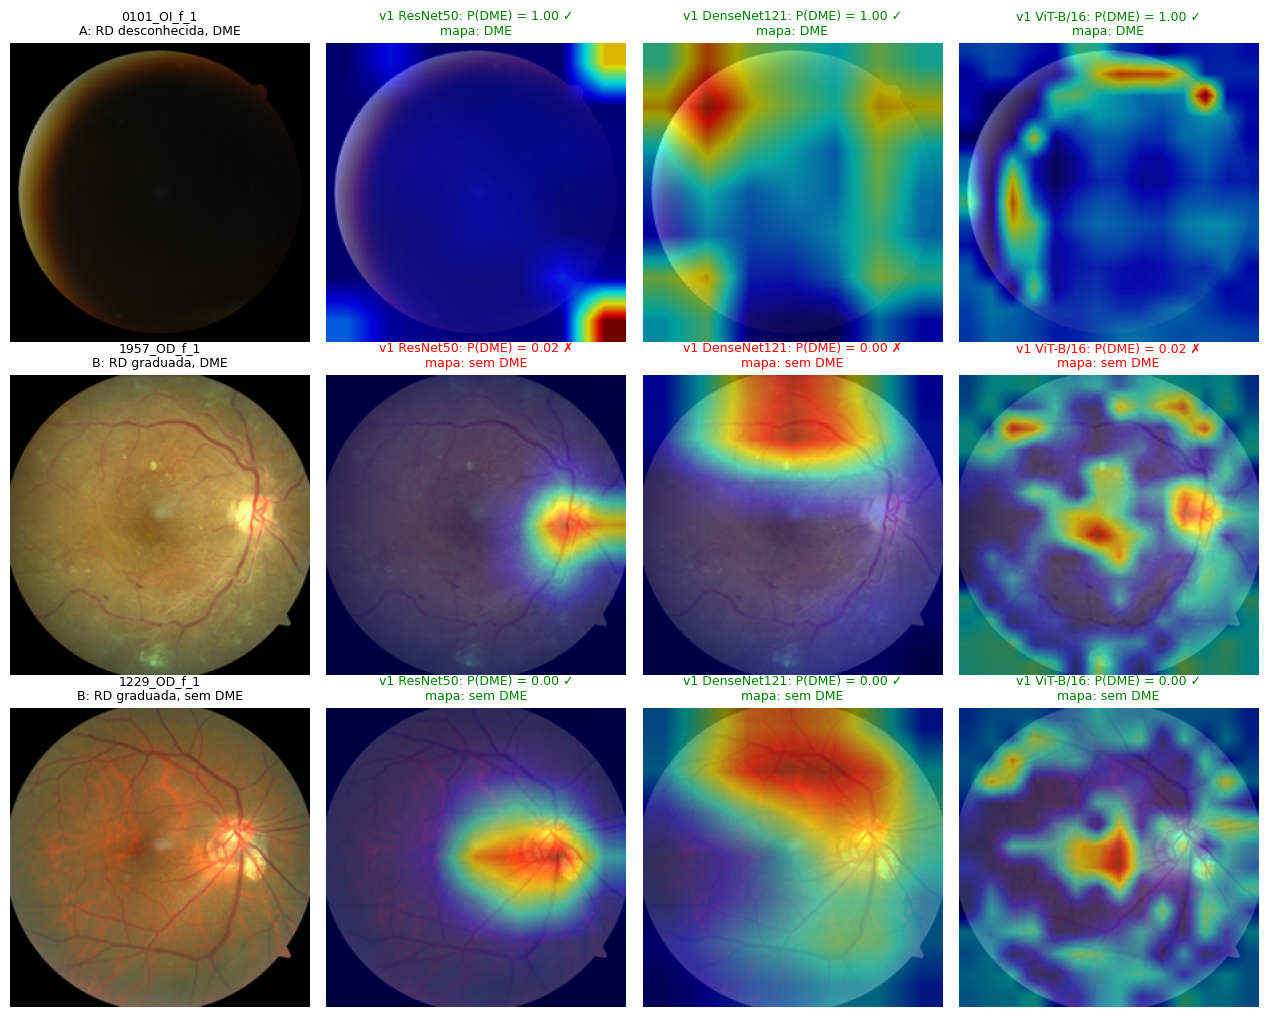

In [ ]:
if modelos_v1:
    casos = [teste_v1[(teste_v1.coorte.str.startswith('A')) & (teste_v1.DME == 1)].iloc[0],
             teste_v1[(teste_v1.coorte.str.startswith('B')) & (teste_v1.DME == 1)].iloc[0],
             teste_v1[(teste_v1.coorte.str.startswith('B')) & (teste_v1.DME == 0)].iloc[0]]
    fig, axes = plt.subplots(len(casos), 1 + len(modelos_v1), figsize=(3.2 * (1 + len(modelos_v1)), 3.4 * len(casos)))
    for i, r in enumerate(casos):
        img = Image.open(r['caminho']).convert('RGB').resize((IMG, IMG))
        base = np.asarray(img).astype(np.float32) / 255
        axes[i, 0].imshow(img); axes[i, 0].axis('off')
        axes[i, 0].set_title(f"{r['Name']}\n{r['coorte']}, {'DME' if r['DME'] else 'sem DME'}", fontsize=9)
        for j, (arq, m) in enumerate(modelos_v1.items()):
            mapa, p, classe = gradcam(m, arq, tf_v1(img))
            ok = (p >= .5) == bool(r['DME'])
            axes[i, j + 1].imshow(show_cam_on_image(base, mapa, use_rgb=True)); axes[i, j + 1].axis('off')
            axes[i, j + 1].set_title(f"v1 {NOME[arq]}: P(DME) = {p:.2f} {'✓' if ok else '✗'}\n"
                                     f"mapa: {'DME' if classe == 1 else 'sem DME'}",
                                     fontsize=9, color='green' if ok else 'red')
    plt.tight_layout(); plt.savefig(os.path.join(SAIDA, 'figuras', 'gradcam_v1_atalho.png'), dpi=150); plt.show()
else:
    print('Modelos da v1 não carregados: execute a Seção 2.4.')

### Interpretação: evidência visual do aprendizado por atalho

A figura evidencia que os modelos da primeira versão baseavam suas decisões, ao menos em parte, nas **características de aquisição** das imagens, e não no edema:

**Coorte A com edema (0101_OI_f_1):** a imagem está **praticamente sem iluminação**, sem estruturas da retina visíveis, de modo que o diagnóstico seria impossível mesmo para um especialista. Ainda assim, **as três redes atribuíram 100% de probabilidade de edema**. Os mapas de atenção concentram-se nos **cantos e na borda escura** da imagem, fora da retina.

**Coorte B com edema (1957_OD_f_1):** imagem de boa qualidade, com **exsudatos visíveis**. **As três redes classificaram incorretamente o olho como sem edema**, com probabilidades entre 0% e 2%.

**Coorte B sem edema (1229_OD_f_1):** as três redes acertaram, com atenção na região entre o disco óptico e a mácula.

O contraste entre os dois primeiros casos (**certeza máxima em uma imagem sem informação clínica** e **erro em uma imagem com lesões visíveis**) demonstra que os modelos da primeira versão aprenderam a associar o **aspecto da imagem** (escura ou clara) à presença de edema. Esse resultado confirma visualmente o viés de coorte identificado na Seção 2 e justifica a restrição dos experimentos à coorte B.

## 9. Comparação com a literatura

### Detecção do edema macular diabético

| Estudo | Entrada | AUC |
|---|---|---|
| Este trabalho, v1 (base completa) | Retinografia | 0,994 a 0,997 |
| Este trabalho, "apenas cor" (base completa) | Histograma de cor | 0,985 |
| **Este trabalho (coorte B)** | **Retinografia** | **0,941 a 0,962** |
| **Este trabalho (subgrupo 1957–2056)** | **Retinografia** | **0,823 a 0,901** |
| **Este trabalho (coorte B)** | **OCT** | **0,988 a 0,992** |
| **Este trabalho (olhos pareados)** | **Fusão tardia** | **0,978 a 0,984** |
| Hughes-Cano et al., 2024 | OCT | 0,96 |
| Hughes-Cano et al., 2024 | Retinografia | acima de 0,80 |
| Hughes-Cano et al., 2024 | OCT + retinografia | 0,94 |
| Varadarajan et al., 2020 | Retinografia | 0,89 |
| Arellano e Orlando, 2025 | Retinografia | 0,90 a 0,94 |

**Detalhes dos estudos:**

- **Hughes-Cano et al., 2024** (autores da base utilizada neste trabalho): utilizaram a rede OpticNet-71 para OCT (AUC 0,96 e F1 0,93) e a DenseNet-201 para retinografia, cujas métricas foram relatadas apenas como "acima de 0,8". A combinação de OCT e retinografia, com pesos de 60% e 40%, obteve AUC 0,94 e F1 0,90.
  - Nesse estudo, as retinografias sem edema foram reunidas a partir de bases de outras instituições (MESSIDOR e outras), o que pode introduzir diferenças de aquisição entre as classes semelhantes às identificadas na Seção 2.

- **Varadarajan et al., 2020** (*Nature Communications*): rede treinada com retinografias, mas com **rótulos de edema definidos pela OCT**, em mais de 6.000 imagens. Obteve AUC 0,89. Especialistas em retina, avaliando apenas a retinografia, apresentaram sensibilidade de 82% a 85% e especificidade de 45% a 50%.
  - Esse estudo mostra outra forma pela qual a OCT pode auxiliar a retinografia: **fornecendo um diagnóstico mais preciso para o treinamento**.

- **Arellano e Orlando, 2025** (modelos de fundação): modelos treinados em outras bases (IDRiD e MESSIDOR-2) e testados nesta base como **validação externa**, com AUC entre 0,90 e 0,94.
  - Esse estudo utilizou a base completa, incluindo a coorte A; o efeito do viés de coorte nesse cenário não foi avaliado.

### Graduação da retinopatia diabética

**Com retinografia:**

| Estudo | Rede | Kappa quadrático | AUC (qualquer RD) |
|---|---|---|---|
| **Este trabalho (3 níveis)** | **ResNet50** | **0,616** | **0,887** |
| **Este trabalho (3 níveis)** | **DenseNet121** | **0,676** | **0,878** |
| **Este trabalho (3 níveis)** | **ViT-B/16** | **0,679** | **0,915** |
| Rady et al., 2026 (5 níveis) | ResNet50 | 0,774 | 0,982 |
| Rady et al., 2026 (5 níveis) | DenseNet121 | 0,799 | 0,986 |

**Rady et al., 2026** (*International Journal of Retina and Vitreous*): estudo utilizado como referência para a escolha das métricas deste trabalho. Compararam oito redes convolucionais, incluindo ResNet50 e DenseNet121, na graduação da retinopatia em **cinco níveis** (escala ICDR) e na triagem binária (com e sem retinopatia), utilizando **3.500 retinografias** da base APTOS 2019.

- Na graduação em cinco níveis, a acurácia balanceada foi de 0,578 (DenseNet121) e 0,576 (ResNet50), e a maior parte dos erros ocorreu entre graus vizinhos.
- Na triagem binária, a sensibilidade foi de 0,946 (DenseNet121) e 0,941 (ResNet50).
- Os hiperparâmetros foram **fixos** (taxa de aprendizado de 0,0001 e, no ajuste fino, 0,00001; lote de 32 imagens; interrupção antecipada com paciência de 8 épocas), sem busca sistemática.

**Diferenças em relação a este trabalho:**

- **Número de níveis:** cinco níveis em Rady et al. e três neste trabalho, o que limita a comparação direta do Kappa quadrático.
- **Tamanho da base:** 3.500 imagens em Rady et al. e 545 retinografias na coorte B deste trabalho.
- **Divisão dos dados:** em Rady et al., a divisão foi feita **por imagem**, pois a base APTOS não identifica os pacientes. Imagens do mesmo paciente podem, portanto, estar presentes no treino e no teste, o que tende a elevar os resultados. Neste trabalho, a divisão foi feita **por paciente**.
- Rady et al. não avaliam o edema macular, a OCT ou arquiteturas baseadas em *transformers*.

**Com OCT:**

| Estudo | Tipo de imagem | Níveis | Resultado |
|---|---|---|---|
| **Este trabalho** | **Um corte (B-scan) da mácula** | **3** | **Kappa quadrático de 0,552 a 0,642** |
| Zang et al., 2020 | OCT estrutural e angiografia por OCT (OCTA), em imagens de frente (*en face*) | 3 | Acurácia de 85,0% |
| Ryu et al., 2022 | Apenas OCTA | 6 | Kappa quadrático de 0,908 |

- Os estudos que obtêm bom desempenho na graduação da retinopatia com OCT utilizam a **angiografia por OCT (OCTA)**, que mostra os **vasos** da retina, onde ocorrem as principais alterações da retinopatia, e imagens que cobrem **uma área da retina**, e não um único corte.
- A base utilizada neste trabalho contém apenas **um corte da região macular** por imagem, o que limita a informação disponível para a graduação. Isso ajuda a explicar por que, mesmo com hiperparâmetros ajustados, a OCT foi inferior à retinografia nesta tarefa (Seção 7.6).
- **ElTanboly et al., 2018** mostraram, em 26 pacientes diabéticos **sem retinopatia visível** e 26 controles, que a espessura e a refletividade de algumas camadas da retina já diferem entre os grupos. Esse resultado indica que a OCT pode conter sinais de **alterações precoces**, anteriores às lesões visíveis na retinografia, uma direção relevante para trabalhos futuros voltados à detecção inicial.

### Síntese

- **Edema, retinografia:** a AUC na coorte B (0,941 a 0,962) ficou próxima do limite superior do patamar descrito na literatura (0,85 a 0,95). No subgrupo da análise de robustez (Seção 7.8), cenário mais rigoroso, a AUC foi de **0,823 a 0,901**, dentro ou próxima desse patamar. Ambos os resultados estão muito abaixo dos valores inflados da primeira versão (acima de 0,99).
- **Edema, OCT e fusão:** o desempenho da OCT (0,988 a 0,992) e da fusão tardia (0,978 a 0,984) foi superior ao relatado por Hughes-Cano et al. (0,96 e 0,94, respectivamente) na mesma base, embora com protocolos de divisão e conjuntos de imagens diferentes.
- **Graduação com retinografia:** os valores de Kappa quadrático (0,616 a 0,679) e de AUC para qualquer retinopatia (0,878 a 0,915) foram inferiores aos de Rady et al. Essa diferença é compatível com a base menor e com a divisão por paciente adotada neste trabalho, mais rigorosa.
- **Graduação com OCT:** o desempenho inferior ao da literatura é compatível com o tipo de imagem disponível (um corte macular, sem angiografia).

## 10. Limitações

**Tamanho da amostra**

- A coorte B contém apenas **54 retinografias com edema** e **51 olhos pareados com edema** (de 410). Por isso, os intervalos de confiança são largos, e diferenças pequenas entre abordagens não podem ser confirmadas estatisticamente.
- O conjunto de validação de cada rodada é pequeno, o que torna menos precisa a escolha dos hiperparâmetros e do momento de interrupção do treinamento.
- Foram realizadas várias comparações simultâneas (Seções 7.4 e 7.9). Resultados significativos isolados devem ser interpretados com cautela; por isso, foram valorizados apenas os resultados consistentes entre as três arquiteturas.
- Cada rede foi treinada **uma única vez** em cada rodada, com uma semente aleatória fixa. A variação decorrente de diferentes inicializações não foi avaliada.

**Desbalanceamento das classes**

- O desbalanceamento (cerca de 1 retinografia com edema para cada 9 sem edema) foi tratado apenas com **pesos nas classes da função de perda**. Outras estratégias, como sobreamostragem da classe minoritária, *focal loss* ou ajuste do limiar de decisão, não foram comparadas.

**Vieses residuais**

- Mesmo dentro da coorte B, algumas retinografias com edema apresentam **artefatos de captura** (Seção 2.2), e o classificador baseado apenas em cor obteve AUC de 0,785 (Seção 4.1).
- Na coorte B, os olhos sem retinopatia concentram-se nos pacientes 1221 a 1500, enquanto a maioria dos casos com retinopatia e com edema pertence aos pacientes 1957 a 2056. A **análise de robustez** (Seção 7.8), restrita a esse último grupo, mostrou que:
  - a detecção do edema e a contribuição da OCT **se mantêm**, mas a AUC da retinografia é menor (0,823 a 0,901) do que na coorte B completa (0,941 a 0,962);
  - a graduação em três níveis apresenta **queda do Kappa quadrático** (retinografia: 0,470 a 0,655; OCT: 0,421 a 0,512), e a vantagem do ViT-B/16 observada na coorte B completa **não se confirma**.
- Portanto, os valores obtidos na coorte B completa provavelmente **superestimam** o desempenho da retinografia, e os resultados do subgrupo são a estimativa mais conservadora.

**Métodos**

- O ***grid search*** (Seção 5.3) avaliou apenas a **taxa de aprendizado** e o **tamanho do lote**, em **duas rodadas** e com no máximo **10 épocas** por treinamento, para limitar o custo computacional. Outros hiperparâmetros (otimizador, regularização, aumento de dados, resolução da imagem) foram mantidos fixos.
- Na comparação **com e sem pré-processamento** (Seção 7.9), os hiperparâmetros foram escolhidos com as imagens pré-processadas, o que pode favorecer levemente essa condição. Mesmo assim, o pré-processamento não trouxe benefício consistente.
- A **fusão intermediária** utilizou uma taxa de aprendizado derivada das escolhidas para cada modalidade, sem *grid search* próprio.
- A **destilação de conhecimento** (OCT → retinografia) foi avaliada em uma única configuração (temperatura 2 e peso 0,5). Outras configurações ou estratégias de transferência podem apresentar resultados diferentes.
- O **Grad-CAM produziu mapas difusos no ViT-B/16**. Por ter sido desenvolvido para redes convolucionais, esse método é menos adequado a *transformers*; métodos específicos, como o *attention rollout*, não foram avaliados.
- A análise dos mapas de atenção foi ilustrativa, com apenas dois olhos, sem avaliação sistemática por especialista.

**Características da base de dados**

- O diagnóstico de edema é o mesmo nas duas modalidades de um mesmo olho, o que sugere um diagnóstico único por olho, possivelmente apoiado na OCT. Isso pode favorecer a OCT como modalidade de referência.
- Cada OCT da base é **um único corte (B-scan) da região macular**, sem angiografia por OCT nem imagens de frente (*en face*). Esse tipo de imagem limita a graduação da retinopatia pela OCT, pois as principais alterações da doença ocorrem nos vasos e fora da mácula (Seção 9).
- A graduação da retinopatia tem apenas três níveis (sem retinopatia, não proliferativa e proliferativa), sem a subdivisão da forma não proliferativa em leve, moderada e grave.
- A base não contém informações sobre o tipo de diabetes, tempo de doença ou exames laboratoriais.

**Validação**

- Todos os resultados foram obtidos em uma única base de dados. Não foi realizada validação externa em bases independentes.

**Próximos passos**

- Validação externa em bases públicas, como IDRiD e MESSIDOR-2, para a detecção do edema em retinografias.
- Repetição dos treinamentos com diferentes sementes aleatórias, para estimar a variabilidade dos resultados.
- Comparação de outras estratégias para o desbalanceamento das classes.
- Avaliação sistemática dos mapas de atenção com a participação de um oftalmologista, incluindo métodos específicos para o ViT-B/16.
- Para a detecção precoce da retinopatia com OCT, avaliar bases com **angiografia por OCT** ou com **vários cortes por olho**, e medidas das camadas da retina, como sugerem Zang et al. (2020), Ryu et al. (2022) e ElTanboly et al. (2018).

## Referências

1. HUGHES-CANO, J. A. et al. Improved predictive diagnosis of diabetic macular edema based on hybrid models: an observational study. *Computers in Biology and Medicine*, v. 170, p. 107979, 2024. DOI: 10.1016/j.compbiomed.2024.107979.

2. VARADARAJAN, A. V. et al. Predicting optical coherence tomography-derived diabetic macular edema grades from fundus photographs using deep learning. *Nature Communications*, v. 11, p. 130, 2020. DOI: 10.1038/s41467-019-13922-8.

3. RADY, A. M. N. A.; AZIM, M. A.; ABDELMOETY, A.; AHMED, M. A. Automated diabetic retinopathy grading and screening using deep learning. *International Journal of Retina and Vitreous*, v. 12, p. 96, 2026. DOI: 10.1186/s40942-026-00868-5.

4. ARELLANO, F. J.; ORLANDO, J. I. Evaluating fundus-specific foundation models for diabetic macular edema detection. *arXiv*, 2510.07277, 2025.

5. WANG, L. et al. MultiEYE: dataset and benchmark for OCT-enhanced retinal disease recognition from fundus images. *arXiv*, 2412.09402, 2024.

6. DOSOVITSKIY, A. et al. An image is worth 16x16 words: Transformers for image recognition at scale. In: *International Conference on Learning Representations (ICLR)*, 2021.

7. SELVARAJU, R. R. et al. Grad-CAM: visual explanations from deep networks via gradient-based localization. In: *IEEE International Conference on Computer Vision (ICCV)*, 2017.

8. GEIRHOS, R. et al. Shortcut learning in deep neural networks. *Nature Machine Intelligence*, v. 2, p. 665-673, 2020.

9. TRANSLATIONAL VISUAL HEALTH LABORATORY. OCT-AND-EYE-FUNDUS-DATASET: Dataset of eye fundus and OCT images for the study of diabetic macular edema and diabetic retinopathy. GitHub. Disponível em: https://github.com/Traslational-Visual-Health-Laboratory/OCT-AND-EYE-FUNDUS-DATASET.

10. SOCIEDADE BRASILEIRA DE DIABETES. Diretriz da Sociedade Brasileira de Diabetes: diagnóstico de diabetes mellitus. Disponível em: https://diretriz.diabetes.org.br/diagnostico-de-diabetes-mellitus/.

11. AMERICAN DIABETES ASSOCIATION. Diagnosis and classification of diabetes: Standards of Care in Diabetes—2026. *Diabetes Care*, v. 49, supl. 1, p. S27, 2026.

12. ZANG, P. et al. DcardNet: diabetic retinopathy classification at multiple levels based on structural and angiographic optical coherence tomography. *arXiv*, 2006.05480, 2020.

13. RYU, G. et al. A deep learning algorithm for classifying diabetic retinopathy using optical coherence tomography angiography. *Translational Vision Science & Technology*, v. 11, n. 2, p. 39, 2022. DOI: 10.1167/tvst.11.2.39.

14. ELTANBOLY, A. H. et al. An automated approach for early detection of diabetic retinopathy using SD-OCT images. *Frontiers in Bioscience-Elite*, v. 10, n. 2, p. 197-207, 2018. DOI: 10.2741/E817.